In [ ]:
import os

PROJECT_DIR = "/content/drive/MyDrive/ShopGuard_AI"
os.makedirs(PROJECT_DIR + "/data", exist_ok=True)     # your collected typing data
os.makedirs(PROJECT_DIR + "/models", exist_ok=True)   # your saved trained model
os.makedirs(PROJECT_DIR + "/results", exist_ok=True)  # charts and screenshots for your report

print(os.listdir(PROJECT_DIR))

['models', 'data', 'results']


In [ ]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import HTML, JSON, display
from google.colab import output

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [ ]:
import os
BASE = "/content/drive/MyDrive/fake_store_detector"
os.makedirs(BASE + "/data", exist_ok=True)
os.makedirs(BASE + "/models", exist_ok=True)
os.makedirs(BASE + "/results", exist_ok=True)
print(os.listdir(BASE))

['data', 'models', 'results']


In [ ]:
import os
DATA_DIR = "/content/drive/MyDrive/fake_store_detector/data"
print(os.listdir(DATA_DIR))


['Fraudulent_online_shops_dataset.csv']


In [ ]:
import pandas as pd

df = pd.read_csv(DATA_DIR + "/Fraudulent_online_shops_dataset.csv")
df.head()

,Online shop URL,Label,Domain length,Top domain length,Presence of prefix 'www',Number of digits,Number of letters,Number of dots (.),Number of hyphens (-),Presence of credit card payment,...,SSL certificate expire date,Issuer organization,SSL certificate issuer organization list item,Indication of young domain,Domain registration date,Presence of TrustPilot reviews,TrustPilot score,Presence of SiteJabber reviews,Presence in the standard Tranco list,Tranco List rank
0,https://www.allaccessorybest.com,fraudulent,24,3,1,0,27,2,0,1,...,Oct 11 03:53:36 2023 GMT,Google Trust Services LLC,9,1,2023-05-15 03:35,0,NaN,0,0,-1
1,https://www.b-watches.shop,fraudulent,18,4,1,0,20,2,1,0,...,Jun 16 23:59:59 2024 GMT,"Cloudflare, Inc.",1,1,2023-06-18 05:43,0,NaN,0,0,-1
2,https://www.waeschenamen-windrath.de,legitimate,28,2,1,0,30,2,1,1,...,Oct 24 21:53:20 2023 GMT,Let's Encrypt,2,2,Hidden,0,-1.0,0,0,-1
3,https://vendoprint.se,legitimate,13,2,0,0,17,1,0,1,...,Oct 9 15:13:00 2023 GMT,Google Trust Services LLC,9,1,2022-09-20 00:00,0,-1.0,0,0,-1
4,https://www.newbikeland.com,fraudulent,19,3,1,0,22,2,0,1,...,Oct 25 08:20:27 2023 GMT,Let's Encrypt,2,1,2023-07-27 09:05,0,NaN,0,0,-1


In [ ]:
print(df.columns.tolist())

['Online shop URL', 'Label', 'Domain length', 'Top domain length', "Presence of prefix 'www' ", 'Number  of digits', 'Number  of letters', 'Number  of dots (.)', 'Number  of hyphens (-)', 'Presence of credit card payment', 'Presence of money back payment', 'Presence of cash on delivery payment', 'Presence of crypto currency', 'Presence of free contact emails', 'Presence of logo URL', 'SSL certificate issuer', 'SSL certificate expire date', 'Issuer organization', 'SSL certificate issuer organization list item', 'Indication of young domain ', 'Domain registration date', 'Presence of TrustPilot reviews', 'TrustPilot score', 'Presence of SiteJabber reviews', 'Presence in the standard Tranco list', 'Tranco List rank']


In [ ]:
print("\missing values :")
print(df.isna().sum())
print("\nduplicates:", df.duplicated().sum())

\missing values :
Online shop URL                                    0
Label                                              0
Domain length                                      0
Top domain length                                  0
Presence of prefix 'www'                           0
Number  of digits                                  0
Number  of letters                                 0
Number  of dots (.)                                0
Number  of hyphens (-)                             0
Presence of credit card payment                    0
Presence of money back payment                     0
Presence of cash on delivery payment               0
Presence of crypto currency                        0
Presence of free contact emails                    0
Presence of logo URL                               0
SSL certificate issuer                             0
SSL certificate expire date                        0
Issuer organization                                0
SSL certificate issuer organ

<>:1: SyntaxWarning: invalid escape sequence '\m'
<>:1: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_715/3703150924.py:1: SyntaxWarning: invalid escape sequence '\m'
  print("\missing values :")


In [ ]:
print("Label counts:")
print(df["Label"].value_counts(dropna=False))

print("\nLabel proportions:")
print(df["Label"].value_counts(normalize=True).mul(100).round(1))

print("\nSample rows (selected columns):")
display(df[["Online shop URL", "Label", "Domain length",
            "Presence of credit card payment",
            "Presence of cash on delivery payment",
            "Indication of young domain ",
            "TrustPilot score", "Tranco List rank"]].head(10))

print("\nNumeric summary:")
display(df.describe().T)

print("\nText column summary:")
for c in df.select_dtypes(include="object").columns:
    print(c, "| unique:", df[c].nunique(), "| examples:", df[c].dropna().unique()[:3].tolist())

Label counts:
Label
fraudulent    579
legitimate    561
Name: count, dtype: int64

Label proportions:
Label
fraudulent    50.8
legitimate    49.2
Name: proportion, dtype: float64

Sample rows (selected columns):


,Online shop URL,Label,Domain length,Presence of credit card payment,Presence of cash on delivery payment,Indication of young domain,TrustPilot score,Tranco List rank
0,https://www.allaccessorybest.com,fraudulent,24,1,0,1,NaN,-1
1,https://www.b-watches.shop,fraudulent,18,0,0,1,NaN,-1
2,https://www.waeschenamen-windrath.de,legitimate,28,1,0,2,-1.0,-1
3,https://vendoprint.se,legitimate,13,1,0,1,-1.0,-1
4,https://www.newbikeland.com,fraudulent,19,1,0,1,NaN,-1
5,https://www.hats-storeofficial.com,fraudulent,26,1,1,1,NaN,-1
6,https://balaganstudio.com,legitimate,17,1,1,0,3.2,-1
7,https://www.bootscleaner.com,legitimate,20,1,0,1,3.7,-1
8,https://shop.tovarseasycleaning.com,legitimate,27,1,0,0,-1.0,-1
9,https://camerabebelusului.ro,legitimate,20,0,0,0,4.5,-1



Numeric summary:


,count,mean,std,min,25%,50%,75%,max
Domain length,1140.0,18.341228,4.512033,7.0,15.0,19.0,21.00,38.0
Top domain length,1140.0,2.851754,0.741322,2.0,2.0,3.0,3.00,13.0
Presence of prefix 'www',1140.0,0.665789,0.471921,0.0,0.0,1.0,1.00,1.0
Number of digits,1140.0,0.070175,0.395748,0.0,0.0,0.0,0.00,4.0
Number of letters,1140.0,21.654386,4.307723,11.0,19.0,22.0,24.25,39.0
Number of dots (.),1140.0,1.708772,0.495203,1.0,1.0,2.0,2.00,3.0
Number of hyphens (-),1140.0,0.157895,0.403648,0.0,0.0,0.0,0.00,4.0
Presence of credit card payment,1140.0,0.763158,0.425331,0.0,1.0,1.0,1.00,1.0
Presence of money back payment,1140.0,0.713158,0.452486,0.0,0.0,1.0,1.00,1.0
Presence of cash on delivery payment,1140.0,0.238596,0.426413,0.0,0.0,0.0,0.00,1.0



Text column summary:
Online shop URL | unique: 1140 | examples: ['https://www.allaccessorybest.com', 'https://www.b-watches.shop', 'https://www.waeschenamen-windrath.de']
Label | unique: 2 | examples: ['fraudulent', 'legitimate']
SSL certificate issuer | unique: 43 | examples: ['GTS CA 1P5', 'Cloudflare Inc ECC CA-3', 'R3']
SSL certificate expire date | unique: 1065 | examples: ['Oct 11 03:53:36 2023 GMT', 'Jun 16 23:59:59 2024 GMT', 'Oct 24 21:53:20 2023 GMT']
Issuer organization | unique: 18 | examples: ['Google Trust Services LLC', 'Cloudflare, Inc.', "Let's Encrypt"]
Domain registration date | unique: 943 | examples: ['2023-05-15 03:35', '2023-06-18 05:43', 'Hidden']


In [ ]:
print(df[["Online shop URL","Label","Domain length","Presence of credit card payment","Presence of cash on delivery payment","Indication of young domain ","TrustPilot score","Tranco List rank"]].head(8).to_string(index=False))
print("\nNumeric describe:\n", df.describe().round(2).to_string())
print("\nBinary-like columns:")
for c in df.columns:
    vals=df[c].dropna().unique()
    if len(vals)<=3:
        print(repr(c), sorted(map(str, vals)))


                     Online shop URL      Label  Domain length  Presence of credit card payment  Presence of cash on delivery payment  Indication of young domain   TrustPilot score  Tranco List rank
    https://www.allaccessorybest.com fraudulent             24                                1                                     0                            1               NaN                -1
          https://www.b-watches.shop fraudulent             18                                0                                     0                            1               NaN                -1
https://www.waeschenamen-windrath.de legitimate             28                                1                                     0                            2              -1.0                -1
               https://vendoprint.se legitimate             13                                1                                     0                            1              -1.0                -1
     

In [ ]:
df.head()

,Online shop URL,Label,Domain length,Top domain length,Presence of prefix 'www',Number of digits,Number of letters,Number of dots (.),Number of hyphens (-),Presence of credit card payment,...,SSL certificate expire date,Issuer organization,SSL certificate issuer organization list item,Indication of young domain,Domain registration date,Presence of TrustPilot reviews,TrustPilot score,Presence of SiteJabber reviews,Presence in the standard Tranco list,Tranco List rank
0,https://www.allaccessorybest.com,fraudulent,24,3,1,0,27,2,0,1,...,Oct 11 03:53:36 2023 GMT,Google Trust Services LLC,9,1,2023-05-15 03:35,0,NaN,0,0,-1
1,https://www.b-watches.shop,fraudulent,18,4,1,0,20,2,1,0,...,Jun 16 23:59:59 2024 GMT,"Cloudflare, Inc.",1,1,2023-06-18 05:43,0,NaN,0,0,-1
2,https://www.waeschenamen-windrath.de,legitimate,28,2,1,0,30,2,1,1,...,Oct 24 21:53:20 2023 GMT,Let's Encrypt,2,2,Hidden,0,-1.0,0,0,-1
3,https://vendoprint.se,legitimate,13,2,0,0,17,1,0,1,...,Oct 9 15:13:00 2023 GMT,Google Trust Services LLC,9,1,2022-09-20 00:00,0,-1.0,0,0,-1
4,https://www.newbikeland.com,fraudulent,19,3,1,0,22,2,0,1,...,Oct 25 08:20:27 2023 GMT,Let's Encrypt,2,1,2023-07-27 09:05,0,NaN,0,0,-1


In [ ]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("Shape:", df.shape)

Rows: 1140
Columns: 26
Shape: (1140, 26)


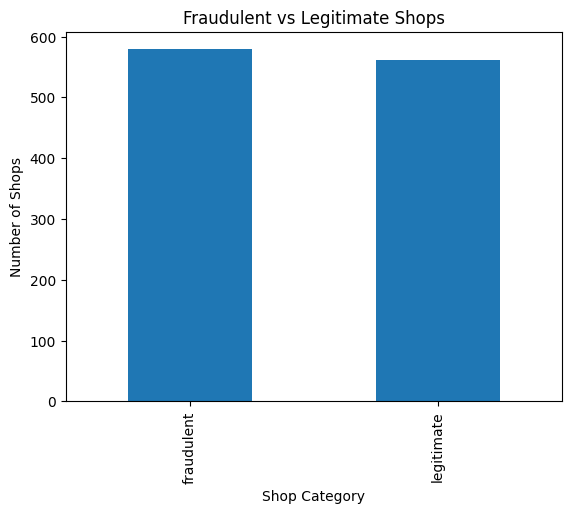

In [ ]:
import matplotlib.pyplot as plt
df['Label'].value_counts().plot(
    kind='bar',
    title='Fraudulent vs Legitimate Shops'
)

plt.xlabel('Shop Category')
plt.ylabel('Number of Shops')
plt.show()

In [ ]:
df['Label'].value_counts(normalize=True)*100
df.describe()

,Domain length,Top domain length,Presence of prefix 'www',Number of digits,Number of letters,Number of dots (.),Number of hyphens (-),Presence of credit card payment,Presence of money back payment,Presence of cash on delivery payment,Presence of crypto currency,Presence of free contact emails,Presence of logo URL,SSL certificate issuer organization list item,Indication of young domain,Presence of TrustPilot reviews,TrustPilot score,Presence of SiteJabber reviews,Presence in the standard Tranco list,Tranco List rank
count,1140.000000,1140.000000,1140.000000,1140.000000,1140.000000,1140.000000,1140.000000,1140.000000,1140.000000,1140.000000,1140.000000,1140.000000,1140.00000,1140.000000,1140.000000,1140.000000,580.000000,1140.000000,1140.000000,1140.000000
mean,18.341228,2.851754,0.665789,0.070175,21.654386,1.708772,0.157895,0.763158,0.713158,0.238596,0.035088,1.053509,0.82193,4.570175,0.620175,0.223684,1.014828,0.038596,0.015789,9710.771053
std,4.512033,0.741322,0.471921,0.395748,4.307723,0.495203,0.403648,0.425331,0.452486,0.426413,0.184082,1.114095,0.38274,3.336470,0.664235,0.416896,2.363742,0.192716,0.124715,84946.859868
min,7.000000,2.000000,0.000000,0.000000,11.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,1.000000,0.000000,0.000000,-1.000000,0.000000,0.000000,-1.000000
25%,15.000000,2.000000,0.000000,0.000000,19.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.00000,2.000000,0.000000,0.000000,-1.000000,0.000000,0.000000,-1.000000
50%,19.000000,3.000000,1.000000,0.000000,22.000000,2.000000,0.000000,1.000000,1.000000,0.000000,0.000000,1.000000,1.00000,2.000000,1.000000,0.000000,-1.000000,0.000000,0.000000,-1.000000
75%,21.000000,3.000000,1.000000,0.000000,24.250000,2.000000,0.000000,1.000000,1.000000,0.000000,0.000000,2.000000,1.00000,9.000000,1.000000,0.000000,3.600000,0.000000,0.000000,-1.000000
max,38.000000,13.000000,1.000000,4.000000,39.000000,3.000000,4.000000,1.000000,1.000000,1.000000,1.000000,3.000000,1.00000,11.000000,2.000000,1.000000,5.000000,1.000000,1.000000,964101.000000


In [ ]:
df['Indication of young domain '].value_counts()
df['Presence of free contact emails'].value_counts()

,count
Presence of free contact emails,
0,567
2,406
3,111
1,56


In [ ]:
df['Label'].value_counts()
df.describe()
df['Indication of young domain '].value_counts()
df['Presence of free contact emails'].value_counts()

,count
Presence of free contact emails,
0,567
2,406
3,111
1,56


In [ ]:
df['TrustPilot score'].value_counts(dropna=False).sort_index()
df['Indication of young domain '].value_counts().sort_index()

,count
Indication of young domain,
0,550
1,473
2,117


In [ ]:
pd.crosstab(
    df['Indication of young domain '],
    df['Label'],
    normalize='index'
) * 100


Label,fraudulent,legitimate
Indication of young domain,,
0,13.636364,86.363636
1,98.308668,1.691332
2,33.333333,66.666667


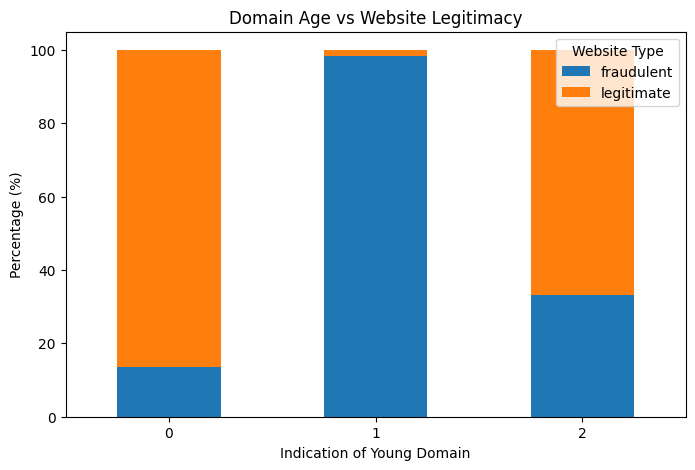

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

result = pd.crosstab(
    df['Indication of young domain '],
    df['Label'],
    normalize='index'
) * 100

result.plot(kind='bar', stacked=True, figsize=(8, 5))

plt.title('Domain Age vs Website Legitimacy')
plt.xlabel('Indication of Young Domain')
plt.ylabel('Percentage (%)')
plt.legend(title='Website Type')
plt.xticks(rotation=0)
plt.show()

In [ ]:
df.columns.tolist()

['Online shop URL',
 'Label',
 'Domain length',
 'Top domain length',
 "Presence of prefix 'www' ",
 'Number  of digits',
 'Number  of letters',
 'Number  of dots (.)',
 'Number  of hyphens (-)',
 'Presence of credit card payment',
 'Presence of money back payment',
 'Presence of cash on delivery payment',
 'Presence of crypto currency',
 'Presence of free contact emails',
 'Presence of logo URL',
 'SSL certificate issuer',
 'SSL certificate expire date',
 'Issuer organization',
 'SSL certificate issuer organization list item',
 'Indication of young domain ',
 'Domain registration date',
 'Presence of TrustPilot reviews',
 'TrustPilot score',
 'Presence of SiteJabber reviews',
 'Presence in the standard Tranco list',
 'Tranco List rank']

In [ ]:
pd.crosstab(
    df['Presence of free contact emails'],
    df['Label'],
    normalize='index'
) * 100

Label,fraudulent,legitimate
Presence of free contact emails,,
0,80.952381,19.047619
1,28.571429,71.428571
2,16.748768,83.251232
3,32.432432,67.567568


In [ ]:
df['Presence of SiteJabber reviews'].value_counts(dropna=False)
pd.crosstab(
    df['Presence of SiteJabber reviews'],
    df['Label'],
    normalize='index'
) * 100


Label,fraudulent,legitimate
Presence of SiteJabber reviews,,
0,52.737226,47.262774
1,2.272727,97.727273


In [ ]:

import pandas as pd

features = [
    'Domain length',
    'Top domain length',
    "Presence of prefix 'www' ",
    'Number  of digits',
    'Number  of letters',
    'Number  of dots (.)',
    'Number  of hyphens (-)',
    'Presence of credit card payment',
    'Presence of money back payment',
    'Presence of cash on delivery payment',
    'Presence of crypto currency',
    'Presence of logo URL',
    'SSL certificate issuer',
    'SSL certificate expire date',
    'Issuer organization',
    'SSL certificate issuer organization list item',
    'Domain registration date',
    'Presence in the standard Tranco list',
    'Tranco List rank'
]

for feature in features:

    print("\n" + "=" * 70)
    print("FEATURE:", feature)
    print("=" * 70)

    print("\nVALUE COUNTS:")
    print(df[feature].value_counts(dropna=False))

    print("\nRELATIONSHIP WITH LABEL (%):")

    print(
        pd.crosstab(
            df[feature],
            df['Label'],
            normalize='index'
        ) * 100
    )



FEATURE: Domain length

VALUE COUNTS:
Domain length
20    109
19    106
18    100
17     89
21     83
16     74
22     74
23     72
14     68
15     65
13     53
24     45
11     35
25     32
12     32
10     25
27     16
26     15
9      14
8       7
28      5
7       5
29      5
32      4
30      3
31      2
38      1
34      1
Name: count, dtype: int64

RELATIONSHIP WITH LABEL (%):
Label          fraudulent  legitimate
Domain length                        
7                0.000000  100.000000
8                0.000000  100.000000
9               21.428571   78.571429
10              28.000000   72.000000
11              11.428571   88.571429
12              31.250000   68.750000
13              22.641509   77.358491
14              22.058824   77.941176
15              43.076923   56.923077
16              28.378378   71.621622
17              47.191011   52.808989
18              44.000000   56.000000
19              55.660377   44.339623
20              73.394495   26.605505
21 

In [ ]:

missing = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Missing Percentage': (df.isnull().mean() * 100).round(2),
    'Data Type': df.dtypes
})

missing = missing.sort_values(
    by='Missing Percentage',
    ascending=False
)

print(missing)


                                               Missing Count  \
TrustPilot score                                         560   
Domain registration date                                   4   
Domain length                                              0   
Top domain length                                          0   
Presence of prefix 'www'                                   0   
Number  of digits                                          0   
Number  of letters                                         0   
Number  of dots (.)                                        0   
Online shop URL                                            0   
Label                                                      0   
Presence of credit card payment                            0   
Number  of hyphens (-)                                     0   
Presence of money back payment                             0   
Presence of cash on delivery payment                       0   
Presence of logo URL                    

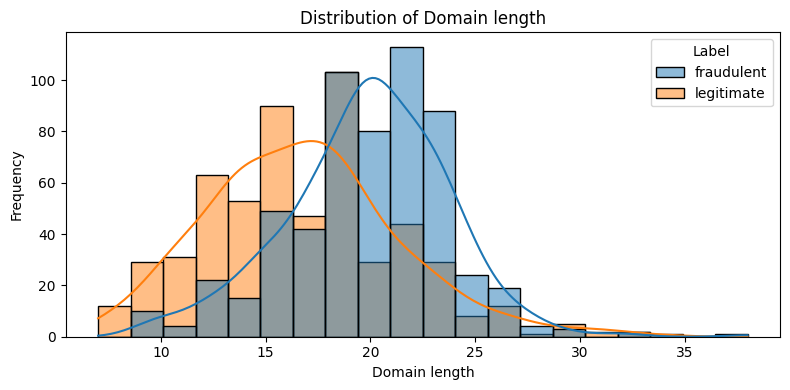

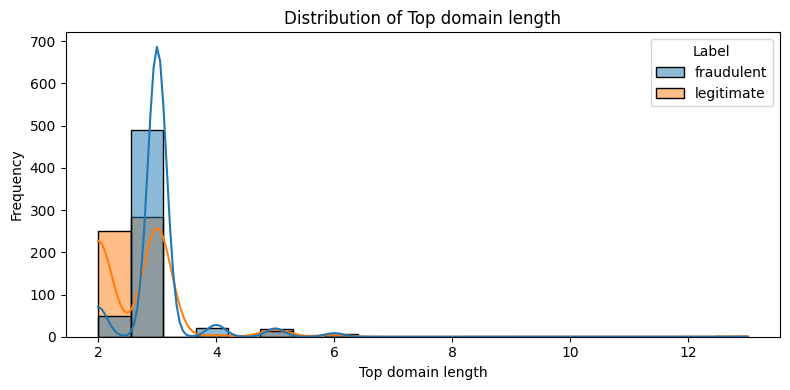

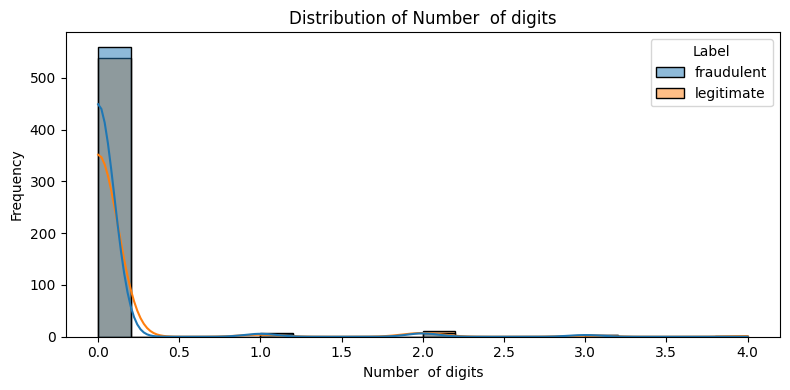

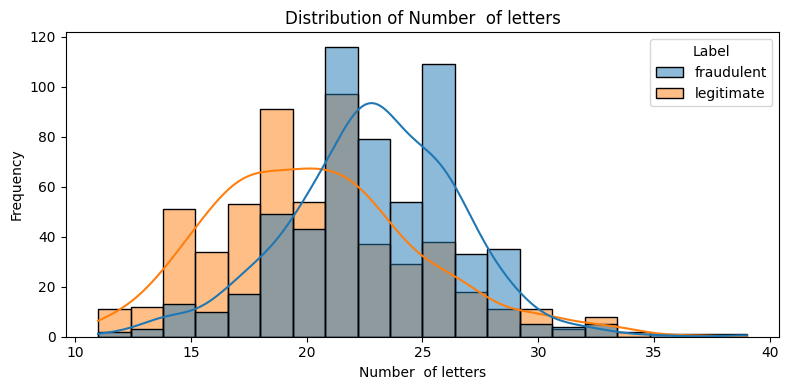

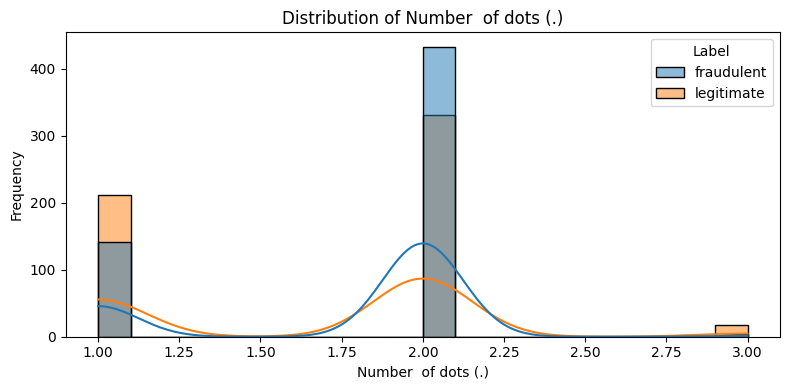

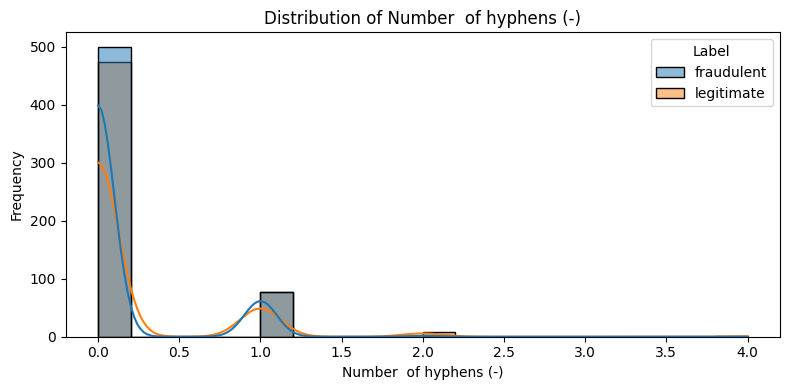

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

numerical_features = [
    'Domain length',
    'Top domain length',
    'Number  of digits',
    'Number  of letters',
    'Number  of dots (.)',
    'Number  of hyphens (-)'
]

for col in numerical_features:

    plt.figure(figsize=(8, 4))

    sns.histplot(
        data=df,
        x=col,
        hue='Label',
        bins=20,
        kde=True,
        alpha=0.5
    )

    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')

    plt.tight_layout()
    plt.show()

In [ ]:
df['Tranco List rank'].value_counts().head(15)

,count
Tranco List rank,
-1,1122
90036,1
802243,1
804620,1
35556,1
459343,1
825217,1
802653,1
682488,1


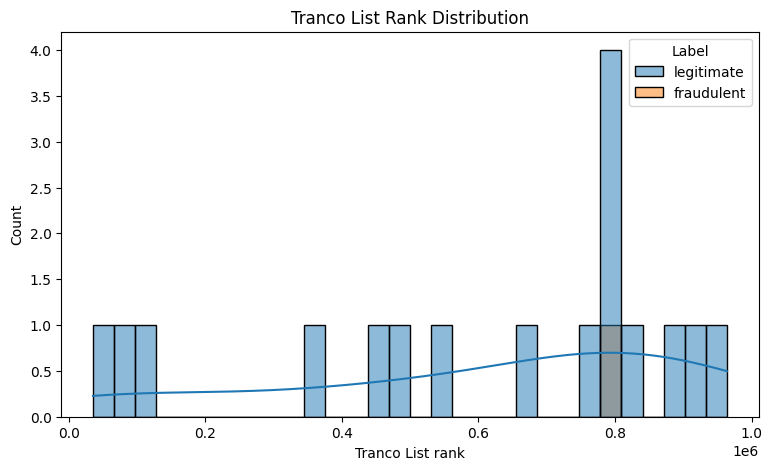

In [ ]:
tranco_valid = df[
    df['Tranco List rank'] != -1
]

plt.figure(figsize=(9, 5))

sns.histplot(
    data=tranco_valid,
    x='Tranco List rank',
    hue='Label',
    bins=30,
    kde=True
)

plt.title('Tranco List Rank Distribution')
plt.show()

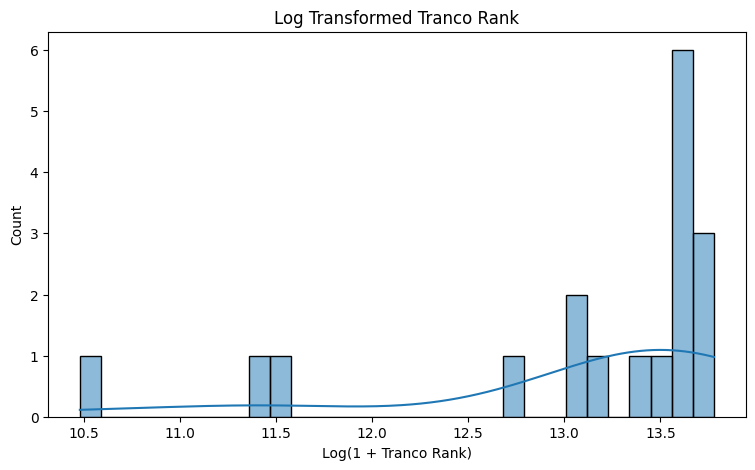

In [ ]:
import numpy as np

plt.figure(figsize=(9, 5))

sns.histplot(
    np.log1p(tranco_valid['Tranco List rank']),
    bins=30,
    kde=True
)

plt.title('Log Transformed Tranco Rank')
plt.xlabel('Log(1 + Tranco Rank)')
plt.show()

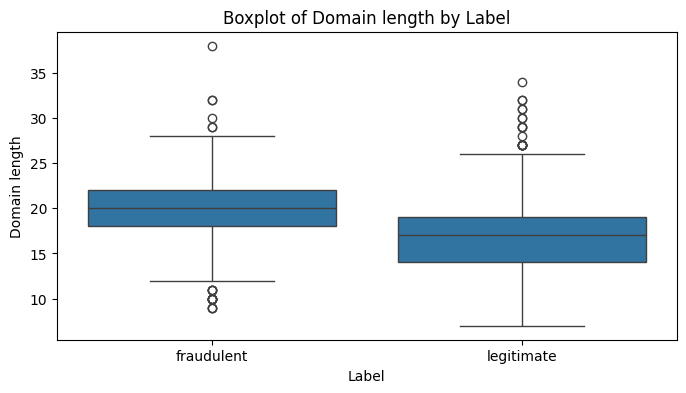

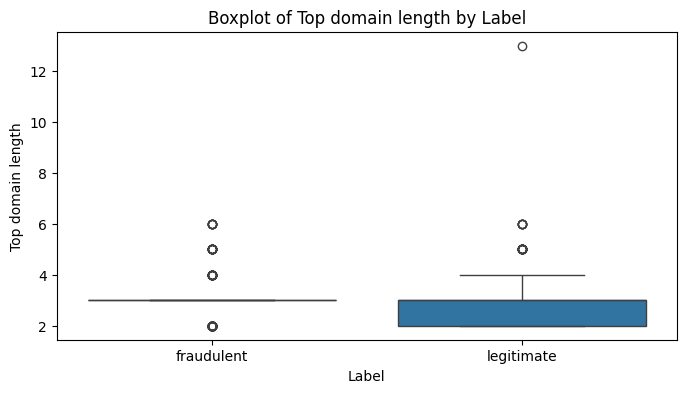

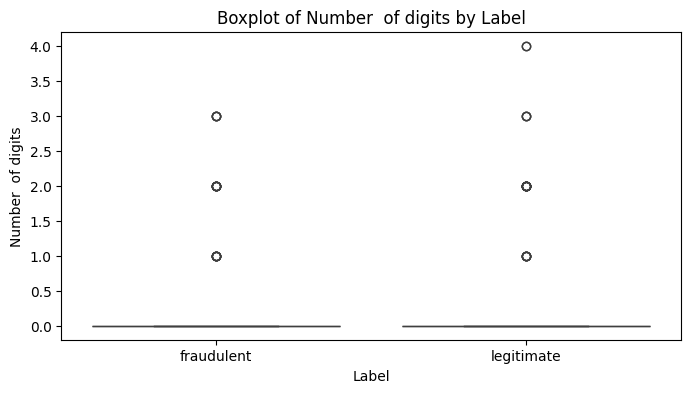

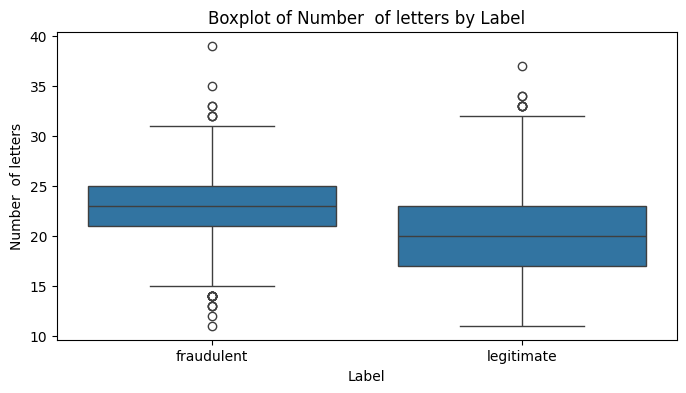

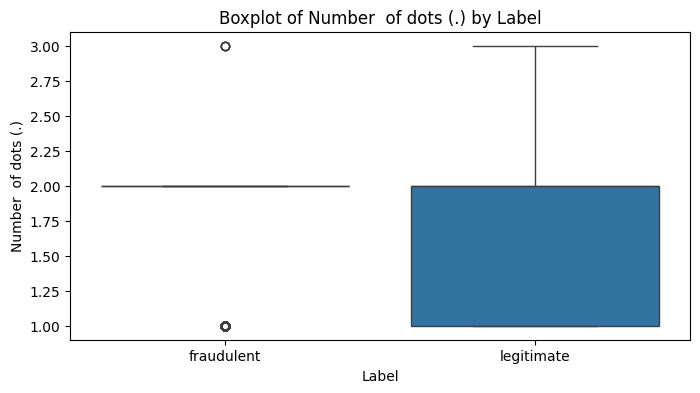

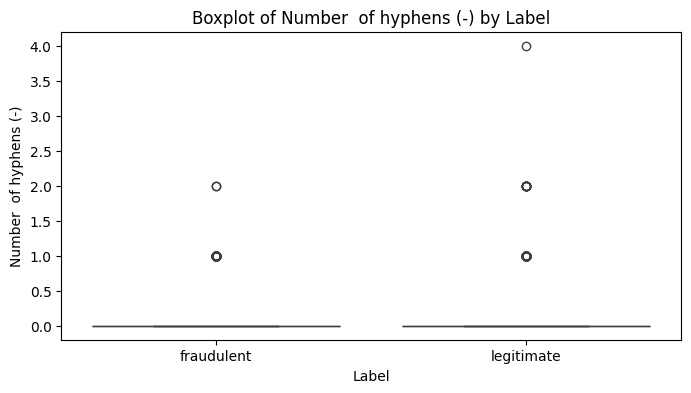

In [ ]:

for col in numerical_features:

    plt.figure(figsize=(8, 4))

    sns.boxplot(
        data=df,
        x='Label',
        y=col
    )

    plt.title(f'Boxplot of {col} by Label')

    plt.show()

In [ ]:
numerical_features = [
    'Domain length',
    'Top domain length',
    'Number  of digits',
    'Number  of letters',
    'Number  of dots (.)',
    'Number  of hyphens (-)',
    'Tranco List rank'
]

df[numerical_features].describe().T

,count,mean,std,min,25%,50%,75%,max
Domain length,1140.0,18.341228,4.512033,7.0,15.0,19.0,21.00,38.0
Top domain length,1140.0,2.851754,0.741322,2.0,2.0,3.0,3.00,13.0
Number of digits,1140.0,0.070175,0.395748,0.0,0.0,0.0,0.00,4.0
Number of letters,1140.0,21.654386,4.307723,11.0,19.0,22.0,24.25,39.0
Number of dots (.),1140.0,1.708772,0.495203,1.0,1.0,2.0,2.00,3.0
Number of hyphens (-),1140.0,0.157895,0.403648,0.0,0.0,0.0,0.00,4.0
Tranco List rank,1140.0,9710.771053,84946.859868,-1.0,-1.0,-1.0,-1.00,964101.0


In [ ]:
df[numerical_features].skew()

,0
Domain length,0.081636
Top domain length,3.365824
Number of digits,6.301100
Number of letters,0.137154
Number of dots (.),-0.433183
Number of hyphens (-),2.856578
Tranco List rank,9.150437


In [ ]:
df.groupby('Label')[numerical_features].median().T

Label,fraudulent,legitimate
Domain length,20.0,17.0
Top domain length,3.0,3.0
Number of digits,0.0,0.0
Number of letters,23.0,20.0
Number of dots (.),2.0,2.0
Number of hyphens (-),0.0,0.0
Tranco List rank,-1.0,-1.0


In [ ]:
for col in numerical_features:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower) |
        (df[col] > upper)
    ]

    print(f"\n{col}")
    print("Lower bound:", lower)
    print("Upper bound:", upper)
    print("Outliers:", len(outliers))


Domain length
Lower bound: 6.0
Upper bound: 30.0
Outliers: 8

Top domain length
Lower bound: 0.5
Upper bound: 4.5
Outliers: 44

Number  of digits
Lower bound: 0.0
Upper bound: 0.0
Outliers: 41

Number  of letters
Lower bound: 11.125
Upper bound: 32.125
Outliers: 19

Number  of dots (.)
Lower bound: -0.5
Upper bound: 3.5
Outliers: 0

Number  of hyphens (-)
Lower bound: 0.0
Upper bound: 0.0
Outliers: 166

Tranco List rank
Lower bound: -1.0
Upper bound: -1.0
Outliers: 18


In [ ]:
# Separate websites with available rankings
valid_tranco = df[df['Tranco List rank'] != -1]

print("Total websites:", len(df))

print("Websites with available rank:",
      len(valid_tranco))

print("Websites without available rank:",
      len(df[df['Tranco List rank'] == -1]))

print("\nRanking statistics:")
print(valid_tranco['Tranco List rank'].describe())

print("\nRanking comparison by class:")
print(
    valid_tranco.groupby('Label')['Tranco List rank']
    .agg(['count', 'mean', 'median', 'min', 'max'])
)

Total websites: 1140
Websites with available rank: 18
Websites without available rank: 1122

Ranking statistics:
count        18.000000
mean     615077.833333
std      298694.837130
min       35556.000000
25%      464899.750000
50%      773794.500000
75%      804128.250000
max      964101.000000
Name: Tranco List rank, dtype: float64

Ranking comparison by class:
            count           mean    median     min     max
Label                                                     
fraudulent      1  797093.000000  797093.0  797093  797093
legitimate     17  604371.058824  750712.0   35556  964101


In [ ]:
print(
    df['Top domain length']
    .value_counts()
    .sort_index()
)
print(
    df.nlargest(
        15,
        'Top domain length'
    )[
        ['Online shop URL',
         'Top domain length',
         'Label']
    ]
)

Top domain length
2     300
3     772
4      24
5      32
6      11
13      1
Name: count, dtype: int64
                                     Online shop URL  Top domain length  \
1126             https://mythsandmagic.myshopify.com                 13   
73                              https://sebhy.online                  6   
88                           https://megagear.online                  6   
149                 https://www.1potenzmittel.online                  6   
172              https://www.officiellejordan.eu.com                  6   
456                          https://buypills.online                  6   
486                         https://www.kabum.com.br                  6   
717            https://www.merchandisingplaza.com.au                  6   
719                          https://amybella.online                  6   
849                          https://www.euro.com.pl                  6   
897           https://www.bodegaaurrera.com.mx/inici                  6

In [ ]:
df.head()

,Online shop URL,Label,Domain length,Top domain length,Presence of prefix 'www',Number of digits,Number of letters,Number of dots (.),Number of hyphens (-),Presence of credit card payment,...,SSL certificate expire date,Issuer organization,SSL certificate issuer organization list item,Indication of young domain,Domain registration date,Presence of TrustPilot reviews,TrustPilot score,Presence of SiteJabber reviews,Presence in the standard Tranco list,Tranco List rank
0,https://www.allaccessorybest.com,fraudulent,24,3,1,0,27,2,0,1,...,Oct 11 03:53:36 2023 GMT,Google Trust Services LLC,9,1,2023-05-15 03:35,0,NaN,0,0,-1
1,https://www.b-watches.shop,fraudulent,18,4,1,0,20,2,1,0,...,Jun 16 23:59:59 2024 GMT,"Cloudflare, Inc.",1,1,2023-06-18 05:43,0,NaN,0,0,-1
2,https://www.waeschenamen-windrath.de,legitimate,28,2,1,0,30,2,1,1,...,Oct 24 21:53:20 2023 GMT,Let's Encrypt,2,2,Hidden,0,-1.0,0,0,-1
3,https://vendoprint.se,legitimate,13,2,0,0,17,1,0,1,...,Oct 9 15:13:00 2023 GMT,Google Trust Services LLC,9,1,2022-09-20 00:00,0,-1.0,0,0,-1
4,https://www.newbikeland.com,fraudulent,19,3,1,0,22,2,0,1,...,Oct 25 08:20:27 2023 GMT,Let's Encrypt,2,1,2023-07-27 09:05,0,NaN,0,0,-1


In [ ]:
df['Tranco Available'] = (
    df['Tranco List rank'] != -1
).astype(int)

In [ ]:
print(df['Tranco Available'].value_counts())

Tranco Available
0    1122
1      18
Name: count, dtype: int64


In [ ]:
print(pd.crosstab(
    df['Label'],
    df['Tranco Available'],
    margins=True
))

print("\nPercentage distribution:")

print(pd.crosstab(
    df['Label'],
    df['Tranco Available'],
    normalize='index'
) * 100)

Tranco Available     0   1   All
Label                           
fraudulent         578   1   579
legitimate         544  17   561
All               1122  18  1140

Percentage distribution:
Tranco Available          0         1
Label                                
fraudulent        99.827288  0.172712
legitimate        96.969697  3.030303


In [ ]:
print(pd.crosstab(
    df['Top domain length'],
    df['Label']
))
print(
    df['Top domain length']
    .groupby(df['Label'])
    .describe()
)

Label              fraudulent  legitimate
Top domain length                        
2                          50         250
3                         489         283
4                          20           4
5                          14          18
6                           6           5
13                          0           1
            count      mean       std  min  25%  50%  75%   max
Label                                                          
fraudulent  579.0  3.027634  0.557363  2.0  3.0  3.0  3.0   6.0
legitimate  561.0  2.670232  0.855646  2.0  2.0  3.0  3.0  13.0


In [ ]:
correlation_features = [
    'Domain length',
    'Top domain length',
    'Number  of digits',
    'Number  of letters',
    'Number  of dots (.)',
    'Number  of hyphens (-)',
    'Tranco Available'
]

corr_df = df[correlation_features].copy()

corr_df['Label'] = df['Label'].map({
    'fraudulent': 1,
    'legitimate': 0
})

pearson_corr = corr_df.corr(method='pearson')

print(pearson_corr.round(3))

                        Domain length  Top domain length  Number  of digits  \
Domain length                   1.000              0.237             -0.023   
Top domain length               0.237              1.000             -0.009   
Number  of digits              -0.023             -0.009              1.000   
Number  of letters              0.960              0.216             -0.100   
Number  of dots (.)             0.447              0.208             -0.057   
Number  of hyphens (-)          0.176             -0.048             -0.003   
Tranco Available               -0.144             -0.070             -0.022   
Label                           0.343              0.241             -0.025   

                        Number  of letters  Number  of dots (.)  \
Domain length                        0.960                0.447   
Top domain length                    0.216                0.208   
Number  of digits                   -0.100               -0.057   
Number  of letters  

In [ ]:
spearman_corr = corr_df.corr(method='spearman')

print(spearman_corr.round(3))

                        Domain length  Top domain length  Number  of digits  \
Domain length                   1.000              0.289             -0.018   
Top domain length               0.289              1.000             -0.001   
Number  of digits              -0.018             -0.001              1.000   
Number  of letters              0.962              0.271             -0.085   
Number  of dots (.)             0.443              0.171             -0.051   
Number  of hyphens (-)          0.162             -0.020              0.001   
Tranco Available               -0.140             -0.085             -0.024   
Label                           0.372              0.371             -0.018   

                        Number  of letters  Number  of dots (.)  \
Domain length                        0.962                0.443   
Top domain length                    0.271                0.171   
Number  of digits                   -0.085               -0.051   
Number  of letters  

In [ ]:
print("Pearson correlation with Label:")

print(
    pearson_corr['Label']
    .drop('Label')
    .sort_values(ascending=False)
)

print("\nSpearman correlation with Label:")

print(
    spearman_corr['Label']
    .drop('Label')
    .sort_values(ascending=False)
)

Pearson correlation with Label:
Domain length             0.343303
Number  of letters        0.293034
Top domain length         0.241133
Number  of dots (.)       0.108544
Number  of digits        -0.024979
Number  of hyphens (-)   -0.045319
Tranco Available         -0.114601
Name: Label, dtype: float64

Spearman correlation with Label:
Domain length             0.372056
Top domain length         0.370776
Number  of letters        0.322600
Number  of dots (.)       0.119337
Number  of digits        -0.017545
Number  of hyphens (-)   -0.029090
Tranco Available         -0.114601
Name: Label, dtype: float64


In [ ]:
domain_relationship = df[
    ['Domain length', 'Number  of letters']
].copy()

# Calculate the difference between both features
domain_relationship['Difference'] = (
    domain_relationship['Domain length']
    - domain_relationship['Number  of letters']
)

print("Difference statistics:")

print(
    domain_relationship['Difference']
    .describe()
)

print("\nNumber of records where both values are equal:")

print(
    (
        domain_relationship['Domain length']
        == domain_relationship['Number  of letters']
    ).sum()
)

print("\nMost common differences:")

print(
    domain_relationship['Difference']
    .value_counts()
    .head(15)
)

Difference statistics:
count    1140.000000
mean       -3.313158
std         1.266577
min       -19.000000
25%        -4.000000
50%        -3.000000
75%        -3.000000
max         1.000000
Name: Difference, dtype: float64

Number of records where both values are equal:
4

Most common differences:
Difference
-3     628
-4     270
-2     131
-5      45
-1      22
-6      21
-7       4
 0       4
-10      4
-8       3
-9       2
 1       1
-11      1
-12      1
-14      1
Name: count, dtype: int64


In [ ]:
print(
    df.groupby('Label')[
        ['Domain length', 'Number  of letters']
    ].agg(['mean', 'median', 'std', 'min', 'max']).round(2)
)

           Domain length                      Number  of letters               \
                    mean median   std min max               mean median   std   
Label                                                                           
fraudulent         19.87   20.0  3.87   9  38              22.90   23.0  3.71   
legitimate         16.77   17.0  4.59   7  34              20.37   20.0  4.51   

                    
           min max  
Label               
fraudulent  11  39  
legitimate  11  37  


In [ ]:
columns_to_inspect = [
    'Online shop URL',
    'Domain length',
    'Number  of letters',
    'Number  of digits',
    'Number  of dots (.)',
    'Number  of hyphens (-)',
    'Label'
]

print(
    df[columns_to_inspect].head(15).to_string(index=False)
)

                     Online shop URL  Domain length  Number  of letters  Number  of digits  Number  of dots (.)  Number  of hyphens (-)      Label
    https://www.allaccessorybest.com             24                  27                  0                    2                       0 fraudulent
          https://www.b-watches.shop             18                  20                  0                    2                       1 fraudulent
https://www.waeschenamen-windrath.de             28                  30                  0                    2                       1 legitimate
               https://vendoprint.se             13                  17                  0                    1                       0 legitimate
         https://www.newbikeland.com             19                  22                  0                    2                       0 fraudulent
  https://www.hats-storeofficial.com             26                  28                  0                    2       

In [ ]:
df['Domain_Letter_Difference'] = (
    df['Domain length'] - df['Number  of letters']
)

print(
    df.groupby('Label')['Domain_Letter_Difference']
    .agg(['mean', 'median', 'std', 'min', 'max'])
    .round(2)
)

            mean  median   std  min  max
Label                                   
fraudulent -3.03    -3.0  0.63   -5    0
legitimate -3.60    -3.0  1.64  -19    1


In [ ]:
columns_to_inspect = [
    'Online shop URL',
    'Domain length',
    'Number  of letters',
    'Number  of digits',
    'Number  of dots (.)',
    'Number  of hyphens (-)',
    'Label'
]

print(
    df[columns_to_inspect].head(15).to_string(index=False)
)

                     Online shop URL  Domain length  Number  of letters  Number  of digits  Number  of dots (.)  Number  of hyphens (-)      Label
    https://www.allaccessorybest.com             24                  27                  0                    2                       0 fraudulent
          https://www.b-watches.shop             18                  20                  0                    2                       1 fraudulent
https://www.waeschenamen-windrath.de             28                  30                  0                    2                       1 legitimate
               https://vendoprint.se             13                  17                  0                    1                       0 legitimate
         https://www.newbikeland.com             19                  22                  0                    2                       0 fraudulent
  https://www.hats-storeofficial.com             26                  28                  0                    2       

In [ ]:
print(
    df.loc[
        df['Domain_Letter_Difference'].idxmin(),
        columns_to_inspect
    ]
)

Online shop URL           https://www.leglove.dk/shop/frontpage.htm
Domain length                                                    14
Number  of letters                                               33
Number  of digits                                                 0
Number  of dots (.)                                               3
Number  of hyphens (-)                                            0
Label                                                    legitimate
Name: 1064, dtype: object


In [ ]:
from urllib.parse import urlsplit

def extract_url_metrics(url):

    parsed = urlsplit(str(url))

    hostname = parsed.hostname or ""

    return pd.Series({
        'Calculated Hostname Length': len(hostname),

        'Calculated URL Letters': sum(
            char.isalpha() for char in str(url)
        ),

        'Calculated Hostname Letters': sum(
            char.isalpha() for char in hostname
        ),

        'Calculated URL Dots': str(url).count('.'),

        'Calculated URL Hyphens': str(url).count('-')
    })


url_metrics = df['Online shop URL'].apply(extract_url_metrics)

verification_df = pd.concat(
    [
        df[['Domain length',
            'Number  of letters',
            'Number  of dots (.)',
            'Number  of hyphens (-)']].reset_index(drop=True),

        url_metrics.reset_index(drop=True)
    ],
    axis=1
)

print("Feature definition verification:")

print(
    pd.DataFrame({
        'Feature': [
            'Domain length',
            'Number of letters',
            'Number of dots',
            'Number of hyphens'
        ],

        'Matching records': [
            (
                verification_df['Domain length']
                == verification_df['Calculated Hostname Length']
            ).sum(),

            (
                verification_df['Number  of letters']
                == verification_df['Calculated URL Letters']
            ).sum(),

            (
                verification_df['Number  of dots (.)']
                == verification_df['Calculated URL Dots']
            ).sum(),

            (
                verification_df['Number  of hyphens (-)']
                == verification_df['Calculated URL Hyphens']
            ).sum()
        ]
    })
)

print("\nFirst 10 verification records:")

print(verification_df.head(10).to_string(index=False))

Feature definition verification:
             Feature  Matching records
0      Domain length              1139
1  Number of letters              1127
2     Number of dots              1138
3  Number of hyphens              1138

First 10 verification records:
 Domain length  Number  of letters  Number  of dots (.)  Number  of hyphens (-)  Calculated Hostname Length  Calculated URL Letters  Calculated Hostname Letters  Calculated URL Dots  Calculated URL Hyphens
            24                  27                    2                       0                          24                      27                           22                    2                       0
            18                  20                    2                       1                          18                      20                           15                    2                       1
            28                  30                    2                       1                          28               

In [ ]:
mismatch_df = verification_df.copy()

mismatch_df['Online shop URL'] = (
    df['Online shop URL'].reset_index(drop=True)
)

# Find records where at least one original feature differs
mismatches = mismatch_df[
    (
        mismatch_df['Domain length']
        != mismatch_df['Calculated Hostname Length']
    )
    |
    (
        mismatch_df['Number  of letters']
        != mismatch_df['Calculated URL Letters']
    )
    |
    (
        mismatch_df['Number  of dots (.)']
        != mismatch_df['Calculated URL Dots']
    )
    |
    (
        mismatch_df['Number  of hyphens (-)']
        != mismatch_df['Calculated URL Hyphens']
    )
]

print("Total mismatched records:", len(mismatches))

print(mismatches.to_string(index=True))

Total mismatched records: 13
      Domain length  Number  of letters  Number  of dots (.)  Number  of hyphens (-)  Calculated Hostname Length  Calculated URL Letters  Calculated Hostname Letters  Calculated URL Dots  Calculated URL Hyphens                      Online shop URL
14               15                  17                    2                       0                          15                      18                           13                    2                       0              https://www.ebnblog.com
75               16                  21                    1                       1                          16                      19                           14                    1                       1             https://darknet-shop.net
190              22                  22                    2                       4                          22                      21                           16                    2                       3       https://ww

In [ ]:
# Create mismatch indicators
mismatch_analysis = pd.DataFrame(index=verification_df.index)

mismatch_analysis['Domain length'] = (
    verification_df['Domain length']
    != verification_df['Calculated Hostname Length']
)

mismatch_analysis['Number of letters'] = (
    verification_df['Number  of letters']
    != verification_df['Calculated URL Letters']
)

mismatch_analysis['Number of dots'] = (
    verification_df['Number  of dots (.)']
    != verification_df['Calculated URL Dots']
)

mismatch_analysis['Number of hyphens'] = (
    verification_df['Number  of hyphens (-)']
    != verification_df['Calculated URL Hyphens']
)

print("Mismatches per feature:")

print(mismatch_analysis.sum())

print("\nTotal records with any mismatch:")

print(mismatch_analysis.any(axis=1).sum())

print("\nDifference between original and calculated values:")

for original, calculated in [
    ('Domain length', 'Calculated Hostname Length'),
    ('Number  of letters', 'Calculated URL Letters'),
    ('Number  of dots (.)', 'Calculated URL Dots'),
    ('Number  of hyphens (-)', 'Calculated URL Hyphens')
]:

    print(f"\n{original}")

    print(
        verification_df[original]
        .sub(verification_df[calculated])
        .value_counts()
        .sort_index()
    )

Mismatches per feature:
Domain length         1
Number of letters    13
Number of dots        2
Number of hyphens     2
dtype: int64

Total records with any mismatch:
13

Difference between original and calculated values:

Domain length
-6       1
 0    1139
Name: count, dtype: int64

Number  of letters
-6        1
-1        5
 0     1127
 1        2
 2        1
 6        1
 7        1
 10       2
Name: count, dtype: int64

Number  of dots (.)
0    1138
1       2
Name: count, dtype: int64

Number  of hyphens (-)
0    1138
1       2
Name: count, dtype: int64


In [ ]:
features = [
    'Number  of digits',
    'Number  of hyphens (-)'
]

for feature in features:

    print("\n" + "=" * 60)
    print("FEATURE:", feature)
    print("=" * 60)

    # Count websites with zero and non-zero values
    presence = (df[feature] > 0).map({
        True: 'Present',
        False: 'Absent'
    })

    print("\nCounts by class:")
    print(pd.crosstab(df['Label'], presence))

    print("\nPercentages by class:")
    print(
        pd.crosstab(
            df['Label'],
            presence,
            normalize='index'
        ).mul(100).round(2)
    )

    # Analyze only websites where the feature is present
    print("\nValues when feature is present:")
    print(
        df[df[feature] > 0]
        .groupby('Label')[feature]
        .agg(['count', 'mean', 'median', 'min', 'max'])
    )

    print("\nValue distribution:")
    print(
        pd.crosstab(df['Label'], df[feature])
    )


FEATURE: Number  of digits

Counts by class:
Number  of digits  Absent  Present
Label                             
fraudulent            560       19
legitimate            539       22

Percentages by class:
Number  of digits  Absent  Present
Label                             
fraudulent          96.72     3.28
legitimate          96.08     3.92

Values when feature is present:
            count      mean  median  min  max
Label                                        
fraudulent     19  1.842105     2.0    1    3
legitimate     22  2.045455     2.0    1    4

Value distribution:
Number  of digits    0  1   2  3  4
Label                              
fraudulent         560  7   8  4  0
legitimate         539  6  11  3  2

FEATURE: Number  of hyphens (-)

Counts by class:
Number  of hyphens (-)  Absent  Present
Label                                  
fraudulent                 500       79
legitimate                 474       87

Percentages by class:
Number  of hyphens (-)  Absent  Pre

In [ ]:

print("Dataset columns and data types:")
print(df.dtypes)

print("\nUnique values per column:")
print(df.nunique().sort_values())


Dataset columns and data types:
Online shop URL                                   object
Label                                             object
Domain length                                      int64
Top domain length                                  int64
Presence of prefix 'www'                           int64
Number  of digits                                  int64
Number  of letters                                 int64
Number  of dots (.)                                int64
Number  of hyphens (-)                             int64
Presence of credit card payment                    int64
Presence of money back payment                     int64
Presence of cash on delivery payment               int64
Presence of crypto currency                        int64
Presence of free contact emails                    int64
Presence of logo URL                               int64
SSL certificate issuer                            object
SSL certificate expire date                       object

In [ ]:
# Features requiring categorical investigation

categorical_candidates = [
    "Presence of prefix 'www' ",  # Fixed trailing space
    "Presence of credit card payment",
    "Presence of money back payment",
    "Presence of cash on delivery payment",
    "Presence of crypto currency",
    "Presence of free contact emails",
    "Presence of logo URL",
    "Presence of TrustPilot reviews",
    "Presence of SiteJabber reviews",
    "Presence in the standard Tranco list",
    "Tranco Available",
    "Indication of young domain ",  # Fixed trailing space
    "SSL certificate issuer",
    "Issuer organization",
    "SSL certificate issuer organization list item"
]

# Examine actual values and their frequencies

for col in categorical_candidates:

    print("\n" + "=" * 65)
    print(f"FEATURE: {col}")
    print("=" * 65)

    print("\nUnique values:")
    print(df[col].unique())

    print("\nValue counts:")
    print(df[col].value_counts(dropna=False))

    print("\nValue percentages:")
    print(
        (df[col].value_counts(normalize=True, dropna=False) * 100)
        .round(2)
    )


FEATURE: Presence of prefix 'www' 

Unique values:
[1 0]

Value counts:
Presence of prefix 'www' 
1    759
0    381
Name: count, dtype: int64

Value percentages:
Presence of prefix 'www' 
1    66.58
0    33.42
Name: proportion, dtype: float64

FEATURE: Presence of credit card payment

Unique values:
[1 0]

Value counts:
Presence of credit card payment
1    870
0    270
Name: count, dtype: int64

Value percentages:
Presence of credit card payment
1    76.32
0    23.68
Name: proportion, dtype: float64

FEATURE: Presence of money back payment

Unique values:
[1 0]

Value counts:
Presence of money back payment
1    813
0    327
Name: count, dtype: int64

Value percentages:
Presence of money back payment
1    71.32
0    28.68
Name: proportion, dtype: float64

FEATURE: Presence of cash on delivery payment

Unique values:
[0 1]

Value counts:
Presence of cash on delivery payment
0    868
1    272
Name: count, dtype: int64

Value percentages:
Presence of cash on delivery payment
0    76.14
1 

In [ ]:

# Binary and low-cardinality categorical features

features_to_analyze = [
    "Presence of prefix 'www'",
    "Presence of credit card payment",
    "Presence of money back payment",
    "Presence of cash on delivery payment",
    "Presence of crypto currency",
    "Presence of free contact emails",
    "Presence of logo URL",
    "Presence of TrustPilot reviews",
    "Presence of SiteJabber reviews",
    "Presence in the standard Tranco list",
    "Tranco Available",
    "Indication of young domain"
]

# Handle possible leading/trailing spaces
column_lookup = {col.strip(): col for col in df.columns}

for feature in features_to_analyze:

    col = column_lookup[feature]

    print("\n" + "=" * 65)
    print("FEATURE:", col)
    print("=" * 65)

    # Frequency of each category within each class
    counts = pd.crosstab(df["Label"], df[col])

    print("\nCounts by class:")
    print(counts)

    # Percentage distribution within each class
    percentages = pd.crosstab(
        df["Label"],
        df[col],
        normalize="index"
    ) * 100

    print("\nPercentages by class:")
    print(percentages.round(2))



FEATURE: Presence of prefix 'www' 

Counts by class:
Presence of prefix 'www'     0    1
Label                              
fraudulent                 150  429
legitimate                 231  330

Percentages by class:
Presence of prefix 'www'       0      1
Label                                  
fraudulent                 25.91  74.09
legitimate                 41.18  58.82

FEATURE: Presence of credit card payment

Counts by class:
Presence of credit card payment    0    1
Label                                    
fraudulent                       140  439
legitimate                       130  431

Percentages by class:
Presence of credit card payment      0      1
Label                                        
fraudulent                       24.18  75.82
legitimate                       23.17  76.83

FEATURE: Presence of money back payment

Counts by class:
Presence of money back payment    0    1
Label                                   
fraudulent                      176  403
le

In [ ]:

# Investigate rare categories

high_cardinality_features = [
    "SSL certificate issuer",
    "Issuer organization"
]

for feature in high_cardinality_features:

    col = column_lookup[feature]

    print("\n" + "=" * 65)
    print("FEATURE:", col)
    print("=" * 65)

    counts = df[col].value_counts(dropna=False)

    # Categories appearing fewer than 10 times
    rare_categories = counts[counts < 10]

    print("\nCategories appearing fewer than 10 times:")
    print(rare_categories)

    print("\nNumber of rare categories:")
    print(len(rare_categories))

    print("\nTotal records belonging to rare categories:")
    print(rare_categories.sum())

    print("\nPercentage of dataset:")
    print(round(rare_categories.sum() / len(df) * 100, 2), "%")



FEATURE: SSL certificate issuer

Categories appearing fewer than 10 times:
SSL certificate issuer
Certum Domain Validation CA SHA2                         9
Sectigo RSA Extended Validation Secure Server CA         9
Amazon RSA 2048 M01                                      8
GeoTrust RSA CA 2018                                     7
Encryption Everywhere DV TLS CA - G2                     5
Sectigo RSA Organization Validation Secure Server CA     5
GlobalSign RSA OV SSL CA 2018                            4
Encryption Everywhere DV TLS CA - G1                     4
Go Daddy Secure Certificate Authority - G2               4
DigiCert Global G2 TLS RSA SHA256 2020 CA1               4
AlphaSSL CA - SHA256 - G4                                4
GeoTrust EV RSA CA 2018                                  4
RapidSSL Global TLS RSA4096 SHA256 2022 CA1              4
GeoTrust Global TLS RSA4096 SHA256 2022 CA1              3
DigiCert SHA2 Extended Validation Server CA              3
Shoper SSL      

In [ ]:

for feature in high_cardinality_features:

    col = column_lookup[feature]

    print("\n" + "=" * 65)
    print("FEATURE:", col)
    print("=" * 65)

    counts = pd.crosstab(df[col], df["Label"])

    print("\nCategory counts by class:")
    print(counts)

    percentages = pd.crosstab(
        df[col],
        df["Label"],
        normalize="index"
    ) * 100

    print("\nClass percentages within each category:")
    print(percentages.round(2))



FEATURE: SSL certificate issuer

Category counts by class:
Label                                               fraudulent  legitimate
SSL certificate issuer                                                    
AlphaSSL CA - SHA256 - G4                                    0           4
Amazon RSA 2048 M01                                          0           8
Amazon RSA 2048 M02                                          0          10
Certum Domain Validation CA SHA2                             0           9
Certum Organization Validation CA SHA2                       0           1
Certyfikat SSL                                               0           1
Cloudflare Inc ECC CA-3                                     29          58
DigiCert EV RSA CA G2                                        0           1
DigiCert Global G2 TLS RSA SHA256 2020 CA1                   0           4
DigiCert SHA2 Extended Validation Server CA                  0           3
DigiCert TLS RSA SHA256 2020 CA1        

In [ ]:
issuer_col = column_lookup["SSL certificate issuer"]
org_col = column_lookup["Issuer organization"]

issuer_org_mapping = (
    df.groupby([issuer_col, org_col], dropna=False)
    .size()
    .reset_index(name="Count")
    .sort_values("Count", ascending=False)
)

print("SSL issuer to organization mapping:")
print(issuer_org_mapping.to_string(index=False))

SSL issuer to organization mapping:
                               SSL certificate issuer            Issuer organization  Count
                                                   R3                  Let's Encrypt    411
                                           GTS CA 1P5      Google Trust Services LLC    329
                                                   E1                  Let's Encrypt    129
                              Cloudflare Inc ECC CA-3               Cloudflare, Inc.     87
       Sectigo RSA Domain Validation Secure Server CA                Sectigo Limited     42
                 cPanel, Inc. Certification Authority                   cPanel, Inc.     13
                     DigiCert TLS RSA SHA256 2020 CA1                   DigiCert Inc     12
                                  Amazon RSA 2048 M02                         Amazon     10
                     Certum Domain Validation CA SHA2      Unizeto Technologies S.A.      9
     Sectigo RSA Extended Validation Secure 

In [ ]:
issuer_mapping_counts = (
    df.groupby(issuer_col)[org_col]
    .nunique()
    .sort_values(ascending=False)
)

print("Number of organizations associated with each SSL issuer:")
print(issuer_mapping_counts)

print("\nIssuers associated with multiple organizations:")
print(issuer_mapping_counts[issuer_mapping_counts > 1])

Number of organizations associated with each SSL issuer:
SSL certificate issuer
AlphaSSL CA - SHA256 - G4                                1
Amazon RSA 2048 M01                                      1
Amazon RSA 2048 M02                                      1
Certum Domain Validation CA SHA2                         1
Certum Organization Validation CA SHA2                   1
Certyfikat SSL                                           1
Cloudflare Inc ECC CA-3                                  1
DigiCert EV RSA CA G2                                    1
DigiCert Global G2 TLS RSA SHA256 2020 CA1               1
DigiCert SHA2 Extended Validation Server CA              1
DigiCert TLS RSA SHA256 2020 CA1                         1
Don Dominio / MrDomain RSA DV CA                         1
E1                                                       1
Encryption Everywhere DV TLS CA - G1                     1
Encryption Everywhere DV TLS CA - G2                     1
Encryption Everywhere G3 TLS ECC P3

In [ ]:
org_mapping_counts = (
    df.groupby(org_col)[issuer_col]
    .nunique()
    .sort_values(ascending=False)
)

print("Number of SSL issuer names associated with each organization:")
print(org_mapping_counts)

Number of SSL issuer names associated with each organization:
Issuer organization
DigiCert Inc                      15
GlobalSign nv-sa                   5
Sectigo Limited                    3
Amazon                             2
Let's Encrypt                      2
Google Trust Services LLC          2
Unizeto Technologies S.A.          2
ZeroSSL                            2
CentralNic Luxembourg Srl          1
Cloudflare, Inc.                   1
GoDaddy.com, Inc.                  1
Dreamcommerce S.A.                 1
Soluciones Corporativas IP, SL     1
Starfield Technologies, Inc.       1
TrustAsia Technologies, Inc.       1
Trust Provider B.V.                1
cPanel, Inc.                       1
home.pl S.A.                       1
Name: SSL certificate issuer, dtype: int64


In [ ]:
encoded_col = column_lookup[
    "SSL certificate issuer organization list item"
]

print(
    pd.crosstab(
        df[org_col],
        df[encoded_col]
    )
)

SSL certificate issuer organization list item  1    2   3   4   5   6   7   \
Issuer organization                                                          
Amazon                                          0    0   0   0   0  18   0   
CentralNic Luxembourg Srl                       0    0   0   0   0   0   0   
Cloudflare, Inc.                               87    0   0   0   0   0   0   
DigiCert Inc                                    0    0   0   0   0   0  55   
Dreamcommerce S.A.                              0    0   0   0   0   0   0   
GlobalSign nv-sa                                0    0   0   0   0   0   0   
GoDaddy.com, Inc.                               0    0   0   0   4   0   0   
Google Trust Services LLC                       0    0   0   0   0   0   0   
Let's Encrypt                                   0  540   0   0   0   0   0   
Sectigo Limited                                 0    0  56   0   0   0   0   
Soluciones Corporativas IP, SL                  0    0   0   0  

In [ ]:
org_encoded_mapping = (
    df.groupby(org_col)[encoded_col]
    .nunique()
    .sort_values(ascending=False)
)

print("Unique encoded values per organization:")
print(org_encoded_mapping)

print("\nOrganizations with multiple encoded values:")
print(org_encoded_mapping[org_encoded_mapping > 1])

Unique encoded values per organization:
Issuer organization
Unizeto Technologies S.A.         2
Amazon                            1
CentralNic Luxembourg Srl         1
Cloudflare, Inc.                  1
Dreamcommerce S.A.                1
DigiCert Inc                      1
GoDaddy.com, Inc.                 1
Google Trust Services LLC         1
Let's Encrypt                     1
GlobalSign nv-sa                  1
Sectigo Limited                   1
Soluciones Corporativas IP, SL    1
Trust Provider B.V.               1
Starfield Technologies, Inc.      1
TrustAsia Technologies, Inc.      1
ZeroSSL                           1
cPanel, Inc.                      1
home.pl S.A.                      1
Name: SSL certificate issuer organization list item, dtype: int64

Organizations with multiple encoded values:
Issuer organization
Unizeto Technologies S.A.    2
Name: SSL certificate issuer organization list item, dtype: int64


In [ ]:
encoded_org_mapping = (
    df.groupby(encoded_col)[org_col]
    .nunique()
    .sort_values(ascending=False)
)

print("Unique organizations per encoded value:")
print(encoded_org_mapping)

print("\nEncoded values associated with multiple organizations:")
print(encoded_org_mapping[encoded_org_mapping > 1])

Unique organizations per encoded value:
SSL certificate issuer organization list item
11    7
2     3
1     1
3     1
4     1
6     1
5     1
7     1
8     1
9     1
10    1
Name: Issuer organization, dtype: int64

Encoded values associated with multiple organizations:
SSL certificate issuer organization list item
11    7
2     3
Name: Issuer organization, dtype: int64


In [ ]:
encoded_class_counts = pd.crosstab(
    df[encoded_col],
    df["Label"]
)

print("Encoded feature counts by class:")
print(encoded_class_counts)

print("\nClass percentages within each encoded value:")

encoded_class_percentages = pd.crosstab(
    df[encoded_col],
    df["Label"],
    normalize="index"
) * 100

print(encoded_class_percentages.round(2))

Encoded feature counts by class:
Label                                          fraudulent  legitimate
SSL certificate issuer organization list item                        
1                                                      29          58
2                                                     237         306
3                                                      10          46
4                                                       5           8
5                                                       0           4
6                                                       0          18
7                                                       1          54
8                                                       0          12
9                                                     292          38
10                                                      4           0
11                                                      1          17

Class percentages within each encoded value:
Label      

In [ ]:
young_col = column_lookup["Indication of young domain"]

print("Value counts:")
print(df[young_col].value_counts(dropna=False).sort_index())

print("\nClass-wise counts:")
print(pd.crosstab(df[young_col], df["Label"]))

print("\nClass-wise percentages:")
print(
    (
        pd.crosstab(
            df[young_col],
            df["Label"],
            normalize="index"
        ) * 100
    ).round(2)
)

Value counts:
Indication of young domain 
0    550
1    473
2    117
Name: count, dtype: int64

Class-wise counts:
Label                        fraudulent  legitimate
Indication of young domain                         
0                                    75         475
1                                   465           8
2                                    39          78

Class-wise percentages:
Label                        fraudulent  legitimate
Indication of young domain                         
0                                 13.64       86.36
1                                 98.31        1.69
2                                 33.33       66.67


In [ ]:
registration_col = column_lookup["Domain registration date"]

print(
    df.groupby(
        [young_col, "Label"],
        dropna=False
    )[registration_col]
    .agg(["count", "nunique"])
)

                                        count  nunique
Indication of young domain  Label                     
0                           fraudulent     71       65
                            legitimate    475      471
1                           fraudulent    465      398
                            legitimate      8        8
2                           fraudulent     39        1
                            legitimate     78        1


In [ ]:
print("Registration dates for category 2:")

print(
    df.loc[
        df[young_col] == 2,
        [young_col, "Label", registration_col]
    ].value_counts(dropna=False)
)

print("\nUnique registration dates by category:")

for value in sorted(df[young_col].dropna().unique()):
    print(f"\nCategory {value}:")
    print(
        df.loc[
            df[young_col] == value,
            registration_col
        ].value_counts(dropna=False).head(10)
    )

Registration dates for category 2:
Indication of young domain   Label       Domain registration date
2                            legitimate  Hidden                      78
                             fraudulent  Hidden                      39
Name: count, dtype: int64

Unique registration dates by category:

Category 0:
Domain registration date
2020-06-01 17:00    4
NaN                 4
2017-03-15 21:25    3
1995-08-10 04:00    2
2021-02-03 00:00    2
2021-08-27 00:00    2
2021-03-29 10:54    2
2009-12-02 00:00    2
1997-11-13 05:00    1
2018-11-29 10:12    1
Name: count, dtype: int64

Category 1:
Domain registration date
2023-06-06 00:00    7
2023-06-08 00:00    6
2023-05-11 00:00    5
2023-03-16 00:00    5
2023-07-06 00:00    5
2023-03-21 00:00    5
2023-05-08 00:00    5
2023-07-18 00:00    3
2023-05-06 00:00    3
2023-07-07 00:00    3
Name: count, dtype: int64

Category 2:
Domain registration date
Hidden    117
Name: count, dtype: int64


In [ ]:

email_col = column_lookup["Presence of free contact emails"]

print("=" * 60)
print("FEATURE: Presence of free contact emails")
print("=" * 60)

print("\nValue counts:")
print(df[email_col].value_counts(dropna=False).sort_index())

print("\nCounts by class:")
print(pd.crosstab(df[email_col], df["Label"]))

print("\nPercentages by class:")
print(
    (
        pd.crosstab(
            df[email_col],
            df["Label"],
            normalize="index"
        ) * 100
    ).round(2)
)


FEATURE: Presence of free contact emails

Value counts:
Presence of free contact emails
0    567
1     56
2    406
3    111
Name: count, dtype: int64

Counts by class:
Label                            fraudulent  legitimate
Presence of free contact emails                        
0                                       459         108
1                                        16          40
2                                        68         338
3                                        36          75

Percentages by class:
Label                            fraudulent  legitimate
Presence of free contact emails                        
0                                     80.95       19.05
1                                     28.57       71.43
2                                     16.75       83.25
3                                     32.43       67.57


In [ ]:
print("Feature columns:")
print([
    col for col in df.columns
    if "email" in str(col).lower()
])

print("\nFree contact email feature:")
print(df[email_col].value_counts(dropna=False))

Feature columns:
['Presence of free contact emails']

Free contact email feature:
Presence of free contact emails
0    567
2    406
3    111
1     56
Name: count, dtype: int64


In [ ]:

logo_col = column_lookup["Presence of logo URL"]

print("=" * 60)
print("FEATURE: Presence of logo URL")
print("=" * 60)

print("\nValue counts:")
print(df[logo_col].value_counts(dropna=False).sort_index())

print("\nCounts by class:")
print(pd.crosstab(df[logo_col], df["Label"]))

print("\nPercentages by class:")
print(
    (
        pd.crosstab(
            df[logo_col],
            df["Label"],
            normalize="index"
        ) * 100
    ).round(2)
)


FEATURE: Presence of logo URL

Value counts:
Presence of logo URL
0    203
1    937
Name: count, dtype: int64

Counts by class:
Label                 fraudulent  legitimate
Presence of logo URL                        
0                            180          23
1                            399         538

Percentages by class:
Label                 fraudulent  legitimate
Presence of logo URL                        
0                          88.67       11.33
1                          42.58       57.42


In [ ]:
print("Logo feature values:")
print(df[logo_col].value_counts(dropna=False))

print("\nData type:")
print(df[logo_col].dtype)

print("\nMissing values:")
print(df[logo_col].isna().sum())

Logo feature values:
Presence of logo URL
1    937
0    203
Name: count, dtype: int64

Data type:
int64

Missing values:
0


In [ ]:
for col in df.columns:
    if col != "Label":
        print(f"\nFeature: {col}")
        print("Data type:", df[col].dtype)
        print("Unique values:", df[col].nunique(dropna=False))
        print("Examples:", df[col].dropna().unique()[:10])


Feature: Online shop URL
Data type: object
Unique values: 1140
Examples: ['https://www.allaccessorybest.com' 'https://www.b-watches.shop'
 'https://www.waeschenamen-windrath.de' 'https://vendoprint.se'
 'https://www.newbikeland.com' 'https://www.hats-storeofficial.com'
 'https://balaganstudio.com' 'https://www.bootscleaner.com'
 'https://shop.tovarseasycleaning.com' 'https://camerabebelusului.ro']

Feature: Domain length
Data type: int64
Unique values: 28
Examples: [24 18 28 13 19 26 17 20 27 14]

Feature: Top domain length
Data type: int64
Unique values: 6
Examples: [ 3  4  2  5  6 13]

Feature: Presence of prefix 'www' 
Data type: int64
Unique values: 2
Examples: [1 0]

Feature: Number  of digits
Data type: int64
Unique values: 5
Examples: [0 2 1 3 4]

Feature: Number  of letters
Data type: int64
Unique values: 27
Examples: [27 20 30 17 22 28 21 23 24 19]

Feature: Number  of dots (.)
Data type: int64
Unique values: 3
Examples: [2 1 3]

Feature: Number  of hyphens (-)
Data type: int

In [ ]:
ssl_issuer_col = column_lookup["SSL certificate issuer"]

print("=" * 60)
print("FEATURE: SSL certificate issuer")
print("=" * 60)

print("\nTop 20 value counts:")
print(df[ssl_issuer_col].value_counts(dropna=False).head(20))

print("\nCounts by class:")
print(pd.crosstab(df[ssl_issuer_col], df["Label"]))

print("\nPercentages by class:")
print(
    (
        pd.crosstab(
            df[ssl_issuer_col],
            df["Label"],
            normalize="index"
        ) * 100
    ).round(2)
)

FEATURE: SSL certificate issuer

Top 20 value counts:
SSL certificate issuer
R3                                                      411
GTS CA 1P5                                              329
E1                                                      129
Cloudflare Inc ECC CA-3                                  87
Sectigo RSA Domain Validation Secure Server CA           42
cPanel, Inc. Certification Authority                     13
DigiCert TLS RSA SHA256 2020 CA1                         12
Amazon RSA 2048 M02                                      10
Certum Domain Validation CA SHA2                          9
Sectigo RSA Extended Validation Secure Server CA          9
Amazon RSA 2048 M01                                       8
GeoTrust RSA CA 2018                                      7
Encryption Everywhere DV TLS CA - G2                      5
Sectigo RSA Organization Validation Secure Server CA      5
GlobalSign RSA OV SSL CA 2018                             4
Encryption Everywhere D

In [ ]:
print("Missing values:", df[ssl_issuer_col].isna().sum())

print("\nNumber of unique issuers:",
      df[ssl_issuer_col].nunique())

print("\nIssuers appearing 5 times or fewer:")
print(
    df[ssl_issuer_col]
    .value_counts()
    .loc[lambda x: x <= 5]
)

Missing values: 0

Number of unique issuers: 43

Issuers appearing 5 times or fewer:
SSL certificate issuer
Encryption Everywhere DV TLS CA - G2                     5
Sectigo RSA Organization Validation Secure Server CA     5
GlobalSign RSA OV SSL CA 2018                            4
Encryption Everywhere DV TLS CA - G1                     4
Go Daddy Secure Certificate Authority - G2               4
DigiCert Global G2 TLS RSA SHA256 2020 CA1               4
AlphaSSL CA - SHA256 - G4                                4
GeoTrust EV RSA CA 2018                                  4
RapidSSL Global TLS RSA4096 SHA256 2022 CA1              4
GeoTrust Global TLS RSA4096 SHA256 2022 CA1              3
DigiCert SHA2 Extended Validation Server CA              3
Shoper SSL                                               3
Starfield Secure Certificate Authority - G2              3
ZeroSSL RSA Domain Secure Site CA                        3
Thawte TLS RSA CA G1                                     3
Encrypt

In [ ]:
print("Missing values:", df[ssl_issuer_col].isna().sum())

print("\nNumber of unique issuers:",
      df[ssl_issuer_col].nunique())

print("\nIssuers appearing 5 times or fewer:")
print(
    df[ssl_issuer_col]
    .value_counts()
    .loc[lambda x: x <= 5]
)

Missing values: 0

Number of unique issuers: 43

Issuers appearing 5 times or fewer:
SSL certificate issuer
Encryption Everywhere DV TLS CA - G2                     5
Sectigo RSA Organization Validation Secure Server CA     5
GlobalSign RSA OV SSL CA 2018                            4
Encryption Everywhere DV TLS CA - G1                     4
Go Daddy Secure Certificate Authority - G2               4
DigiCert Global G2 TLS RSA SHA256 2020 CA1               4
AlphaSSL CA - SHA256 - G4                                4
GeoTrust EV RSA CA 2018                                  4
RapidSSL Global TLS RSA4096 SHA256 2022 CA1              4
GeoTrust Global TLS RSA4096 SHA256 2022 CA1              3
DigiCert SHA2 Extended Validation Server CA              3
Shoper SSL                                               3
Starfield Secure Certificate Authority - G2              3
ZeroSSL RSA Domain Secure Site CA                        3
Thawte TLS RSA CA G1                                     3
Encrypt

In [ ]:
issuer_org_col = column_lookup["Issuer organization"]

print("=" * 60)
print("FEATURE: Issuer organization")
print("=" * 60)

print("\nValue counts:")
print(df[issuer_org_col].value_counts(dropna=False))

print("\nCounts by class:")
print(pd.crosstab(df[issuer_org_col], df["Label"]))

print("\nPercentages by class:")
print(
    (
        pd.crosstab(
            df[issuer_org_col],
            df["Label"],
            normalize="index"
        ) * 100
    ).round(2)
)


FEATURE: Issuer organization

Value counts:
Issuer organization
Let's Encrypt                     540
Google Trust Services LLC         330
Cloudflare, Inc.                   87
Sectigo Limited                    56
DigiCert Inc                       55
Amazon                             18
cPanel, Inc.                       13
GlobalSign nv-sa                   12
Unizeto Technologies S.A.          10
ZeroSSL                             4
GoDaddy.com, Inc.                   4
Dreamcommerce S.A.                  3
Starfield Technologies, Inc.        3
TrustAsia Technologies, Inc.        1
Trust Provider B.V.                 1
Soluciones Corporativas IP, SL      1
CentralNic Luxembourg Srl           1
home.pl S.A.                        1
Name: count, dtype: int64

Counts by class:
Label                           fraudulent  legitimate
Issuer organization                                   
Amazon                                   0          18
CentralNic Luxembourg Srl                0 

In [ ]:
print("Missing values:", df[issuer_org_col].isna().sum())

print("\nUnique organizations:",
      df[issuer_org_col].nunique())

print("\nOrganizations appearing 5 times or fewer:")
print(
    df[issuer_org_col]
    .value_counts()
    .loc[lambda x: x <= 5]
)

Missing values: 0

Unique organizations: 18

Organizations appearing 5 times or fewer:
Issuer organization
ZeroSSL                           4
GoDaddy.com, Inc.                 4
Dreamcommerce S.A.                3
Starfield Technologies, Inc.      3
TrustAsia Technologies, Inc.      1
Trust Provider B.V.               1
Soluciones Corporativas IP, SL    1
CentralNic Luxembourg Srl         1
home.pl S.A.                      1
Name: count, dtype: int64


In [ ]:
ssl_expiry_col = column_lookup["SSL certificate expire date"]

print("=" * 60)
print("FEATURE: SSL certificate expire date")
print("=" * 60)

print("\nData type:")
print(df[ssl_expiry_col].dtype)

print("\nMissing values:")
print(df[ssl_expiry_col].isna().sum())

print("\nUnique values:")
print(df[ssl_expiry_col].nunique())

print("\nEarliest expiry date:")
print(df[ssl_expiry_col].min())

print("\nLatest expiry date:")
print(df[ssl_expiry_col].max())

print("\nSample values:")
print(df[ssl_expiry_col].head(15))

FEATURE: SSL certificate expire date

Data type:
object

Missing values:
0

Unique values:
1065

Earliest expiry date:
Apr  1 23:59:59 2024 GMT

Latest expiry date:
Sep 30 21:50:10 2023 GMT

Sample values:
0     Oct 11 03:53:36 2023 GMT
1     Jun 16 23:59:59 2024 GMT
2     Oct 24 21:53:20 2023 GMT
3     Oct  9 15:13:00 2023 GMT
4     Oct 25 08:20:27 2023 GMT
5     Sep 13 07:55:33 2023 GMT
6     Oct 16 21:18:12 2023 GMT
7     Oct 11 08:36:31 2023 GMT
8     Sep 27 01:10:26 2023 GMT
9     Sep  2 18:59:11 2023 GMT
10    Nov 13 23:59:59 2023 GMT
11    Sep  9 00:20:36 2023 GMT
12    Oct 19 22:51:16 2023 GMT
13    Sep 28 13:22:20 2023 GMT
14    Sep 22 13:37:30 2023 GMT
Name: SSL certificate expire date, dtype: object


In [ ]:
df["SSL_expiry_datetime"] = pd.to_datetime(
    df[ssl_expiry_col],
    format="%b %d %H:%M:%S %Y GMT",
    errors="coerce",
    utc=True
)

print("Data type:", df["SSL_expiry_datetime"].dtype)
print("Invalid dates:", df["SSL_expiry_datetime"].isna().sum())
print("Earliest date:", df["SSL_expiry_datetime"].min())
print("Latest date:", df["SSL_expiry_datetime"].max())

print("\nDate distribution:")
print(df["SSL_expiry_datetime"].describe())

Data type: datetime64[ns, UTC]
Invalid dates: 0
Earliest date: 2023-08-05 15:32:45+00:00
Latest date: 2024-09-17 23:59:59+00:00

Date distribution:
count                                   1140
mean     2023-11-08 15:13:34.595613952+00:00
min                2023-08-05 15:32:45+00:00
25%         2023-09-24 05:19:59.500000+00:00
50%         2023-10-12 05:10:20.500000+00:00
75%         2023-10-28 15:40:11.500000+00:00
max                2024-09-17 23:59:59+00:00
Name: SSL_expiry_datetime, dtype: object


In [ ]:
print("=" * 60)
print("SSL EXPIRY DATE BY TARGET CLASS")
print("=" * 60)

print("\nExpiry date statistics by class:")

print(
    df.groupby("Label")["SSL_expiry_datetime"]
    .agg(["count", "min", "median", "max"])
)

print("\nExpiry year distribution:")

df["SSL_expiry_year"] = df["SSL_expiry_datetime"].dt.year

print(
    pd.crosstab(
        df["SSL_expiry_year"],
        df["Label"]
    )
)

print("\nExpiry month distribution:")

df["SSL_expiry_month"] = (
    df["SSL_expiry_datetime"].dt.to_period("M").astype(str)
)

print(
    pd.crosstab(
        df["SSL_expiry_month"],
        df["Label"]
    )
)

SSL EXPIRY DATE BY TARGET CLASS

Expiry date statistics by class:
            count                       min                    median  \
Label                                                                   
fraudulent    579 2023-08-05 15:32:45+00:00 2023-10-09 07:30:55+00:00   
legitimate    561 2023-08-06 22:18:06+00:00 2023-10-17 08:08:22+00:00   

                                 max  
Label                                 
fraudulent 2024-07-31 23:59:59+00:00  
legitimate 2024-09-17 23:59:59+00:00  

Expiry year distribution:
Label            fraudulent  legitimate
SSL_expiry_year                        
2023                    545         411
2024                     34         150

Expiry month distribution:
Label             fraudulent  legitimate
SSL_expiry_month                        
2023-08                    9          17
2023-09                  188         158
2023-10                  310         189
2023-11                   38          35
2023-12                 

/tmp/ipykernel_715/2364557904.py:26: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df["SSL_expiry_datetime"].dt.to_period("M").astype(str)


In [ ]:
print("=" * 60)
print("SSL EXPIRY DATE BY TARGET CLASS")
print("=" * 60)

print("\nExpiry date statistics by class:")

print(
    df.groupby("Label")["SSL_expiry_datetime"]
    .agg(["count", "min", "median", "max"])
)

print("\nExpiry year distribution:")

df["SSL_expiry_year"] = df["SSL_expiry_datetime"].dt.year

print(
    pd.crosstab(
        df["SSL_expiry_year"],
        df["Label"]
    )
)

print("\nExpiry month distribution:")

df["SSL_expiry_month"] = (
    df["SSL_expiry_datetime"].dt.to_period("M").astype(str)
)

print(
    pd.crosstab(
        df["SSL_expiry_month"],
        df["Label"]
    )
)

SSL EXPIRY DATE BY TARGET CLASS

Expiry date statistics by class:
            count                       min                    median  \
Label                                                                   
fraudulent    579 2023-08-05 15:32:45+00:00 2023-10-09 07:30:55+00:00   
legitimate    561 2023-08-06 22:18:06+00:00 2023-10-17 08:08:22+00:00   

                                 max  
Label                                 
fraudulent 2024-07-31 23:59:59+00:00  
legitimate 2024-09-17 23:59:59+00:00  

Expiry year distribution:
Label            fraudulent  legitimate
SSL_expiry_year                        
2023                    545         411
2024                     34         150

Expiry month distribution:
Label             fraudulent  legitimate
SSL_expiry_month                        
2023-08                    9          17
2023-09                  188         158
2023-10                  310         189
2023-11                   38          35
2023-12                 

/tmp/ipykernel_715/2364557904.py:26: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df["SSL_expiry_datetime"].dt.to_period("M").astype(str)


In [ ]:
domain_date_col = column_lookup["Domain registration date"]

print("=" * 60)
print("FEATURE: Domain registration date")
print("=" * 60)

print("\nOriginal data type:")
print(df[domain_date_col].dtype)

print("\nMissing values:")
print(df[domain_date_col].isna().sum())

print("\nHidden values:")
print((df[domain_date_col] == "Hidden").sum())

# Separate hidden indicator
df["Domain_date_hidden"] = (
    df[domain_date_col] == "Hidden"
).astype(int)

# Convert actual dates
df["Domain_registration_datetime"] = pd.to_datetime(
    df[domain_date_col].replace("Hidden", pd.NA),
    errors="coerce",
    utc=True
)

print("\nInvalid or unavailable dates:")
print(df["Domain_registration_datetime"].isna().sum())

print("\nActual registration date range:")
print(df["Domain_registration_datetime"].min())
print(df["Domain_registration_datetime"].max())

print("\nRegistration date statistics by class:")
print(
    df.groupby("Label")["Domain_registration_datetime"]
    .agg(["count", "min", "median", "max"])
)

print("\nHidden registration dates by class:")
print(pd.crosstab(df["Domain_date_hidden"], df["Label"]))

FEATURE: Domain registration date

Original data type:
object

Missing values:
4

Hidden values:
117

Invalid or unavailable dates:
134

Actual registration date range:
1994-09-07 04:00:00+00:00
2023-08-18 02:14:00+00:00

Registration date statistics by class:
            count                       min                    median  \
Label                                                                   
fraudulent    534 1995-05-30 00:00:00+00:00 2023-05-08 03:15:00+00:00   
legitimate    472 1994-09-07 04:00:00+00:00 2009-04-21 17:30:00+00:00   

                                 max  
Label                                 
fraudulent 2023-08-18 02:14:00+00:00  
legitimate 2023-05-27 11:23:00+00:00  

Hidden registration dates by class:
Label               fraudulent  legitimate
Domain_date_hidden                        
0                          540         483
1                           39          78


In [ ]:
invalid_domain_dates = df[
    df["Domain_registration_datetime"].isna()
    & df[domain_date_col].notna()
    & (df[domain_date_col] != "Hidden")
]

print("Number of unparsed values:",
      len(invalid_domain_dates))

print("\nUnparsed original values:")
print(invalid_domain_dates[domain_date_col].value_counts())

print("\nUnparsed values by target:")
print(pd.crosstab(
    invalid_domain_dates[domain_date_col],
    invalid_domain_dates["Label"]
))

Number of unparsed values: 13

Unparsed original values:
Domain registration date
2012-03-05    1
2019-03-07    1
2012-09-05    1
2023-05-22    1
2023-03-15    1
2015-03-02    1
2003-03-18    1
2012-04-06    1
2016-09-26    1
2018-05-15    1
2021-09-05    1
2022.06.28    1
2016-07-11    1
Name: count, dtype: int64

Unparsed values by target:
Label                     fraudulent  legitimate
Domain registration date                        
2003-03-18                         0           1
2012-03-05                         0           1
2012-04-06                         0           1
2012-09-05                         0           1
2015-03-02                         0           1
2016-07-11                         0           1
2016-09-26                         0           1
2018-05-15                         0           1
2019-03-07                         0           1
2021-09-05                         0           1
2022.06.28                         0           1
2023-03-15         

In [ ]:

# Normalize the dotted date separator
domain_dates_clean = (
    df[domain_date_col]
    .str.replace(".", "-", regex=False)
)

# Convert dates, including different valid formats
df["Domain_registration_datetime"] = pd.to_datetime(
    domain_dates_clean,
    format="mixed",
    errors="coerce",
    utc=True
)

print("Successfully parsed dates:",
      df["Domain_registration_datetime"].notna().sum())

print("\nRemaining unavailable dates:",
      df["Domain_registration_datetime"].isna().sum())

print("\nRemaining unavailable original values:")
print(
    df.loc[
        df["Domain_registration_datetime"].isna(),
        domain_date_col
    ].value_counts(dropna=False)
)


Successfully parsed dates: 1019

Remaining unavailable dates: 121

Remaining unavailable original values:
Domain registration date
Hidden    117
NaN         4
Name: count, dtype: int64


In [ ]:
young_col = column_lookup["Indication of young domain"]

print("Registration date availability vs young-domain category:")

print(
    pd.crosstab(
        df[young_col],
        df["Domain_registration_datetime"].isna(),
        margins=True
    )
)

print("\nRegistration date year distribution by class:")

df["Domain_registration_year"] = (
    df["Domain_registration_datetime"].dt.year
)

print(
    pd.crosstab(
        df["Domain_registration_year"],
        df["Label"]
    )
)

print("\nRegistration date availability by class:")

print(
    pd.crosstab(
        df["Domain_registration_datetime"].isna(),
        df["Label"],
        normalize="columns"
    ).mul(100).round(2)
)

Registration date availability vs young-domain category:
Domain_registration_datetime  False  True   All
Indication of young domain                     
0                               546     4   550
1                               473     0   473
2                                 0   117   117
All                            1019   121  1140

Registration date year distribution by class:
Label                     fraudulent  legitimate
Domain_registration_year                        
1994.0                             0           2
1995.0                             1           5
1996.0                             0           9
1997.0                             0          17
1998.0                             0          13
1999.0                             0          24
2000.0                             1          19
2001.0                             0          18
2002.0                             0          14
2003.0                             0          11
2004.0              

In [ ]:
print("Registration year vs young-domain category:")

print(
    pd.crosstab(
        df["Domain_registration_year"],
        df[young_col]
    )
)

print("\nRegistration dates after July 31, 2023:")

cutoff = pd.Timestamp("2023-07-31", tz="UTC")

after_cutoff = df[
    df["Domain_registration_datetime"] > cutoff
]

print("Number of records:", len(after_cutoff))

print("\nTarget distribution:")
print(after_cutoff["Label"].value_counts())

print("\nYoung-domain category:")
print(after_cutoff[young_col].value_counts())

print("\nActual records:")

print(
    after_cutoff[
        [domain_date_col, young_col, "Label"]
    ].to_string(index=False)
)

Registration year vs young-domain category:
Indication of young domain    0    1
Domain_registration_year            
1994.0                        2    0
1995.0                        6    0
1996.0                        9    0
1997.0                       17    0
1998.0                       13    0
1999.0                       24    0
2000.0                       20    0
2001.0                       18    0
2002.0                       14    0
2003.0                       11    0
2004.0                        9    0
2005.0                       12    0
2006.0                       11    0
2007.0                        9    0
2008.0                       10    0
2009.0                       24    0
2010.0                       22    0
2011.0                       18    0
2012.0                       30    0
2013.0                       24    0
2014.0                       27    0
2015.0                       35    0
2016.0                       27    0
2017.0                       32

In [ ]:
import numpy as np
import pandas as pd

# Select numerical features
numeric_features = df.select_dtypes(
    include=["number"]
).drop(
    columns=["Label"],
    errors="ignore"
)

# Calculate correlation
corr_matrix = numeric_features.corr(
    method="spearman"
)

# Extract highly correlated pairs
high_corr = (
    corr_matrix.where(
        np.triu(
            np.ones(corr_matrix.shape),
            k=1
        ).astype(bool)
    )
    .stack()
    .reset_index()
)

high_corr.columns = [
    "Feature 1",
    "Feature 2",
    "Correlation"
]

high_corr["Absolute Correlation"] = (
    high_corr["Correlation"].abs()
)

high_corr = high_corr.sort_values(
    "Absolute Correlation",
    ascending=False
)

print("Highly correlated numerical features:")

print(
    high_corr[
        high_corr["Absolute Correlation"] >= 0.80
    ].to_string(index=False)
)

print("\nTop 20 feature correlations:")

print(high_corr.head(20).to_string(index=False))

Highly correlated numerical features:
                           Feature 1                Feature 2  Correlation  Absolute Correlation
Presence in the standard Tranco list         Tranco Available     1.000000              1.000000
                    Tranco List rank         Tranco Available     0.999958              0.999958
Presence in the standard Tranco list         Tranco List rank     0.999958              0.999958
                       Domain length       Number  of letters     0.962051              0.962051
      Presence of TrustPilot reviews         TrustPilot score     0.947134              0.947134
           Presence of prefix 'www'       Number  of dots (.)     0.927422              0.927422
         Indication of young domain  Domain_registration_year     0.893754              0.893754

Top 20 feature correlations:
                           Feature 1                      Feature 2  Correlation  Absolute Correlation
Presence in the standard Tranco list               Tr

In [ ]:
print("DUPLICATE COLUMNS")

duplicate_columns = df.columns[
    df.T.duplicated()
].tolist()

print(duplicate_columns)

print("\nCONSTANT FEATURES")

constant_features = [
    col for col in df.columns
    if df[col].nunique(dropna=False) <= 1
]

print(constant_features)

print("\nFEATURES WITH VERY LOW VARIATION")

for col in df.columns:
    unique_count = df[col].nunique()

    if unique_count <= 2 and col != "Label":
        print(
            col,
            "| Unique values:",
            unique_count
        )

DUPLICATE COLUMNS
['Tranco Available']

CONSTANT FEATURES
[]

FEATURES WITH VERY LOW VARIATION
Presence of prefix 'www'  | Unique values: 2
Presence of credit card payment | Unique values: 2
Presence of money back payment | Unique values: 2
Presence of cash on delivery payment | Unique values: 2
Presence of crypto currency | Unique values: 2
Presence of logo URL | Unique values: 2
Presence of TrustPilot reviews | Unique values: 2
Presence of SiteJabber reviews | Unique values: 2
Presence in the standard Tranco list | Unique values: 2
Tranco Available | Unique values: 2
SSL_expiry_year | Unique values: 2
Domain_date_hidden | Unique values: 2


In [ ]:
from scipy.stats import chi2_contingency

categorical_features = df.select_dtypes(
    include=["object", "category", "bool"]
).columns.drop(
    "Label",
    errors="ignore"
)

def cramers_v(x, y):
    table = pd.crosstab(x, y)

    if min(table.shape) < 2:
        return np.nan

    chi2 = chi2_contingency(
        table,
        correction=False
    )[0]

    n = table.to_numpy().sum()
    r, k = table.shape

    phi2 = chi2 / n

    phi2_corrected = max(
        0,
        phi2 - ((k - 1) * (r - 1)) / (n - 1)
    )

    r_corrected = r - (
        (r - 1) ** 2 / (n - 1)
    )

    k_corrected = k - (
        (k - 1) ** 2 / (n - 1)
    )

    denominator = min(
        k_corrected - 1,
        r_corrected - 1
    )

    if denominator <= 0:
        return np.nan

    return np.sqrt(
        phi2_corrected / denominator
    )


association_results = []

for i, col1 in enumerate(categorical_features):

    for col2 in categorical_features[i + 1:]:

        if (
            df[col1].nunique() > 30
            or df[col2].nunique() > 30
        ):
            continue

        score = cramers_v(
            df[col1],
            df[col2]
        )

        association_results.append(
            (col1, col2, score)
        )

association_df = pd.DataFrame(
    association_results,
    columns=[
        "Feature 1",
        "Feature 2",
        "Cramers V"
    ]
)

print("Strong categorical associations:")

print(
    association_df[
        association_df["Cramers V"] >= 0.80
    ].sort_values(
        "Cramers V",
        ascending=False
    ).to_string(index=False)
)

Strong categorical associations:
Empty DataFrame
Columns: [Feature 1, Feature 2, Cramers V]
Index: []


In [ ]:
# Include low-cardinality numerical and categorical features
candidate_features = [
    col for col in df.columns
    if col != "Label"
    and df[col].nunique(dropna=False) <= 10
]

association_results = []

for i, col1 in enumerate(candidate_features):
    for col2 in candidate_features[i + 1:]:

        score = cramers_v(df[col1], df[col2])

        if pd.notna(score):
            association_results.append(
                (col1, col2, score)
            )

association_df = pd.DataFrame(
    association_results,
    columns=["Feature 1", "Feature 2", "Cramers V"]
)

print("Strong associations (Cramer's V >= 0.70):")

print(
    association_df[
        association_df["Cramers V"] >= 0.70
    ].sort_values(
        "Cramers V",
        ascending=False
    ).to_string(index=False)
)

Strong associations (Cramer's V >= 0.70):
                           Feature 1           Feature 2  Cramers V
Presence in the standard Tranco list    Tranco Available   1.000000
         Indication of young domain   Domain_date_hidden   0.999561
           Presence of prefix 'www'  Number  of dots (.)   0.946710


In [ ]:
tranco_features = [
    "Presence in the standard Tranco list",
    "Tranco Available",
    "Tranco List rank"
]

print("Tranco feature comparison:")

print(
    df[tranco_features].describe(include="all")
)

print("\nUnique values:")

for col in tranco_features:
    print(f"\n{col}")
    print(df[col].value_counts(dropna=False).head(15))

print("\nExact equality checks:")

for i, col1 in enumerate(tranco_features):
    for col2 in tranco_features[i + 1:]:
        print(
            col1,
            "vs",
            col2,
            ":",
            df[col1].equals(df[col2])
        )

Tranco feature comparison:
       Presence in the standard Tranco list  Tranco Available  \
count                           1140.000000       1140.000000   
mean                               0.015789          0.015789   
std                                0.124715          0.124715   
min                                0.000000          0.000000   
25%                                0.000000          0.000000   
50%                                0.000000          0.000000   
75%                                0.000000          0.000000   
max                                1.000000          1.000000   

       Tranco List rank  
count       1140.000000  
mean        9710.771053  
std        84946.859868  
min           -1.000000  
25%           -1.000000  
50%           -1.000000  
75%           -1.000000  
max       964101.000000  

Unique values:

Presence in the standard Tranco list
Presence in the standard Tranco list
0    1122
1      18
Name: count, dtype: int64

Tranco Availabl

In [ ]:
print("Young-domain indication vs Domain_date_hidden")

# Using young_col which correctly handles the trailing space
print(
    pd.crosstab(
        df[young_col],
        df["Domain_date_hidden"],
        margins=True
    )
)

print("\nUnique values:")

print(
    df[
        [
            young_col,
            "Domain_date_hidden"
        ]
    ].nunique()
)

print("\nMissing values:")

print(
    df[
        [
            young_col,
            "Domain_date_hidden"
        ]
    ].isnull().sum()
)

Young-domain indication vs Domain_date_hidden
Domain_date_hidden              0    1   All
Indication of young domain                  
0                             550    0   550
1                             473    0   473
2                               0  117   117
All                          1023  117  1140

Unique values:
Indication of young domain     3
Domain_date_hidden             2
dtype: int64

Missing values:
Indication of young domain     0
Domain_date_hidden             0
dtype: int64


In [ ]:
target_encoded = df["Label"].map({
    "fraudulent": 1,
    "legitimate": 0
})

numeric_features = df.select_dtypes(
    include="number"
).drop(columns=["Label"], errors="ignore")

correlations = numeric_features.corrwith(
    target_encoded,
    method="spearman"
).sort_values(key=abs, ascending=False)

print(correlations)

Domain_registration_year                         0.856602
Indication of young domain                       0.581639
Presence of free contact emails                 -0.556732
Presence of TrustPilot reviews                  -0.465325
Domain length                                    0.372056
Top domain length                                0.370776
Presence of logo URL                            -0.352678
Number  of letters                               0.322600
SSL certificate issuer organization list item    0.291309
SSL_expiry_year                                 -0.283542
Presence of cash on delivery payment            -0.276420
Domain_Letter_Difference                         0.228668
Presence of SiteJabber reviews                  -0.194445
Presence of prefix 'www'                         0.161834
TrustPilot score                                 0.151846
Number  of dots (.)                              0.119337
Domain_date_hidden                              -0.118083
Tranco Availab

In [ ]:
for col in df.columns:
    print(col)

Online shop URL
Label
Domain length
Top domain length
Presence of prefix 'www' 
Number  of digits
Number  of letters
Number  of dots (.)
Number  of hyphens (-)
Presence of credit card payment
Presence of money back payment
Presence of cash on delivery payment
Presence of crypto currency
Presence of free contact emails
Presence of logo URL
SSL certificate issuer
SSL certificate expire date
Issuer organization
SSL certificate issuer organization list item
Indication of young domain 
Domain registration date
Presence of TrustPilot reviews
TrustPilot score
Presence of SiteJabber reviews
Presence in the standard Tranco list
Tranco List rank
Tranco Available
Domain_Letter_Difference
SSL_expiry_datetime
SSL_expiry_year
SSL_expiry_month
Domain_date_hidden
Domain_registration_datetime
Domain_registration_year


In [ ]:
print("Dataset shape:", df.shape)

print("\nTarget distribution:")
print(df["Label"].value_counts())

print("\nMissing values:")
print(df.isnull().sum()[df.isnull().sum() > 0])

Dataset shape: (1140, 34)

Target distribution:
Label
fraudulent    579
legitimate    561
Name: count, dtype: int64

Missing values:
Domain registration date          4
TrustPilot score                560
Domain_registration_datetime    121
Domain_registration_year        121
dtype: int64


In [ ]:

# Step 1: Create a backup of the original dataset

# Preserve the original dataset
df_original = df.copy(deep=True)

# Create a working DataFrame
df = df_original.copy(deep=True)

# Verify dataset information
print("Original Dataset Shape:", df_original.shape)
print("Working Dataset Shape:", df.shape)

print("\nOriginal Dataset Columns:")
print(df_original.columns.tolist())

# Verify both DataFrames have identical structures
print("\nAre columns identical?",
      df_original.columns.equals(df.columns))

print("Are values identical?",
      df_original.equals(df))


Original Dataset Shape: (1140, 34)
Working Dataset Shape: (1140, 34)

Original Dataset Columns:
['Online shop URL', 'Label', 'Domain length', 'Top domain length', "Presence of prefix 'www' ", 'Number  of digits', 'Number  of letters', 'Number  of dots (.)', 'Number  of hyphens (-)', 'Presence of credit card payment', 'Presence of money back payment', 'Presence of cash on delivery payment', 'Presence of crypto currency', 'Presence of free contact emails', 'Presence of logo URL', 'SSL certificate issuer', 'SSL certificate expire date', 'Issuer organization', 'SSL certificate issuer organization list item', 'Indication of young domain ', 'Domain registration date', 'Presence of TrustPilot reviews', 'TrustPilot score', 'Presence of SiteJabber reviews', 'Presence in the standard Tranco list', 'Tranco List rank', 'Tranco Available', 'Domain_Letter_Difference', 'SSL_expiry_datetime', 'SSL_expiry_year', 'SSL_expiry_month', 'Domain_date_hidden', 'Domain_registration_datetime', 'Domain_registrat

In [ ]:

# Step 2.1: Check exact duplicate columns

# Find columns that contain exactly identical values
duplicate_columns = []

columns = df.columns

for i in range(len(columns)):
    for j in range(i + 1, len(columns)):

        if df[columns[i]].equals(df[columns[j]]):
            duplicate_columns.append(
                (columns[i], columns[j])
            )

print("Exact Duplicate Column Pairs:")

if duplicate_columns:
    for col1, col2 in duplicate_columns:
        print(f"\n{col1}  <---->  {col2}")
else:
    print("No exact duplicate columns found.")


Exact Duplicate Column Pairs:

Presence in the standard Tranco list  <---->  Tranco Available


In [ ]:

# Step 2.2: Investigate Domain_date_hidden

feature1 = 'Domain_date_hidden'
feature2 = 'Indication of young domain '

# Check unique values
print("Unique values in Domain_date_hidden:")
print(df[feature1].value_counts(dropna=False).sort_index())

print("\nUnique values in Indication of young domain:")
print(df[feature2].value_counts(dropna=False).sort_index())

# Compare both features
print("\nCross-tabulation:")
print(pd.crosstab(
    df[feature1],
    df[feature2],
    margins=True,
    dropna=False
))

# Check whether the columns are exactly identical
print("\nAre these columns exactly identical?",
      df[feature1].equals(df[feature2]))


Unique values in Domain_date_hidden:
Domain_date_hidden
0    1023
1     117
Name: count, dtype: int64

Unique values in Indication of young domain:
Indication of young domain 
0    550
1    473
2    117
Name: count, dtype: int64

Cross-tabulation:
Indication of young domain     0    1    2   All
Domain_date_hidden                              
0                            550  473    0  1023
1                              0    0  117   117
All                          550  473  117  1140

Are these columns exactly identical? False


In [ ]:

# Step 2.3: Check additional potentially redundant features

# Previously identified duplicate and derived features
investigated_features = [
    'Tranco Available',
    'Domain_date_hidden'
]

# Display unique value counts for remaining columns
for col in df.columns:

    if col not in investigated_features:

        print(f"\n{'='*60}")
        print("Feature:", col)
        print("Unique values:", df[col].nunique(dropna=False))

        if df[col].nunique(dropna=False) <= 10:
            print(df[col].value_counts(dropna=False).to_dict())



Feature: Online shop URL
Unique values: 1140

Feature: Label
Unique values: 2
{'fraudulent': 579, 'legitimate': 561}

Feature: Domain length
Unique values: 28

Feature: Top domain length
Unique values: 6
{3: 772, 2: 300, 5: 32, 4: 24, 6: 11, 13: 1}

Feature: Presence of prefix 'www' 
Unique values: 2
{1: 759, 0: 381}

Feature: Number  of digits
Unique values: 5
{0: 1099, 2: 19, 1: 13, 3: 7, 4: 2}

Feature: Number  of letters
Unique values: 27

Feature: Number  of dots (.)
Unique values: 3
{2: 764, 1: 354, 3: 22}

Feature: Number  of hyphens (-)
Unique values: 4
{0: 974, 1: 154, 2: 11, 4: 1}

Feature: Presence of credit card payment
Unique values: 2
{1: 870, 0: 270}

Feature: Presence of money back payment
Unique values: 2
{1: 813, 0: 327}

Feature: Presence of cash on delivery payment
Unique values: 2
{0: 868, 1: 272}

Feature: Presence of crypto currency
Unique values: 2
{0: 1100, 1: 40}

Feature: Presence of free contact emails
Unique values: 4
{0: 567, 2: 406, 3: 111, 1: 56}

Featu

In [ ]:
import pandas as pd

# Load the dataset to ensure 'df' is defined in this session
DATA_DIR = "/content/drive/MyDrive/fake_store_detector/data"
df = pd.read_csv(DATA_DIR + "/Fraudulent_online_shops_dataset.csv")

# Pre-calculate derived columns that are referenced in this cell
df['SSL_expiry_datetime'] = pd.to_datetime(
    df['SSL certificate expire date'],
    format="%b %d %H:%M:%S %Y GMT",
    errors="coerce",
    utc=True
)
df['SSL_expiry_year'] = df['SSL_expiry_datetime'].dt.year
df['SSL_expiry_month'] = df['SSL_expiry_datetime'].dt.to_period("M").astype(str)

domain_dates_clean = df['Domain registration date'].str.replace(".", "-", regex=False)
df['Domain_registration_datetime'] = pd.to_datetime(
    domain_dates_clean,
    format="mixed",
    errors="coerce",
    utc=True
)
df['Domain_registration_year'] = df['Domain_registration_datetime'].dt.year

# Step 2.4: Investigate date-related features
date_pairs = [
    ('SSL certificate expire date', 'SSL_expiry_datetime'),
    ('Domain registration date', 'Domain_registration_datetime')
]

for col1, col2 in date_pairs:
    date1 = pd.to_datetime(df[col1], errors='coerce')
    date2 = pd.to_datetime(df[col2], errors='coerce')

    print("\n" + "="*65)
    print(f"Comparing: {col1}")
    print(f"With: {col2}")

    print("\nMissing values after conversion:")
    print(col1, date1.isna().sum())
    print(col2, date2.isna().sum())

    print("\nExact datetime matches:",
          date1.equals(date2))

    print("Matching non-missing records:",
          (date1.eq(date2) & date1.notna() & date2.notna()).sum())

    print("Different non-missing records:",
          (date1.ne(date2) & date1.notna() & date2.notna()).sum())

# Verify whether year and month features are derived correctly
ssl_date = pd.to_datetime(
    df['SSL_expiry_datetime'], errors='coerce'
)

registration_date = pd.to_datetime(
    df['Domain_registration_datetime'], errors='coerce'
)

print("\n" + "="*65)
print("SSL YEAR MATCHES:")
print(
    (df['SSL_expiry_year'].eq(ssl_date.dt.year) |
     (df['SSL_expiry_year'].isna() & ssl_date.dt.year.isna())).sum()
)

print("\nSSL MONTH MATCHES:")
print(
    (df['SSL_expiry_month'].eq(ssl_date.dt.month) |
     (df['SSL_expiry_month'].isna() & ssl_date.dt.month.isna())).sum()
)

print("\nREGISTRATION YEAR MATCHES:")
print(
    (df['Domain_registration_year'].eq(registration_date.dt.year) |
     (df['Domain_registration_year'].isna() & registration_date.dt.year.isna())).sum()
)


Comparing: SSL certificate expire date
With: SSL_expiry_datetime

Missing values after conversion:
SSL certificate expire date 0
SSL_expiry_datetime 0

Exact datetime matches: False
Matching non-missing records: 0
Different non-missing records: 1140

Comparing: Domain registration date
With: Domain_registration_datetime

Missing values after conversion:
Domain registration date 134
Domain_registration_datetime 121

Exact datetime matches: False
Matching non-missing records: 0
Different non-missing records: 1006

SSL YEAR MATCHES:
1140

SSL MONTH MATCHES:
0

REGISTRATION YEAR MATCHES:
1140


/tmp/ipykernel_715/234732022.py:15: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df['SSL_expiry_month'] = df['SSL_expiry_datetime'].dt.to_period("M").astype(str)


In [ ]:
# Step 2.5: Inspect original date columns

# Fix: Ensure df_original is defined by creating a copy of df if it's missing
if 'df_original' not in globals() and 'df' in globals():
    df_original = df.copy()

date_columns = [
    'SSL certificate expire date',
    'SSL_expiry_datetime',
    'SSL_expiry_year',
    'SSL_expiry_month',
    'Domain registration date',
    'Domain_registration_datetime',
    'Domain_registration_year'
]

for col in date_columns:

    print("\n" + "="*65)
    print("FEATURE:", col)

    print("Data type:", df_original[col].dtype)

    print("Missing values:",
          df_original[col].isna().sum())

    print("\nFirst 10 original values:")
    print(df_original[col].head(10).to_list())

    print("\nNumber of unique values:",
          df_original[col].nunique(dropna=False))


FEATURE: SSL certificate expire date
Data type: object
Missing values: 0

First 10 original values:
['Oct 11 03:53:36 2023 GMT', 'Jun 16 23:59:59 2024 GMT', 'Oct 24 21:53:20 2023 GMT', 'Oct  9 15:13:00 2023 GMT', 'Oct 25 08:20:27 2023 GMT', 'Sep 13 07:55:33 2023 GMT', 'Oct 16 21:18:12 2023 GMT', 'Oct 11 08:36:31 2023 GMT', 'Sep 27 01:10:26 2023 GMT', 'Sep  2 18:59:11 2023 GMT']

Number of unique values: 1065

FEATURE: SSL_expiry_datetime
Data type: datetime64[ns, UTC]
Missing values: 0

First 10 original values:
[Timestamp('2023-10-11 03:53:36+0000', tz='UTC'), Timestamp('2024-06-16 23:59:59+0000', tz='UTC'), Timestamp('2023-10-24 21:53:20+0000', tz='UTC'), Timestamp('2023-10-09 15:13:00+0000', tz='UTC'), Timestamp('2023-10-25 08:20:27+0000', tz='UTC'), Timestamp('2023-09-13 07:55:33+0000', tz='UTC'), Timestamp('2023-10-16 21:18:12+0000', tz='UTC'), Timestamp('2023-10-11 08:36:31+0000', tz='UTC'), Timestamp('2023-09-27 01:10:26+0000', tz='UTC'), Timestamp('2023-09-02 18:59:11+0000', t

In [ ]:

# Step 2.6: Correct date equivalence verification

# 1. Parse original SSL expiry date
ssl_original = pd.to_datetime(
    df_original['SSL certificate expire date'],
    format='%b %d %H:%M:%S %Y %Z',
    utc=True,
    errors='coerce'
)

ssl_datetime = df_original['SSL_expiry_datetime']

print("SSL dates equivalent:",
      ssl_original.equals(ssl_datetime))

print("SSL matching records:",
      ssl_original.eq(ssl_datetime).sum())

# 2. Investigate registration date placeholders
registration_raw = df_original['Domain registration date']

print("\nRegistration date value counts:")
print(registration_raw.value_counts(dropna=False).head(10))

print("\nHidden values:",
      registration_raw.eq('Hidden').sum())

# 3. Parse registration dates
registration_parsed = pd.to_datetime(
    registration_raw,
    errors='coerce',
    utc=True
)

registration_datetime = df_original[
    'Domain_registration_datetime'
]

print("\nRegistration date missing after parsing:",
      registration_parsed.isna().sum())

print("Registration datetime missing:",
      registration_datetime.isna().sum())

print("Registration dates equivalent:",
      registration_parsed.equals(registration_datetime))

print("Matching registration records:",
      registration_parsed.eq(registration_datetime).sum())

# 4. Verify SSL expiry month
ssl_month = ssl_datetime.dt.strftime('%Y-%m')

print("\nSSL month matching records:",
      ssl_month.eq(df_original['SSL_expiry_month']).sum())

# 5. Verify registration year
registration_year = registration_datetime.dt.year

print("\nRegistration year matching records:",
      registration_year.eq(
          df_original['Domain_registration_year']
      ).sum())



SSL dates equivalent: True
SSL matching records: 1140

Registration date value counts:
Domain registration date
Hidden              117
2023-06-06 00:00      7
2023-06-08 00:00      6
2023-03-21 00:00      5
2023-07-06 00:00      5
2023-05-08 00:00      5
2023-05-11 00:00      5
2023-03-16 00:00      5
NaN                   4
2020-06-01 17:00      4
Name: count, dtype: int64

Hidden values: 117

Registration date missing after parsing: 134
Registration datetime missing: 121
Registration dates equivalent: False
Matching registration records: 1006

SSL month matching records: 1140

Registration year matching records: 1019


In [ ]:

# Step 2.7: Correctly parse mixed registration date formats

registration_raw = df_original['Domain registration date']

# Parse dates using mixed-format support
registration_mixed = pd.to_datetime(
    registration_raw,
    format='mixed',
    errors='coerce',
    utc=True
)

registration_existing = df_original[
    'Domain_registration_datetime'
]

# Compare missing values
print("Missing after mixed parsing:",
      registration_mixed.isna().sum())

print("Missing in existing datetime:",
      registration_existing.isna().sum())

# Compare valid records
valid_both = (
    registration_mixed.notna() &
    registration_existing.notna()
)

print("\nValid records in both:",
      valid_both.sum())

print("Matching records:",
      registration_mixed[valid_both].eq(
          registration_existing[valid_both]
      ).sum())

print("Different records:",
      registration_mixed[valid_both].ne(
          registration_existing[valid_both]
      ).sum())

# Identify parsing failures
failed_parsing = (
    registration_raw.notna() &
    registration_raw.ne('Hidden') &
    registration_mixed.isna()
)

print("\nValid-looking dates that failed parsing:",
      failed_parsing.sum())

if failed_parsing.sum() > 0:
    print("\nExamples:")
    print(registration_raw[failed_parsing].head(20))


Missing after mixed parsing: 121
Missing in existing datetime: 121

Valid records in both: 1019
Matching records: 1019
Different records: 0

Valid-looking dates that failed parsing: 0


In [ ]:
# Step 2.9: Remove confirmed redundant features safely

redundant_columns = [
    'Tranco Available',
    'Domain_date_hidden',
    'SSL certificate expire date',
    'Domain registration date'
]

# Filter out only the columns that actually exist in the current DataFrame
columns_to_drop = [col for col in redundant_columns if col in df.columns]

# Remove existing redundant columns from working DataFrame
if columns_to_drop:
    df = df.drop(columns=columns_to_drop)
    print("Removed columns:")
    print(columns_to_drop)
else:
    print("No redundant columns were present to remove.")

# Verify results
print("\nNew dataset shape:", df.shape)

print("\nRemaining columns:")
print(df.columns.tolist())

print("\nAre original data still unchanged?",
      df_original.shape == (1140, 34))

Removed columns:
['SSL certificate expire date', 'Domain registration date']

New dataset shape: (1140, 29)

Remaining columns:
['Online shop URL', 'Label', 'Domain length', 'Top domain length', "Presence of prefix 'www' ", 'Number  of digits', 'Number  of letters', 'Number  of dots (.)', 'Number  of hyphens (-)', 'Presence of credit card payment', 'Presence of money back payment', 'Presence of cash on delivery payment', 'Presence of crypto currency', 'Presence of free contact emails', 'Presence of logo URL', 'SSL certificate issuer', 'Issuer organization', 'SSL certificate issuer organization list item', 'Indication of young domain ', 'Presence of TrustPilot reviews', 'TrustPilot score', 'Presence of SiteJabber reviews', 'Presence in the standard Tranco list', 'Tranco List rank', 'SSL_expiry_datetime', 'SSL_expiry_year', 'SSL_expiry_month', 'Domain_registration_datetime', 'Domain_registration_year']

Are original data still unchanged? True


In [ ]:
# Step 2.10: Diagnose DataFrame inconsistencies

# Safely ensure df_original exists
if 'df_original' not in globals() and 'df' in globals():
    df_original = df.copy()

print("ORIGINAL DATAFRAME")
if 'df_original' in globals():
    print("Shape:", df_original.shape)
    print("Number of columns:", len(df_original.columns))
else:
    print("df_original is not defined")

print("\nWORKING DATAFRAME")
if 'df' in globals():
    print("Shape:", df.shape)
    print("Number of columns:", len(df.columns))
else:
    print("df is not defined")

# Columns missing from working DataFrame
if 'df_original' in globals() and 'df' in globals():
    missing_from_working = [
        col for col in df_original.columns
        if col not in df.columns
    ]
    print("\nColumns missing from working DataFrame:")
    print(missing_from_working)

    # Columns unexpectedly added
    extra_columns = [
        col for col in df.columns
        if col not in df_original.columns
    ]
    print("\nExtra columns:")
    print(extra_columns)

    # Check whether original still has its expected structure
    print("\nOriginal shape correct:",
          df_original.shape == (1140, 34))

    print("\nOriginal column count correct:",
          len(df_original.columns) == 34)

    # Check whether the working DataFrame contains original records
    print("\nWorking index matches original:",
          df.index.equals(df_original.index))
else:
    print("\nCannot calculate differences because df or df_original is missing.")

ORIGINAL DATAFRAME
Shape: (1140, 34)
Number of columns: 34

WORKING DATAFRAME
Shape: (1140, 29)
Number of columns: 29

Columns missing from working DataFrame:
['SSL certificate expire date', 'Domain registration date', 'Tranco Available', 'Domain_Letter_Difference', 'Domain_date_hidden']

Extra columns:
[]

Original shape correct: True

Original column count correct: True

Working index matches original: True


In [ ]:
import pandas as pd
import numpy as np

# Correct path to the dataset in Google Drive
DATA_PATH = "/content/drive/MyDrive/fake_store_detector/data/Fraudulent_online_shops_dataset.csv"

# Load the uploaded original dataset
df_original = pd.read_csv(DATA_PATH)

# Create a fresh working copy
df = df_original.copy(deep=True)

# Verify dataset
print("Original Dataset Shape:", df_original.shape)
print("Working Dataset Shape:", df.shape)

print("\nTarget Distribution:")
print(df['Label'].value_counts())

print("\nOriginal Columns:")
print(df_original.columns.tolist())

print("\nBackup Verification:",
      df_original.equals(df))

Original Dataset Shape: (1140, 26)
Working Dataset Shape: (1140, 26)

Target Distribution:
Label
fraudulent    579
legitimate    561
Name: count, dtype: int64

Original Columns:
['Online shop URL', 'Label', 'Domain length', 'Top domain length', "Presence of prefix 'www' ", 'Number  of digits', 'Number  of letters', 'Number  of dots (.)', 'Number  of hyphens (-)', 'Presence of credit card payment', 'Presence of money back payment', 'Presence of cash on delivery payment', 'Presence of crypto currency', 'Presence of free contact emails', 'Presence of logo URL', 'SSL certificate issuer', 'SSL certificate expire date', 'Issuer organization', 'SSL certificate issuer organization list item', 'Indication of young domain ', 'Domain registration date', 'Presence of TrustPilot reviews', 'TrustPilot score', 'Presence of SiteJabber reviews', 'Presence in the standard Tranco list', 'Tranco List rank']

Backup Verification: True


In [ ]:

# 1. SSL expiry datetime
df['SSL_expiry_datetime'] = pd.to_datetime(
    df['SSL certificate expire date'],
    format='%b %d %H:%M:%S %Y %Z',
    utc=True,
    errors='coerce'
)

# 2. SSL expiry year
df['SSL_expiry_year'] = (
    df['SSL_expiry_datetime'].dt.year
)

# 3. SSL expiry month
df['SSL_expiry_month'] = (
    df['SSL_expiry_datetime'].dt.strftime('%Y-%m')
)

# 4. Domain registration datetime
df['Domain_registration_datetime'] = pd.to_datetime(
    df['Domain registration date'],
    format='mixed',
    errors='coerce',
    utc=True
)

# 5. Domain registration year
df['Domain_registration_year'] = (
    df['Domain_registration_datetime'].dt.year
)

# 6. Hidden registration date indicator
df['Domain_date_hidden'] = (
    df['Domain registration date']
    .eq('Hidden')
    .astype(int)
)

print("Derived features recreated successfully!")

print("\nNew derived columns:")
print([
    'SSL_expiry_datetime',
    'SSL_expiry_year',
    'SSL_expiry_month',
    'Domain_registration_datetime',
    'Domain_registration_year',
    'Domain_date_hidden'
])

print("\nDataset shape:", df.shape)

print("\nMissing values in recreated features:")
print(df[[
    'SSL_expiry_datetime',
    'SSL_expiry_year',
    'SSL_expiry_month',
    'Domain_registration_datetime',
    'Domain_registration_year',
    'Domain_date_hidden'
]].isnull().sum())

print("\nSample values:")
print(df[[
    'SSL certificate expire date',
    'SSL_expiry_datetime',
    'SSL_expiry_year',
    'SSL_expiry_month',
    'Domain registration date',
    'Domain_registration_datetime',
    'Domain_registration_year',
    'Domain_date_hidden'
]].head(10).to_string())


Derived features recreated successfully!

New derived columns:
['SSL_expiry_datetime', 'SSL_expiry_year', 'SSL_expiry_month', 'Domain_registration_datetime', 'Domain_registration_year', 'Domain_date_hidden']

Dataset shape: (1140, 32)

Missing values in recreated features:
SSL_expiry_datetime               0
SSL_expiry_year                   0
SSL_expiry_month                  0
Domain_registration_datetime    121
Domain_registration_year        121
Domain_date_hidden                0
dtype: int64

Sample values:
  SSL certificate expire date       SSL_expiry_datetime  SSL_expiry_year SSL_expiry_month Domain registration date Domain_registration_datetime  Domain_registration_year  Domain_date_hidden
0    Oct 11 03:53:36 2023 GMT 2023-10-11 03:53:36+00:00             2023          2023-10         2023-05-15 03:35    2023-05-15 03:35:00+00:00                    2023.0                   0
1    Jun 16 23:59:59 2024 GMT 2024-06-16 23:59:59+00:00             2024          2024-06         202

In [ ]:
# Pre-calculate the missing derived column
df['Tranco Available'] = (df['Tranco List rank'] != -1).astype(int)

# A. Verify Tranco duplicate features

print("=" * 60)
print("TRANCO FEATURE VERIFICATION")
print("=" * 60)

col1 = 'Presence in the standard Tranco list'
col2 = 'Tranco Available'

print("Exact equality:",
      df[col1].equals(df[col2]))

print("\nValue counts:")
print(df[[col1, col2]].value_counts(dropna=False))


# B. Inspect registration date categories

print("\n" + "=" * 60)
print("DOMAIN DATE VERIFICATION")
print("=" * 60)

print("\nOriginal registration date missing:")
print(df['Domain registration date'].isna().sum())

print("\nOriginal registration date value counts:")
print(df['Domain registration date'].value_counts(dropna=False).head(15))

print("\nHidden date indicator counts:")
print(df['Domain_date_hidden'].value_counts())

print("\nYoung domain indicator counts:")
print(df['Indication of young domain '].value_counts(dropna=False))


# C. Cross-check hidden dates against young-domain categories

print("\n" + "=" * 60)
print("HIDDEN DATE VS YOUNG DOMAIN")
print("=" * 60)

print(pd.crosstab(
    df['Domain_date_hidden'],
    df['Indication of young domain '],
    margins=True
))


# D. Inspect records with missing registration datetime

print("\n" + "=" * 60)
print("MISSING REGISTRATION DATETIME RECORDS")
print("=" * 60)

missing_dates = df[
    df['Domain_registration_datetime'].isna()
]

print("Total missing datetime:", len(missing_dates))

print(missing_dates[[
    'Domain registration date',
    'Domain_date_hidden',
    'Indication of young domain ',
    'Label'
]].to_string(index=False))

TRANCO FEATURE VERIFICATION
Exact equality: True

Value counts:
Presence in the standard Tranco list  Tranco Available
0                                     0                   1122
1                                     1                     18
Name: count, dtype: int64

DOMAIN DATE VERIFICATION

Original registration date missing:
4

Original registration date value counts:
Domain registration date
Hidden              117
2023-06-06 00:00      7
2023-06-08 00:00      6
2023-03-21 00:00      5
2023-07-06 00:00      5
2023-05-08 00:00      5
2023-05-11 00:00      5
2023-03-16 00:00      5
NaN                   4
2020-06-01 17:00      4
2023-06-23 05:43      3
2023-07-18 00:00      3
2023-05-06 00:00      3
2017-03-15 21:25      3
2023-05-29 00:00      3
Name: count, dtype: int64

Hidden date indicator counts:
Domain_date_hidden
0    1023
1     117
Name: count, dtype: int64

Young domain indicator counts:
Indication of young domain 
0    550
1    473
2    117
Name: count, dtype: int64

H

In [ ]:
# 1. Ensure 'Tranco Available' exists before checking and removing it
if 'Tranco Available' not in df.columns:
    df['Tranco Available'] = (df['Tranco List rank'] != -1).astype(int)

if df['Presence in the standard Tranco list'].equals(
    df['Tranco Available']
):
    df.drop(columns=['Tranco Available'], inplace=True)
    print("Tranco Available removed successfully.")

# 2. Create indicator for genuinely missing registration dates
df['Domain_registration_date_missing'] = (
    df['Domain registration date']
    .isna()
    .astype(int)
)

# 3. Verify hidden and missing indicators
print("\nHidden date counts:")
print(df['Domain_date_hidden'].value_counts())

print("\nGenuinely missing date counts:")
print(df['Domain_registration_date_missing'].value_counts())

print("\nYoung domain category counts:")
print(df['Indication of young domain '].value_counts())

# 4. Final verification
print("\nDataset shape:", df.shape)

print("\nRemaining duplicate columns:")
print('Tranco Available' in df.columns)

print("\nNew feature verification:")
# Corrected to use 'Indication of young domain ' with trailing space
print(df[[
    'Domain_date_hidden',
    'Domain_registration_date_missing',
    'Indication of young domain '
]].head(10))

Tranco Available removed successfully.

Hidden date counts:
Domain_date_hidden
0    1023
1     117
Name: count, dtype: int64

Genuinely missing date counts:
Domain_registration_date_missing
0    1136
1       4
Name: count, dtype: int64

Young domain category counts:
Indication of young domain 
0    550
1    473
2    117
Name: count, dtype: int64

Dataset shape: (1140, 33)

Remaining duplicate columns:
False

New feature verification:
   Domain_date_hidden  Domain_registration_date_missing  \
0                   0                                 0   
1                   0                                 0   
2                   1                                 0   
3                   0                                 0   
4                   0                                 0   
5                   0                                 0   
6                   0                                 0   
7                   0                                 0   
8                   0          

In [ ]:

# Step 2.3: Complete missing value analysis

missing_analysis = pd.DataFrame({
    'Missing_Count': df.isnull().sum(),
    'Missing_Percentage': (
        df.isnull().mean() * 100
    )
})

missing_analysis = (
    missing_analysis[
        missing_analysis['Missing_Count'] > 0
    ]
    .sort_values(
        by='Missing_Percentage',
        ascending=False
    )
)

print("=" * 70)
print("MISSING VALUE ANALYSIS")
print("=" * 70)

print("\nColumns containing missing values:")
print(missing_analysis.to_string())

print("\nTotal missing cells:", df.isnull().sum().sum())

print("\nTotal columns with missing values:",
      len(missing_analysis))

print("\nDataset shape:", df.shape)

print("\nData types:")
print(df.dtypes.value_counts())


MISSING VALUE ANALYSIS

Columns containing missing values:
                              Missing_Count  Missing_Percentage
TrustPilot score                        560           49.122807
Domain_registration_datetime            121           10.614035
Domain_registration_year                121           10.614035
Domain registration date                  4            0.350877

Total missing cells: 806

Total columns with missing values: 4

Dataset shape: (1140, 33)

Data types:
int64                  21
object                  7
float64                 2
datetime64[ns, UTC]     2
int32                   1
Name: count, dtype: int64


In [ ]:

# TrustPilot score investigation

print("=" * 65)
print("TRUSTPILOT SCORE ANALYSIS")
print("=" * 65)

# 1. Data type
print("\nData type:")
print(df['TrustPilot score'].dtype)

# 2. Available and missing values
print("\nMissing vs available:")
print(df['TrustPilot score'].isnull().value_counts())

# 3. Statistical summary
print("\nStatistical summary:")
print(df['TrustPilot score'].describe())

# 4. Unique values
print("\nUnique score values:")
print(df['TrustPilot score'].value_counts(dropna=False).sort_index())

# 5. Missingness by target class
print("\nTrustPilot missingness by class:")
print(pd.crosstab(
    df['Label'],
    df['TrustPilot score'].isnull(),
    margins=True
))

# 6. Missingness percentages by class
print("\nMissingness percentage by class:")
print(
    df.groupby('Label')['TrustPilot score']
    .apply(lambda x: x.isnull().mean() * 100)
)

# 7. Available score distribution by class
print("\nAvailable TrustPilot scores by class:")
print(pd.crosstab(
    df.loc[df['TrustPilot score'].notna(), 'Label'],
    df.loc[df['TrustPilot score'].notna(), 'TrustPilot score']
))

# 8. Missing indicator
df['TrustPilot_score_missing'] = (
    df['TrustPilot score'].isnull().astype(int)
)

print("\nMissing indicator counts:")
print(df['TrustPilot_score_missing'].value_counts())


TRUSTPILOT SCORE ANALYSIS

Data type:
float64

Missing vs available:
TrustPilot score
False    580
True     560
Name: count, dtype: int64

Statistical summary:
count    580.000000
mean       1.014828
std        2.363742
min       -1.000000
25%       -1.000000
50%       -1.000000
75%        3.600000
max        5.000000
Name: TrustPilot score, dtype: float64

Unique score values:
TrustPilot score
-1.0    325
 1.0      1
 1.3      1
 1.4      3
 1.5      3
 1.6      2
 1.7      3
 1.8      4
 1.9      2
 2.0      1
 2.1      5
 2.2      4
 2.3      5
 2.4      3
 2.5      4
 2.6      6
 2.7      4
 2.8      8
 2.9      9
 3.1      6
 3.2     18
 3.3      6
 3.4      4
 3.5      2
 3.6      8
 3.7     18
 3.8     16
 3.9     11
 4.0      9
 4.1     11
 4.2      5
 4.3      5
 4.4     13
 4.5      5
 4.6      5
 4.7     13
 4.8     18
 4.9     11
 5.0      3
 NaN    560
Name: count, dtype: int64

TrustPilot missingness by class:
TrustPilot score  False  True   All
Label                     

In [ ]:

# Inspect four genuinely missing registration dates

print("=" * 65)
print("FOUR MISSING REGISTRATION DATE RECORDS")
print("=" * 65)

missing_registration = df[
    df['Domain registration date'].isna()
]

print("\nNumber of records:",
      len(missing_registration))

print("\nRelevant feature information:")

# Corrected column reference to include the trailing space
print(missing_registration[[
    'Online shop URL',
    'Label',
    'Domain registration date',
    'Domain_date_hidden',
    'Domain_registration_date_missing',
    'Indication of young domain ',
    'Domain_registration_datetime',
    'Domain_registration_year'
]].to_string(index=False))

FOUR MISSING REGISTRATION DATE RECORDS

Number of records: 4

Relevant feature information:
           Online shop URL      Label Domain registration date  Domain_date_hidden  Domain_registration_date_missing  Indication of young domain  Domain_registration_datetime  Domain_registration_year
         https://get-rc.to fraudulent                      NaN                   0                                 1                            0                          NaT                       NaN
      https://axfritz.shop fraudulent                      NaN                   0                                 1                            0                          NaT                       NaN
   https://www.arlton.shop fraudulent                      NaN                   0                                 1                            0                          NaT                       NaN
https://www.ghingwala.shop fraudulent                      NaN                   0                      

In [ ]:

# Step 2.3.3: TrustPilot feature relationship analysis

print("=" * 70)
print("TRUSTPILOT SCORE ENCODING INVESTIGATION")
print("=" * 70)

# A. Categorize TrustPilot score values
df['TrustPilot_score_status'] = 'Valid score'

df.loc[
    df['TrustPilot score'].isna(),
    'TrustPilot_score_status'
] = 'Missing (NaN)'

df.loc[
    df['TrustPilot score'].eq(-1),
    'TrustPilot_score_status'
] = 'Sentinel (-1)'


# B. Compare score status with target
print("\nScore status vs target:")
print(pd.crosstab(
    df['Label'],
    df['TrustPilot_score_status'],
    margins=True
))


# C. Compare with existing TrustPilot reviews feature
review_col = 'Presence of TrustPilot reviews'

print("\nReview feature vs score status:")
print(pd.crosstab(
    df[review_col],
    df['TrustPilot_score_status'],
    margins=True
))


# D. Review feature vs target
print("\nTrustPilot reviews vs target:")
print(pd.crosstab(
    df[review_col],
    df['Label'],
    margins=True
))


# E. Inspect -1 records
print("\nRecords with TrustPilot score = -1:")
print(
    df.loc[
        df['TrustPilot score'].eq(-1),
        [review_col, 'Label', 'TrustPilot score']
    ].value_counts()
)


# F. Inspect the 19 fraudulent records with available scores
print("\nFraudulent records with available TrustPilot scores:")
print(
    df.loc[
        (df['Label'] == 'fraudulent') &
        (df['TrustPilot score'].notna()),
        [review_col, 'TrustPilot score']
    ].to_string(index=False)
)


TRUSTPILOT SCORE ENCODING INVESTIGATION

Score status vs target:
TrustPilot_score_status  Missing (NaN)  Sentinel (-1)  Valid score   All
Label                                                                   
fraudulent                         560              0           19   579
legitimate                           0            325          236   561
All                                560            325          255  1140

Review feature vs score status:
TrustPilot_score_status         Missing (NaN)  Sentinel (-1)  Valid score  \
Presence of TrustPilot reviews                                              
0                                         560            325            0   
1                                           0              0          255   
All                                       560            325          255   

TrustPilot_score_status          All  
Presence of TrustPilot reviews        
0                                885  
1                                2

In [ ]:
import pandas as pd
import numpy as np

# Ensure dataset is loaded and df is defined
DATA_PATH = "/content/drive/MyDrive/fake_store_detector/data/Fraudulent_online_shops_dataset.csv"
df = pd.read_csv(DATA_PATH)

# Recreate temporary audit columns if they were used
df['TrustPilot_score_status'] = 'Valid score'
df.loc[df['TrustPilot score'].isna(), 'TrustPilot_score_status'] = 'Missing (NaN)'
df.loc[df['TrustPilot score'].eq(-1), 'TrustPilot_score_status'] = 'Sentinel (-1)'

# Step 2.3.4: Normalize TrustPilot score representation

# 1. Convert -1 sentinel values to NaN
df['TrustPilot score'] = (
    df['TrustPilot score'].replace(-1, np.nan)
)

# 2. Remove temporary audit features
df.drop(
    columns=[
        'TrustPilot_score_missing',
        'TrustPilot_score_status'
    ],
    inplace=True,
    errors='ignore'
)

# 3. Verify normalized TrustPilot scores
print("TrustPilot score after normalization:")

print("\nMissing values:")
print(df['TrustPilot score'].isna().sum())

print("\nAvailable scores:")
print(df['TrustPilot score'].notna().sum())

print("\nScore statistics:")
print(df['TrustPilot score'].describe())

# 4. Verify relationship with reviews
print("\nTrustPilot reviews vs score availability:")

print(pd.crosstab(
    df['Presence of TrustPilot reviews'],
    df['TrustPilot score'].isna(),
    margins=True
))

# 5. Dataset verification
print("\nDataset shape:", df.shape)

print("\nRemaining temporary audit columns:")
print([
    col for col in [
        'TrustPilot_score_missing',
        'TrustPilot_score_status'
    ] if col in df.columns
])

TrustPilot score after normalization:

Missing values:
885

Available scores:
255

Score statistics:
count    255.000000
mean       3.582745
std        0.960159
min        1.000000
25%        2.900000
50%        3.700000
75%        4.400000
max        5.000000
Name: TrustPilot score, dtype: float64

TrustPilot reviews vs score availability:
TrustPilot score                False  True   All
Presence of TrustPilot reviews                   
0                                   0   885   885
1                                 255     0   255
All                               255   885  1140

Dataset shape: (1140, 26)

Remaining temporary audit columns:
[]


In [ ]:

# Step 2.3.5: Inspect current dataset structure

print("Dataset shape:", df.shape)

print("\nAll columns:")
for i, col in enumerate(df.columns, start=1):
    print(f"{i}. {col}")

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

print(missing)

print("\nTotal missing cells:", df.isnull().sum().sum())

print("\nDuplicate rows:", df.duplicated().sum())



Dataset shape: (1140, 26)

All columns:
1. Online shop URL
2. Label
3. Domain length
4. Top domain length
5. Presence of prefix 'www' 
6. Number  of digits
7. Number  of letters
8. Number  of dots (.)
9. Number  of hyphens (-)
10. Presence of credit card payment
11. Presence of money back payment
12. Presence of cash on delivery payment
13. Presence of crypto currency
14. Presence of free contact emails
15. Presence of logo URL
16. SSL certificate issuer
17. SSL certificate expire date
18. Issuer organization
19. SSL certificate issuer organization list item
20. Indication of young domain 
21. Domain registration date
22. Presence of TrustPilot reviews
23. TrustPilot score
24. Presence of SiteJabber reviews
25. Presence in the standard Tranco list
26. Tranco List rank

Data types:
Online shop URL                                   object
Label                                             object
Domain length                                      int64
Top domain length                    

In [ ]:
import pandas as pd

# Ensure df_original is defined by loading a fresh copy from the dataset path if missing
if 'df_original' not in globals():
    DATA_PATH = "/content/drive/MyDrive/fake_store_detector/data/Fraudulent_online_shops_dataset.csv"
    df_original = pd.read_csv(DATA_PATH)

print("Current dataset:", df.shape)
print("Original backup:", df_original.shape)

print("\nCurrent columns:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum()[df.isnull().sum() > 0])

Current dataset: (1140, 26)
Original backup: (1140, 26)

Current columns:
['Online shop URL', 'Label', 'Domain length', 'Top domain length', "Presence of prefix 'www' ", 'Number  of digits', 'Number  of letters', 'Number  of dots (.)', 'Number  of hyphens (-)', 'Presence of credit card payment', 'Presence of money back payment', 'Presence of cash on delivery payment', 'Presence of crypto currency', 'Presence of free contact emails', 'Presence of logo URL', 'SSL certificate issuer', 'SSL certificate expire date', 'Issuer organization', 'SSL certificate issuer organization list item', 'Indication of young domain ', 'Domain registration date', 'Presence of TrustPilot reviews', 'TrustPilot score', 'Presence of SiteJabber reviews', 'Presence in the standard Tranco list', 'Tranco List rank']

Missing values:
Domain registration date      4
TrustPilot score            885
dtype: int64


In [ ]:

# ==========================================
# STEP 2.4 — RESTORE DERIVED FEATURES
# ==========================================

# 1. SSL expiration date conversion
df['SSL_expiry_datetime'] = pd.to_datetime(
    df['SSL certificate expire date'],
    format='%b %d %H:%M:%S %Y %Z',
    utc=True,
    errors='coerce'
)

# 2. Extract SSL expiration year
df['SSL_expiry_year'] = df['SSL_expiry_datetime'].dt.year

# 3. Extract SSL expiration year and month
df['SSL_expiry_month'] = (
    df['SSL_expiry_datetime'].dt.strftime('%Y-%m')
)

# 4. Domain registration date conversion
df['Domain_registration_datetime'] = pd.to_datetime(
    df['Domain registration date'],
    format='mixed',
    errors='coerce',
    utc=True
)

# 5. Extract domain registration year
df['Domain_registration_year'] = (
    df['Domain_registration_datetime'].dt.year
)

# 6. Identify hidden registration dates
df['Domain_date_hidden'] = (
    df['Domain registration date'].eq('Hidden').astype(int)
)

# 7. Temporarily recreate Tranco Available
df['Tranco Available'] = (
    df['Presence in the standard Tranco list'].copy()
)

print("Derived features restored successfully!")

print("\nNew dataset shape:")
print(df.shape)

print("\nNewly created columns:")
print([
    'SSL_expiry_datetime',
    'SSL_expiry_year',
    'SSL_expiry_month',
    'Domain_registration_datetime',
    'Domain_registration_year',
    'Domain_date_hidden',
    'Tranco Available'
])


Derived features restored successfully!

New dataset shape:
(1140, 33)

Newly created columns:
['SSL_expiry_datetime', 'SSL_expiry_year', 'SSL_expiry_month', 'Domain_registration_datetime', 'Domain_registration_year', 'Domain_date_hidden', 'Tranco Available']


In [ ]:

# ==========================================
# VERIFY RESTORED FEATURES
# ==========================================

derived_columns = [
    'SSL_expiry_datetime',
    'SSL_expiry_year',
    'SSL_expiry_month',
    'Domain_registration_datetime',
    'Domain_registration_year',
    'Domain_date_hidden',
    'Tranco Available'
]

print("Dataset Shape:", df.shape)

print("\nDerived Features Information:")
print(df[derived_columns].info())

print("\nMissing Values in Derived Features:")
print(df[derived_columns].isnull().sum())

print("\nFirst 10 Records:")
print(df[derived_columns].head(10))

print("\nHidden Registration Dates:")
print(df['Domain_date_hidden'].value_counts())

print("\nTranco Feature Comparison:")
print(
    (df['Tranco Available'] ==
     df['Presence in the standard Tranco list']).all()
)


Dataset Shape: (1140, 33)

Derived Features Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1140 entries, 0 to 1139
Data columns (total 7 columns):
 #   Column                        Non-Null Count  Dtype              
---  ------                        --------------  -----              
 0   SSL_expiry_datetime           1140 non-null   datetime64[ns, UTC]
 1   SSL_expiry_year               1140 non-null   int32              
 2   SSL_expiry_month              1140 non-null   object             
 3   Domain_registration_datetime  1019 non-null   datetime64[ns, UTC]
 4   Domain_registration_year      1019 non-null   float64            
 5   Domain_date_hidden            1140 non-null   int64              
 6   Tranco Available              1140 non-null   int64              
dtypes: datetime64[ns, UTC](2), float64(1), int32(1), int64(2), object(1)
memory usage: 58.0+ KB
None

Missing Values in Derived Features:
SSL_expiry_datetime               0
SSL_expiry_year        

In [ ]:

# ==========================================
# STEP 2.4.1 — FINALIZE DERIVED FEATURES
# ==========================================

# 1. Identify genuinely missing registration dates
df['Domain_registration_date_missing'] = (
    df['Domain registration date'].isna().astype(int)
)

# 2. Remove the temporary duplicate Tranco feature
df.drop(columns=['Tranco Available'], inplace=True)

# 3. Verify registration date categories
print("Registration Date Status:")

print("\nHidden dates:")
print(df['Domain_date_hidden'].value_counts())

print("\nActually missing dates:")
print(df['Domain_registration_date_missing'].value_counts())

print("\nTotal missing datetime values:")
print(df['Domain_registration_datetime'].isna().sum())

# 4. Verify final structure
print("\nFinal Dataset Shape:", df.shape)

print("\nFinal Derived Features:")
derived_columns = [
    'SSL_expiry_datetime',
    'SSL_expiry_year',
    'SSL_expiry_month',
    'Domain_registration_datetime',
    'Domain_registration_year',
    'Domain_date_hidden',
    'Domain_registration_date_missing'
]

print(df[derived_columns].info())

# 5. Check duplicate columns
print("\nDuplicate Tranco check:")
print(
    df['Presence in the standard Tranco list'].equals(
        df['Presence in the standard Tranco list']
    )
)


Registration Date Status:

Hidden dates:
Domain_date_hidden
0    1023
1     117
Name: count, dtype: int64

Actually missing dates:
Domain_registration_date_missing
0    1136
1       4
Name: count, dtype: int64

Total missing datetime values:
121

Final Dataset Shape: (1140, 33)

Final Derived Features:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1140 entries, 0 to 1139
Data columns (total 7 columns):
 #   Column                            Non-Null Count  Dtype              
---  ------                            --------------  -----              
 0   SSL_expiry_datetime               1140 non-null   datetime64[ns, UTC]
 1   SSL_expiry_year                   1140 non-null   int32              
 2   SSL_expiry_month                  1140 non-null   object             
 3   Domain_registration_datetime      1019 non-null   datetime64[ns, UTC]
 4   Domain_registration_year          1019 non-null   float64            
 5   Domain_date_hidden                1140 non-null   int64     

In [ ]:

# ==========================================
# CHECK 1 — EXACT DUPLICATE COLUMNS
# ==========================================

duplicate_columns = []

columns = df.columns.tolist()

for i in range(len(columns)):
    for j in range(i + 1, len(columns)):

        col1 = columns[i]
        col2 = columns[j]

        if df[col1].equals(df[col2]):
            duplicate_columns.append((col1, col2))

print("Exact Duplicate Column Pairs:")

if duplicate_columns:
    for pair in duplicate_columns:
        print(pair)
else:
    print("No exact duplicate columns found.")


Exact Duplicate Column Pairs:
No exact duplicate columns found.


In [ ]:

# ==========================================
# CHECK 2 — REGISTRATION DATE CONSISTENCY
# ==========================================

print("Hidden vs Actually Missing:")

print(pd.crosstab(
    df['Domain_date_hidden'],
    df['Domain_registration_date_missing'],
    margins=True
))

print("\nHidden dates with valid datetime:")
print(
    df.loc[
        df['Domain_date_hidden'] == 1,
        'Domain_registration_datetime'
    ].notna().sum()
)

print("\nActually missing dates marked as hidden:")
print(
    (
        (df['Domain_registration_date_missing'] == 1) &
        (df['Domain_date_hidden'] == 1)
    ).sum()
)

print("\nRegistration year consistency:")

valid_dates = df['Domain_registration_datetime'].notna()

print(
    (
        df.loc[valid_dates, 'Domain_registration_year'] ==
        df.loc[valid_dates, 'Domain_registration_datetime'].dt.year
    ).all()
)


Hidden vs Actually Missing:
Domain_registration_date_missing     0  1   All
Domain_date_hidden                             
0                                 1019  4  1023
1                                  117  0   117
All                               1136  4  1140

Hidden dates with valid datetime:
0

Actually missing dates marked as hidden:
0

Registration year consistency:
True


In [ ]:

# ==========================================
# CHECK 4 — TRUSTPILOT CONSISTENCY
# ==========================================

print("TrustPilot Review Availability vs Score Missingness:")

print(pd.crosstab(
    df['Presence of TrustPilot reviews'],
    df['TrustPilot score'].isna(),
    margins=True
))

print("\nTrustPilot score data type:")
print(df['TrustPilot score'].dtype)

print("\nTrustPilot score statistics:")
print(df['TrustPilot score'].describe())

print("\nMissing TrustPilot scores:")
print(df['TrustPilot score'].isna().sum())


TrustPilot Review Availability vs Score Missingness:
TrustPilot score                False  True   All
Presence of TrustPilot reviews                   
0                                   0   885   885
1                                 255     0   255
All                               255   885  1140

TrustPilot score data type:
float64

TrustPilot score statistics:
count    255.000000
mean       3.582745
std        0.960159
min        1.000000
25%        2.900000
50%        3.700000
75%        4.400000
max        5.000000
Name: TrustPilot score, dtype: float64

Missing TrustPilot scores:
885


In [ ]:

# ==========================================
# CHECK 5 — SSL DATE CONSISTENCY
# ==========================================

year_check = (
    df['SSL_expiry_year'] ==
    df['SSL_expiry_datetime'].dt.year
)

month_check = (
    df['SSL_expiry_month'] ==
    df['SSL_expiry_datetime'].dt.strftime('%Y-%m')
)

print("SSL Year Consistency:", year_check.all())
print("SSL Month Consistency:", month_check.all())

print("\nSSL Year Mismatches:", (~year_check).sum())
print("SSL Month Mismatches:", (~month_check).sum())

print("\nSSL Expiration Date Range:")
print("Earliest:", df['SSL_expiry_datetime'].min())
print("Latest:", df['SSL_expiry_datetime'].max())


SSL Year Consistency: True
SSL Month Consistency: True

SSL Year Mismatches: 0
SSL Month Mismatches: 0

SSL Expiration Date Range:
Earliest: 2023-08-05 15:32:45+00:00
Latest: 2024-09-17 23:59:59+00:00


In [ ]:

# ==========================================
# STEP 2.6.1 — NUMERICAL FEATURE INSPECTION
# ==========================================

# Select numerical columns
numeric_columns = df.select_dtypes(
    include=['int64', 'int32', 'float64']
).columns.tolist()

# Exclude target if it is numerical
numeric_columns = [
    col for col in numeric_columns
    if col != 'Label'
]

print("Total Numerical Features:", len(numeric_columns))

print("\nNumerical Feature Details:")

for col in numeric_columns:
    print(
        f"{col}: "
        f"Unique Values = {df[col].nunique()}, "
        f"Data Type = {df[col].dtype}"
    )

print("\nNumerical Feature Summary:")
print(df[numeric_columns].describe().T)


Total Numerical Features: 24

Numerical Feature Details:
Domain length: Unique Values = 28, Data Type = int64
Top domain length: Unique Values = 6, Data Type = int64
Presence of prefix 'www' : Unique Values = 2, Data Type = int64
Number  of digits: Unique Values = 5, Data Type = int64
Number  of letters: Unique Values = 27, Data Type = int64
Number  of dots (.): Unique Values = 3, Data Type = int64
Number  of hyphens (-): Unique Values = 4, Data Type = int64
Presence of credit card payment: Unique Values = 2, Data Type = int64
Presence of money back payment: Unique Values = 2, Data Type = int64
Presence of cash on delivery payment: Unique Values = 2, Data Type = int64
Presence of crypto currency: Unique Values = 2, Data Type = int64
Presence of free contact emails: Unique Values = 4, Data Type = int64
Presence of logo URL: Unique Values = 2, Data Type = int64
SSL certificate issuer organization list item: Unique Values = 11, Data Type = int64
Indication of young domain : Unique Values 

In [ ]:

# ==========================================
# STEP 2.6.2 — SPEARMAN CORRELATION
# ==========================================

import numpy as np

correlation_matrix = df[numeric_columns].corr(
    method='spearman'
)

print("Spearman Correlation Matrix:")
print(correlation_matrix.round(3))

# Extract highly correlated pairs
high_correlations = []

for i in range(len(numeric_columns)):
    for j in range(i + 1, len(numeric_columns)):

        corr_value = correlation_matrix.iloc[i, j]

        if abs(corr_value) >= 0.80:
            high_correlations.append({
                'Feature 1': numeric_columns[i],
                'Feature 2': numeric_columns[j],
                'Correlation': round(corr_value, 3)
            })

print("\nHighly Correlated Feature Pairs (|r| >= 0.80):")

if high_correlations:
    high_corr_df = pd.DataFrame(high_correlations)
    print(
        high_corr_df.sort_values(
            by='Correlation',
            key=abs,
            ascending=False
        ).to_string(index=False)
    )
else:
    print("No highly correlated pairs found.")


Spearman Correlation Matrix:
                                               Domain length  \
Domain length                                          1.000   
Top domain length                                      0.289   
Presence of prefix 'www'                               0.433   
Number  of digits                                     -0.018   
Number  of letters                                     0.962   
Number  of dots (.)                                    0.443   
Number  of hyphens (-)                                 0.162   
Presence of credit card payment                        0.032   
Presence of money back payment                         0.082   
Presence of cash on delivery payment                  -0.065   
Presence of crypto currency                           -0.011   
Presence of free contact emails                       -0.282   
Presence of logo URL                                  -0.092   
SSL certificate issuer organization list item          0.192   
Indication 

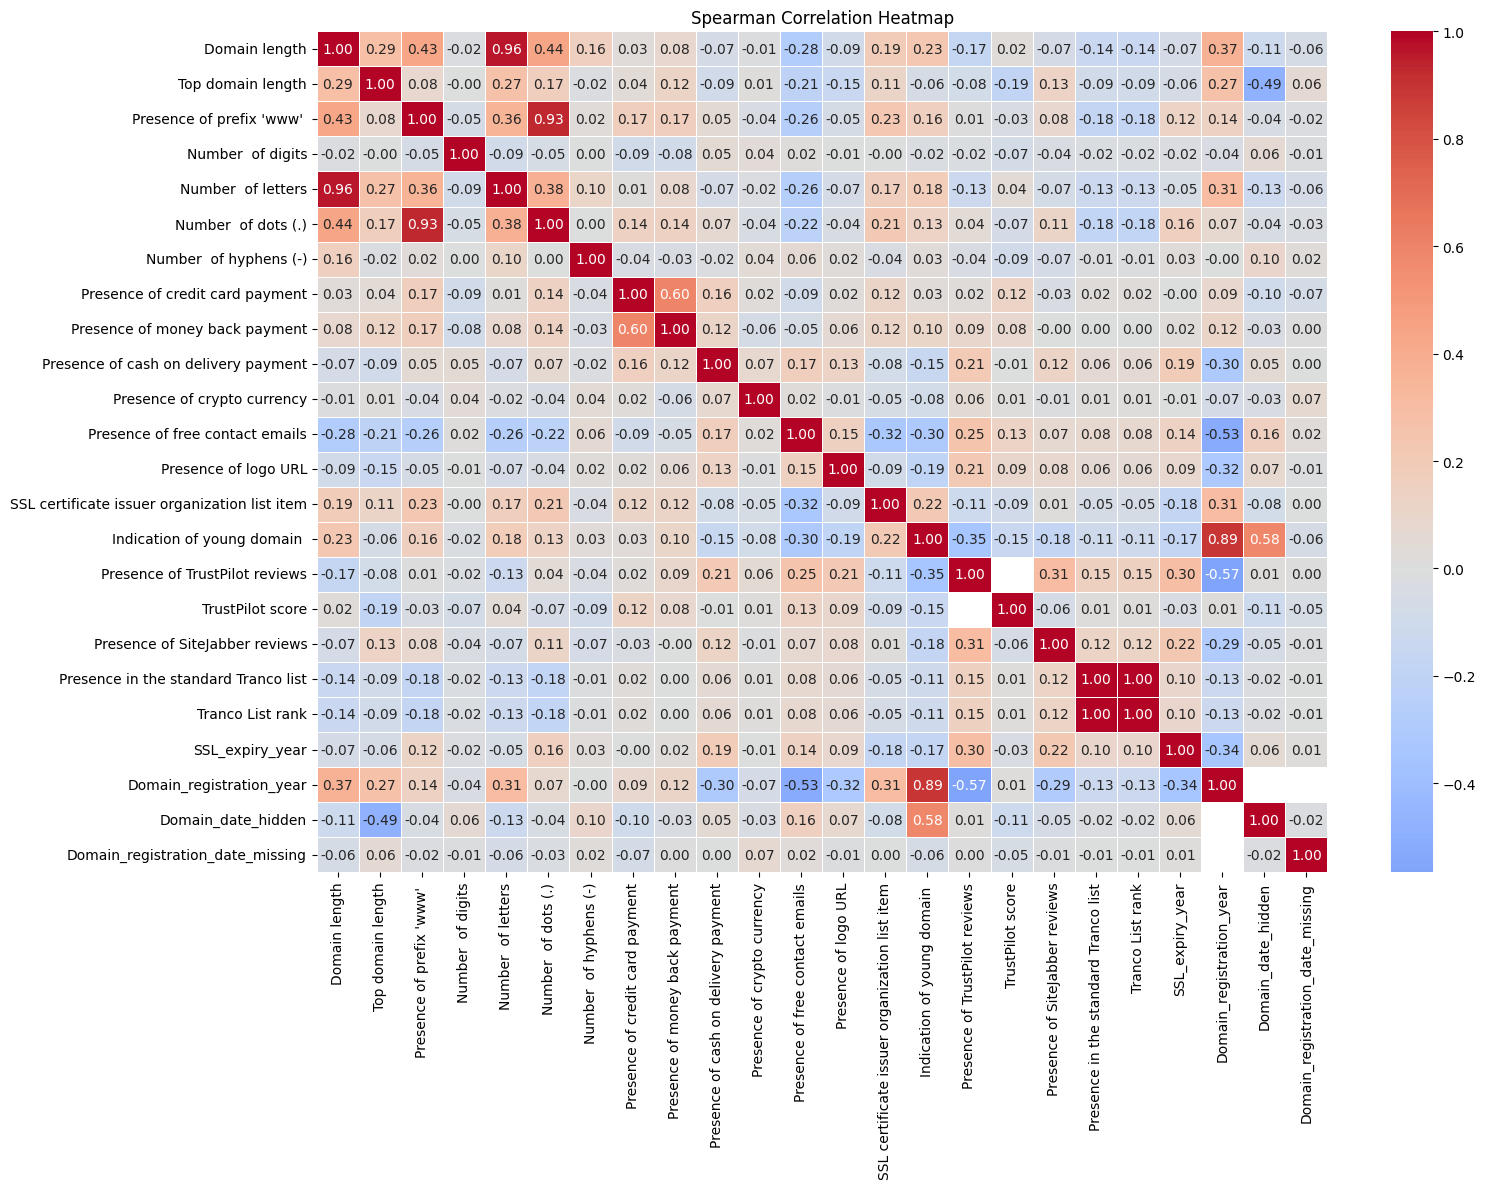

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    linewidths=0.5
)

plt.title('Spearman Correlation Heatmap')
plt.tight_layout()
plt.show()



In [ ]:

# ==========================================
# STEP 2.6.3 — INVESTIGATE CORRELATED PAIRS
# ==========================================

# 1. TRANCO FEATURES
print("=" * 60)
print("1. TRANCO AVAILABILITY VS RANK")
print("=" * 60)

print(pd.crosstab(
    df['Presence in the standard Tranco list'],
    df['Tranco List rank']
))

print("\nTranco rank distribution:")
print(
    df.groupby('Presence in the standard Tranco list')
      ['Tranco List rank']
      .describe()
)

# Check whether rank -1 consistently means unavailable
print("\nUnavailable but rank is not -1:")
print(
    (
        (df['Presence in the standard Tranco list'] == 0) &
        (df['Tranco List rank'] != -1)
    ).sum()
)

print("\nAvailable but rank is -1 or below:")
print(
    (
        (df['Presence in the standard Tranco list'] == 1) &
        (df['Tranco List rank'] <= 0)
    ).sum()
)


# 2. DOMAIN LENGTH VS LETTERS
print("\n" + "=" * 60)
print("2. DOMAIN LENGTH VS NUMBER OF LETTERS")
print("=" * 60)

df['Domain_length_minus_letters'] = (
    df['Domain length'] - df['Number  of letters']
)

print("\nDifference statistics:")
print(df['Domain_length_minus_letters'].describe())

print("\nDifference value counts:")
print(df['Domain_length_minus_letters'].value_counts().sort_index())


# 3. WWW PREFIX VS NUMBER OF DOTS
print("\n" + "=" * 60)
print("3. WWW PREFIX VS NUMBER OF DOTS")
print("=" * 60)

print(pd.crosstab(
    df["Presence of prefix 'www' "],
    df['Number  of dots (.)'],
    margins=True
))


# 4. YOUNG DOMAIN VS REGISTRATION YEAR
print("\n" + "=" * 60)
print("4. YOUNG DOMAIN VS REGISTRATION YEAR")
print("=" * 60)

print("\nRegistration year grouped by young-domain category:")

print(
    df.groupby('Indication of young domain ')
      ['Domain_registration_year']
      .agg(['count', 'min', 'max', 'mean'])
)

print("\nYoung-domain category vs hidden dates:")

print(pd.crosstab(
    df['Indication of young domain '],
    df['Domain_date_hidden'],
    margins=True
))

print("\nYoung-domain category vs genuinely missing dates:")

print(pd.crosstab(
    df['Indication of young domain '],
    df['Domain_registration_date_missing'],
    margins=True
))


1. TRANCO AVAILABILITY VS RANK
Tranco List rank                      -1        35556    90036    100803  \
Presence in the standard Tranco list                                       
0                                        1122        0        0        0   
1                                           0        1        1        1   

Tranco List rank                       346606   459343   481570   538286  \
Presence in the standard Tranco list                                       
0                                           0        0        0        0   
1                                           1        1        1        1   

Tranco List rank                       682488   750712   796877   797093  \
Presence in the standard Tranco list                                       
0                                           0        0        0        0   
1                                           1        1        1        1   

Tranco List rank                       802243   802653

In [ ]:

# ==========================================
# STEP 2.6.4 A — DOMAIN FEATURE VALIDATION
# ==========================================

# Remove temporary diagnostic feature
df.drop(
    columns=['Domain_length_minus_letters'],
    errors='ignore',
    inplace=True
)

# Display actual URL and extracted features
sample = df[[
    'Online shop URL',
    'Domain length',
    'Number  of letters',
    'Number  of dots (.)',
    "Presence of prefix 'www' "
]].sample(15, random_state=42).copy()

# Calculate actual string properties for investigation
sample['Actual URL length'] = (
    sample['Online shop URL'].astype(str).str.len()
)

sample['Actual alphabetic characters'] = (
    sample['Online shop URL']
    .astype(str)
    .str.count(r'[a-zA-Z]')
)

print(sample.to_string(index=False))


                Online shop URL  Domain length  Number  of letters  Number  of dots (.)  Presence of prefix 'www'   Actual URL length  Actual alphabetic characters
   https://www.on-vacation.club             20                  22                    2                          1                 28                            22
          https://www.getzoo.de             13                  16                    2                          1                 21                            16
        https://green-spirit.de             15                  18                    1                          0                 23                            18
   https://magyar-generikus.com             20                  23                    1                          0                 28                            23
    https://www.feworiesad.shop             19                  21                    2                          1                 27                            22
         https:/

In [ ]:

# ==========================================
# STEP 2.6.4 B — YOUNG DOMAIN VALIDATION
# ==========================================

# Inspect records registered in 2022
print("2022 Registration Year Records:")

print(
    df.loc[
        df['Domain_registration_year'] == 2022,
        [
            'Domain registration date',
            'Domain_registration_year',
            'Indication of young domain ',
            'Domain_date_hidden'
        ]
    ].to_string(index=False)
)

# Inspect genuinely missing dates
print("\nGenuinely Missing Registration Dates:")

print(
    df.loc[
        df['Domain_registration_date_missing'] == 1,
        [
            'Domain registration date',
            'Domain_registration_year',
            'Indication of young domain ',
            'Domain_date_hidden'
        ]
    ].to_string(index=False)
)

# Compare all categories
print("\nCategory-wise registration year distribution:")

print(
    pd.crosstab(
        df['Indication of young domain '],
        df['Domain_registration_year'],
        margins=True
    )
)


2022 Registration Year Records:
Domain registration date  Domain_registration_year  Indication of young domain   Domain_date_hidden
        2022-09-20 00:00                    2022.0                            1                   0
        2022-09-14 00:00                    2022.0                            1                   0
        2022-10-13 08:04                    2022.0                            1                   0
        2022-10-19 02:07                    2022.0                            1                   0
        2022-06-19 08:45                    2022.0                            0                   0
        2022-05-30 00:00                    2022.0                            0                   0
        2022-08-15 22:00                    2022.0                            1                   0
        2022-10-22 00:00                    2022.0                            1                   0
        2022-05-11 08:18                    2022.0                  

In [ ]:

# ==========================================
# STEP 2.6.5 — YOUNG DOMAIN THRESHOLD
# ==========================================

# Compare valid registration dates by category
print("Registration Date Range by Category:")

print(
    df.groupby('Indication of young domain ')
      ['Domain_registration_datetime']
      .agg(['count', 'min', 'max'])
)

# Inspect 2022 records around the category boundary
print("\n2022 Registration Dates Sorted:")

records_2022 = df.loc[
    df['Domain_registration_year'] == 2022,
    [
        'Domain_registration_datetime',
        'Indication of young domain '
    ]
].sort_values('Domain_registration_datetime')

print(records_2022.to_string(index=False))

# Find the latest category 0 date
category_0_latest = df.loc[
    df['Indication of young domain '] == 0,
    'Domain_registration_datetime'
].max()

# Find the earliest category 1 date
category_1_earliest = df.loc[
    df['Indication of young domain '] == 1,
    'Domain_registration_datetime'
].min()

print("\nLatest Category 0 Date:", category_0_latest)
print("Earliest Category 1 Date:", category_1_earliest)

# Verify hidden-date equivalence
hidden_equivalence = (
    df['Domain_date_hidden'] ==
    (df['Indication of young domain '] == 2).astype(int)
)

print("\nHidden Feature Equivalence:", hidden_equivalence.all())
print("Equivalence Mismatches:", (~hidden_equivalence).sum())


Registration Date Range by Category:
                             count                       min  \
Indication of young domain                                     
0                              546 1994-09-07 04:00:00+00:00   
1                              473 2022-06-27 15:51:00+00:00   
2                                0                       NaT   

                                                  max  
Indication of young domain                             
0                           2022-06-28 00:00:00+00:00  
1                           2023-08-18 02:14:00+00:00  
2                                                 NaT  

2022 Registration Dates Sorted:
Domain_registration_datetime  Indication of young domain 
   2022-02-08 08:46:00+00:00                            0
   2022-02-08 08:47:00+00:00                            0
   2022-02-23 00:28:00+00:00                            0
   2022-03-22 00:00:00+00:00                            0
   2022-03-23 12:44:00+00:00           

In [ ]:

# ==========================================
# STEP 2.6.6 — INVESTIGATE DATE OVERLAP
# ==========================================

boundary_records = df.loc[
    df['Domain_registration_datetime'].between(
        '2022-06-25',
        '2022-07-02'
    ),
    [
        'Online shop URL',
        'Domain registration date',
        'Domain_registration_datetime',
        'Domain_registration_year',
        'Indication of young domain ',
        'Domain_date_hidden',
        'Label'
    ]
].sort_values('Domain_registration_datetime')

print("Records Around Category Boundary:")
print(boundary_records.to_string(index=False))

print("\nCategory Counts Around Boundary:")

print(
    pd.crosstab(
        boundary_records['Domain_registration_datetime'].dt.date,
        boundary_records['Indication of young domain ']
    )
)


Records Around Category Boundary:
                 Online shop URL Domain registration date Domain_registration_datetime  Domain_registration_year  Indication of young domain   Domain_date_hidden      Label
        https://www.gedanusa.com         2022-06-27 01:55    2022-06-27 01:55:00+00:00                    2022.0                            0                   0 fraudulent
https://lekaren-slovenska247.com         2022-06-27 15:51    2022-06-27 15:51:00+00:00                    2022.0                            1                   0 fraudulent
    https://www.enzorepublika.cz               2022.06.28    2022-06-28 00:00:00+00:00                    2022.0                            0                   0 legitimate

Category Counts Around Boundary:
Indication of young domain    0  1
Domain_registration_datetime      
2022-06-27                    1  1
2022-06-28                    1  0


In [ ]:
# ==========================================
# STEP 2.6.7 — FINAL REDUNDANCY VALIDATION
# ==========================================

# 1. Verify Tranco availability indicator
tranco_check = (
    df['Presence in the standard Tranco list']
    ==
    (df['Tranco List rank'] != -1).astype(int)
)

print("TRanco equivalence:", tranco_check.all())
print("Tranco mismatches:", (~tranco_check).sum())


# 2. Verify hidden registration date indicator
hidden_check = (
    df['Domain_date_hidden']
    ==
    (df['Indication of young domain '] == 2).astype(int)
)

print("\nHidden-date equivalence:", hidden_check.all())
print("\nHidden-date mismatches:", (~hidden_check).sum())


# 3. Verify dataset integrity
print("\nOriginal backup shape:", df_original.shape)
print("Current dataset shape:", df.shape)

print("\nOriginal backup columns:", len(df_original.columns))
print("Current dataset columns:", len(df.columns))

TRanco equivalence: True
Tranco mismatches: 0

Hidden-date equivalence: True

Hidden-date mismatches: 0

Original backup shape: (1140, 26)
Current dataset shape: (1140, 33)

Original backup columns: 26
Current dataset columns: 33


In [ ]:

# ==========================================
# STEP 2.6.8 — DATASET COLUMN COMPARISON
# ==========================================

original_columns = set(df_original.columns)
current_columns = set(df.columns)

additional_columns = [
    col for col in df.columns
    if col not in original_columns
]

missing_original_columns = [
    col for col in df_original.columns
    if col not in current_columns
]

print("Original columns:", len(df_original.columns))
print("Current columns:", len(df.columns))

print("\nAdditional columns created during EDA:")
for col in additional_columns:
    print("-", col)

print("\nOriginal columns missing from current dataset:")
for col in missing_original_columns:
    print("-", col)

print("\nCurrent dataset shape:", df.shape)


Original columns: 26
Current columns: 33

Additional columns created during EDA:
- SSL_expiry_datetime
- SSL_expiry_year
- SSL_expiry_month
- Domain_registration_datetime
- Domain_registration_year
- Domain_date_hidden
- Domain_registration_date_missing

Original columns missing from current dataset:

Current dataset shape: (1140, 33)


In [ ]:

# ==========================================
# STEP 3.1 — MISSINGNESS PATTERN INVESTIGATION
# ==========================================

# 1. Identify TrustPilot-related columns
trustpilot_cols = [
    col for col in df.columns
    if 'trustpilot' in col.lower()
]

print("TrustPilot columns:")
print(trustpilot_cols)

# 2. Identify score and review columns
score_col = next(
    (c for c in trustpilot_cols if 'score' in c.lower()),
    None
)

review_col = next(
    (c for c in trustpilot_cols if 'review' in c.lower()),
    None
)

# 3. Investigate TrustPilot score missingness
if score_col:
    print("\nTrustPilot score missingness:")
    print("Total missing:", df[score_col].isna().sum())
    print("Total available:", df[score_col].notna().sum())
    print("Missing percentage:",
          round(df[score_col].isna().mean() * 100, 2), "%")

    print("\nScore statistics:")
    display(df[score_col].describe())

# 4. Compare missing scores with review availability
if score_col and review_col:
    df['TrustPilot_score_missing_check'] = (
        df[score_col].isna().astype(int)
    )

    print("\nScore missingness vs review availability:")
    display(pd.crosstab(
        df[review_col],
        df['TrustPilot_score_missing_check'],
        margins=True
    ))

    print("\nPercentage distribution:")
    display(pd.crosstab(
        df[review_col],
        df['TrustPilot_score_missing_check'],
        normalize='index'
    ).round(3))

# 5. Investigate domain registration date missingness
date_col = 'Domain registration date'
indicator_col = 'Domain_registration_date_missing'

if date_col in df.columns:
    print("\nDomain registration date missing:")
    print(df[date_col].isna().sum())

    if indicator_col in df.columns:
        date_check = (
            df[date_col].isna().astype(int)
            == df[indicator_col]
        )

        print("Missing indicator equivalence:", date_check.all())
        print("Mismatches:", (~date_check).sum())

# 6. Display records with missing domain registration dates
if date_col in df.columns:
    print("\nRecords with missing registration dates:")
    display(df[df[date_col].isna()])


TrustPilot columns:
['Presence of TrustPilot reviews', 'TrustPilot score']

TrustPilot score missingness:
Total missing: 885
Total available: 255
Missing percentage: 77.63 %

Score statistics:


,TrustPilot score
count,255.000000
mean,3.582745
std,0.960159
min,1.000000
25%,2.900000
50%,3.700000
75%,4.400000
max,5.000000



Score missingness vs review availability:


TrustPilot_score_missing_check,0,1,All
Presence of TrustPilot reviews,,,
0,0,885,885
1,255,0,255
All,255,885,1140



Percentage distribution:


TrustPilot_score_missing_check,0,1
Presence of TrustPilot reviews,,
0,0.0,1.0
1,1.0,0.0



Domain registration date missing:
4
Missing indicator equivalence: True
Mismatches: 0

Records with missing registration dates:


,Online shop URL,Label,Domain length,Top domain length,Presence of prefix 'www',Number of digits,Number of letters,Number of dots (.),Number of hyphens (-),Presence of credit card payment,...,Presence in the standard Tranco list,Tranco List rank,SSL_expiry_datetime,SSL_expiry_year,SSL_expiry_month,Domain_registration_datetime,Domain_registration_year,Domain_date_hidden,Domain_registration_date_missing,TrustPilot_score_missing_check
229,https://get-rc.to,fraudulent,9,2,0,0,12,1,1,0,...,0,-1,2023-09-21 08:29:58+00:00,2023,2023-09,NaT,NaN,0,1,0
263,https://axfritz.shop,fraudulent,12,4,0,0,16,1,0,0,...,0,-1,2023-10-25 22:46:20+00:00,2023,2023-10,NaT,NaN,0,1,1
1138,https://www.arlton.shop,fraudulent,15,4,1,0,18,2,0,1,...,0,-1,2023-10-29 11:30:40+00:00,2023,2023-10,NaT,NaN,0,1,1
1139,https://www.ghingwala.shop,fraudulent,18,4,1,0,21,2,0,0,...,0,-1,2024-03-16 23:59:59+00:00,2024,2024-03,NaT,NaN,0,1,1


In [ ]:

# Remove temporary investigation column

if 'TrustPilot_score_missing_check' in df.columns:
    df.drop(
        columns=['TrustPilot_score_missing_check'],
        inplace=True
    )

print("Updated dataset shape:", df.shape)
print("Temporary column removed:",
      'TrustPilot_score_missing_check' not in df.columns)


Updated dataset shape: (1140, 33)
Temporary column removed: True


In [ ]:

# ==========================================
# STEP 3.2 — MISSINGNESS VS TARGET ANALYSIS
# ==========================================

# 1. TrustPilot review presence vs target
print("TrustPilot review presence by target:")

display(pd.crosstab(
    df['Label'],
    df['Presence of TrustPilot reviews'],
    margins=True
))

print("\nPercentage distribution:")

display(pd.crosstab(
    df['Label'],
    df['Presence of TrustPilot reviews'],
    normalize='index'
).round(3) * 100)


# 2. TrustPilot score statistics by target
print("\nTrustPilot score statistics by target:")

display(
    df.groupby('Label')['TrustPilot score']
    .describe()
)


# 3. Domain registration date missingness vs target
print("\nDomain registration date missingness by target:")

display(pd.crosstab(
    df['Label'],
    df['Domain_registration_date_missing'],
    margins=True
))

print("\nPercentage distribution:")

display(pd.crosstab(
    df['Label'],
    df['Domain_registration_date_missing'],
    normalize='index'
).round(4) * 100)


# 4. Final missing value overview
print("\nRemaining missing values:")

missing_summary = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Missing Percentage': (
        df.isnull().mean() * 100
    ).round(2)
})

display(
    missing_summary[missing_summary['Missing Values'] > 0]
)


TrustPilot review presence by target:


Presence of TrustPilot reviews,0,1,All
Label,,,
fraudulent,560,19,579
legitimate,325,236,561
All,885,255,1140



Percentage distribution:


Presence of TrustPilot reviews,0,1
Label,,
fraudulent,96.7,3.3
legitimate,57.9,42.1



TrustPilot score statistics by target:


,count,mean,std,min,25%,50%,75%,max
Label,,,,,,,,
fraudulent,19.0,3.252632,0.488044,2.3,3.0,3.2,3.65,4.1
legitimate,236.0,3.609322,0.984215,1.0,2.9,3.8,4.40,5.0


... (2 outputs left out)


Percentage distribution:


Domain_registration_date_missing,0,1
Label,,
fraudulent,99.31,0.69
legitimate,100.00,0.00



Remaining missing values:


,Missing Values,Missing Percentage
Domain registration date,4,0.35
TrustPilot score,885,77.63
Domain_registration_datetime,121,10.61
Domain_registration_year,121,10.61


In [ ]:

# ==========================================
# STEP 3.3 — DATE CONVERSION INVESTIGATION
# ==========================================

raw_col = 'Domain registration date'
datetime_col = 'Domain_registration_datetime'
year_col = 'Domain_registration_year'

# 1. Compare missing values
print("MISSING VALUE COMPARISON")

print("Original date missing:",
      df[raw_col].isna().sum())

print("Converted datetime missing:",
      df[datetime_col].isna().sum())

print("Registration year missing:",
      df[year_col].isna().sum())


# 2. Find non-missing original dates that became NaT
conversion_failures = df[
    df[raw_col].notna() &
    df[datetime_col].isna()
]

print("\nOriginal dates that failed datetime conversion:")
print("Total:", len(conversion_failures))

display(
    conversion_failures[
        ['Online shop URL', raw_col, datetime_col,
         year_col, 'Label']
    ]
)


# 3. Check whether year missingness matches datetime missingness
year_datetime_check = (
    df[year_col].isna() ==
    df[datetime_col].isna()
)

print("\nYear and datetime missingness equivalence:",
      year_datetime_check.all())

print("Mismatches:",
      (~year_datetime_check).sum())


# 4. Inspect original date value formats
print("\nOriginal date data type:")
print(df[raw_col].dtype)

print("\nOriginal date sample values:")
display(df[raw_col].dropna().sample(
    min(20, df[raw_col].notna().sum()),
    random_state=42
))


# 5. Inspect original date values that appear unusual
print("\nOriginal date value frequencies:")
display(df.loc[
    df[raw_col].notna(),
    raw_col
].value_counts().head(30))


MISSING VALUE COMPARISON
Original date missing: 4
Converted datetime missing: 121
Registration year missing: 121

Original dates that failed datetime conversion:
Total: 117


,Online shop URL,Domain registration date,Domain_registration_datetime,Domain_registration_year,Label
2,https://www.waeschenamen-windrath.de,Hidden,NaT,NaN,legitimate
10,https://www.kaffee-partner-shop.de,Hidden,NaT,NaN,legitimate
50,https://babylachelt.de,Hidden,NaT,NaN,fraudulent
87,https://celivaa.de,Hidden,NaT,NaN,fraudulent
108,https://www.jeans24h.eu,Hidden,NaT,NaN,legitimate
...,...,...,...,...,...
1107,https://weinteufel.de,Hidden,NaT,NaN,legitimate
1108,https://www.77onlineshop.eu,Hidden,NaT,NaN,legitimate
1123,https://www.scandinavian-lifestyle.de,Hidden,NaT,NaN,legitimate
1125,https://sockwell.eu,Hidden,NaT,NaN,legitimate



Year and datetime missingness equivalence: True
Mismatches: 0

Original date data type:
object

Original date sample values:


,Domain registration date
788,2016-06-12 16:19
904,Hidden
291,Hidden
827,2023-06-28 04:34
334,2023-07-04 07:27
109,2015-09-24 00:00
596,2023-06-16 07:47
56,2014-08-04 17:04
752,Hidden
241,2022-11-25 00:33



Original date value frequencies:


,count
Domain registration date,
Hidden,117
2023-06-06 00:00,7
2023-06-08 00:00,6
2023-05-11 00:00,5
2023-03-21 00:00,5
2023-03-16 00:00,5
2023-07-06 00:00,5
2023-05-08 00:00,5
2020-06-01 17:00,4


In [ ]:

# ==========================================
# STEP 3.3.1 — FINAL DATE CATEGORY VALIDATION
# ==========================================

raw_col = 'Domain registration date'
datetime_col = 'Domain_registration_datetime'
hidden_col = 'Domain_date_hidden'
missing_col = 'Domain_registration_date_missing'
young_col = 'Indication of young domain '

# Identify original date categories
is_hidden = df[raw_col].eq('Hidden')
is_missing = df[raw_col].isna()
is_valid_date = df[raw_col].notna() & ~is_hidden

print("ORIGINAL DATE CATEGORIES")
print("Valid dates:", is_valid_date.sum())
print("Hidden dates:", is_hidden.sum())
print("Genuinely missing:", is_missing.sum())

# Validate hidden-date indicator
hidden_check = (
    df[hidden_col] == is_hidden.astype(int)
)

print("\nHidden indicator matches original data:",
      hidden_check.all())
print("Hidden mismatches:", (~hidden_check).sum())

# Validate genuine missing-date indicator
missing_check = (
    df[missing_col] == is_missing.astype(int)
)

print("\nMissing indicator matches original data:",
      missing_check.all())
print("Missing mismatches:", (~missing_check).sum())

# Validate original young-domain classification
young_hidden_check = (
    df[young_col] == 2
) == is_hidden

print("\nYoung-domain hidden category matches:",
      young_hidden_check.all())
print("Mismatches:", (~young_hidden_check).sum())

# Validate converted datetime
print("\nDATETIME VALIDATION")
print("Valid original dates converted:",
      df.loc[is_valid_date, datetime_col].notna().sum())

print("Hidden dates converted to NaT:",
      df.loc[is_hidden, datetime_col].isna().sum())

print("Missing dates converted to NaT:",
      df.loc[is_missing, datetime_col].isna().sum())

# Confirm dataset shape
print("\nFINAL DATASET SHAPE:", df.shape)



ORIGINAL DATE CATEGORIES
Valid dates: 1019
Hidden dates: 117
Genuinely missing: 4

Hidden indicator matches original data: True
Hidden mismatches: 0

Missing indicator matches original data: True
Missing mismatches: 0

Young-domain hidden category matches: True
Mismatches: 0

DATETIME VALIDATION
Valid original dates converted: 1019
Hidden dates converted to NaT: 117
Missing dates converted to NaT: 4

FINAL DATASET SHAPE: (1140, 33)


In [ ]:
# ==========================================
# STEP 3.4.2 — IMPUTATION STRATEGY CHECK
# ==========================================

# A. TrustPilot score
print("TRUSTPILOT SCORE")
print("Missing values:", df['TrustPilot score'].isna().sum())
print("Available values:", df['TrustPilot score'].notna().sum())
print("Median of available scores:",
      df['TrustPilot score'].median())

# Verify missing scores correspond to no reviews
trustpilot_check = (
    df['TrustPilot score'].isna()
    == (df['Presence of TrustPilot reviews'] == 0)
)

print("Missing score matches no-review status:",
      trustpilot_check.all())
print("Mismatches:", (~trustpilot_check).sum())


# B. Domain registration year
print("\nDOMAIN REGISTRATION YEAR")
print("Missing values:", df['Domain_registration_year'].isna().sum())
print("Available values:", df['Domain_registration_year'].notna().sum())
print("Median of available years:",
      df['Domain_registration_year'].median())


# C. Separate hidden dates from genuinely missing dates
print("\nDATE MISSINGNESS BREAKDOWN")

print("Hidden dates:",
      df['Domain_date_hidden'].sum())

print("Genuinely missing dates:",
      df['Domain_registration_date_missing'].sum())

print("Total missing registration years:",
      df['Domain_registration_year'].isna().sum())

print("Hidden dates correctly represented:",
      (
          df['Domain_registration_year'].isna()
          & (df['Domain_date_hidden'] == 1)
      ).sum())

print("Genuinely missing dates correctly represented:",
      (
          df['Domain_registration_year'].isna()
          & (df['Domain_registration_date_missing'] == 1)
      ).sum())

# D. Confirm no dataset modification
print("\nDATASET SHAPE:", df.shape)

TRUSTPILOT SCORE
Missing values: 885
Available values: 255
Median of available scores: 3.7
Missing score matches no-review status: True
Mismatches: 0

DOMAIN REGISTRATION YEAR
Missing values: 121
Available values: 1019
Median of available years: 2021.0

DATE MISSINGNESS BREAKDOWN
Hidden dates: 117
Genuinely missing dates: 4
Total missing registration years: 121
Hidden dates correctly represented: 117
Genuinely missing dates correctly represented: 4

DATASET SHAPE: (1140, 33)


In [ ]:

# ==========================================
# STEP 4.1 — NUMERICAL FEATURE OUTLIER CHECK
# ==========================================

# 1. Select numerical columns
numeric_df = df.select_dtypes(include='number')

# 2. Exclude binary and low-cardinality features
continuous_features = [
    col for col in numeric_df.columns
    if numeric_df[col].nunique() > 10
]

print("Continuous numerical features:")
print(continuous_features)

print("\n" + "=" * 70)

# 3. Calculate IQR outliers
outlier_results = []

for col in continuous_features:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ][col]

    outlier_results.append({

        'Feature': col,
        'Q1': Q1,
        'Q3': Q3,
        'IQR': IQR,
        'Lower Bound': lower_bound,
        'Upper Bound': upper_bound,
        'Outlier Count': len(outliers),
        'Outlier Percentage': (
            len(outliers) / len(df)
        ) * 100

    })

# 4. Display summary
outlier_summary = pd.DataFrame(outlier_results)

print("\nOUTLIER SUMMARY")

display(outlier_summary)


Continuous numerical features:
['Domain length', 'Number  of letters', 'SSL certificate issuer organization list item', 'TrustPilot score', 'Tranco List rank', 'Domain_registration_year']


OUTLIER SUMMARY


,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,Domain length,15.0,21.00,6.00,6.000,30.000,8,0.701754
1,Number of letters,19.0,24.25,5.25,11.125,32.125,19,1.666667
2,SSL certificate issuer organization list item,2.0,9.00,7.00,-8.500,19.500,0,0.000000
3,TrustPilot score,2.9,4.40,1.50,0.650,6.650,0,0.000000
4,Tranco List rank,-1.0,-1.00,0.00,-1.000,-1.000,18,1.578947
5,Domain_registration_year,2012.0,2023.00,11.00,1995.500,2039.500,8,0.701754


In [ ]:

# ==========================================
# STEP 4.3 — INSPECT POTENTIAL OUTLIERS
# ==========================================

# Features requiring investigation
features_to_inspect = [
    'Domain length',
    'Number  of letters',
    'Domain_registration_year'
]

# Identify and display actual outlier records
for col in features_to_inspect:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    print("\n" + "=" * 75)
    print(f"FEATURE: {col}")
    print(f"Lower Bound: {lower_bound}")
    print(f"Upper Bound: {upper_bound}")
    print(f"Outlier Count: {len(outliers)}")
    print("=" * 75)

    display(
        outliers[
            ['Online shop URL', 'Label', col]
        ].sort_values(by=col)
    )


# ==========================================
# INVESTIGATE TRANCO LIST RANK SEPARATELY
# ==========================================

print("\n" + "=" * 75)
print("TRANCO LIST RANK INVESTIGATION")
print("=" * 75)

print("\nValue distribution:")
display(
    df['Tranco List rank']
    .value_counts(dropna=False)
    .sort_index()
)

print("\nUnavailable rank count (-1):")
print((df['Tranco List rank'] == -1).sum())

print("\nAvailable rank count:")
print(
    (df['Tranco List rank'] != -1).sum()
)

# Analyze actual available ranks separately

available_ranks = df.loc[
    df['Tranco List rank'] != -1,
    'Tranco List rank'
]

print("\nAvailable rank statistics:")
display(available_ranks.describe())

print("\nSmallest available ranks:")
print(available_ranks.nsmallest(10).to_list())

print("\nLargest available ranks:")
print(available_ranks.nlargest(10).to_list())


# ==========================================
# STEP 4.3 STATUS
# ==========================================

print("\nInvestigation completed.")
print("No values have been modified or removed.")



FEATURE: Domain length
Lower Bound: 6.0
Upper Bound: 30.0
Outlier Count: 8


,Online shop URL,Label,Domain length
1009,https://www.proportional-dispensers.com,legitimate,31
894,https://www.altonaer-silberwerkstatt.de,legitimate,31
818,https://www.internet-sportandcasuals.com,legitimate,32
749,https://www.kamagra-online-bestellen.com,fraudulent,32
855,https://www.creative-metallgestaltung.at,legitimate,32
991,https://www.lukasmullerwelpenzuhause.com,fraudulent,32
478,https://www.westminsterflowersandgifts.com,legitimate,34
39,https://www.b2bglobalchemicalmerchandise.co.za,fraudulent,38



FEATURE: Number  of letters
Lower Bound: 11.125
Upper Bound: 32.125
Outlier Count: 19


,Online shop URL,Label,Number of letters
138,https://nydj.eu,legitimate,11
614,https://avfx.eu,legitimate,11
566,https://e-zoo.lt,legitimate,11
285,https://247blue.de,fraudulent,11
964,https://hero.lt,legitimate,11
910,https://foys.ie,legitimate,11
756,https://ielm.us,legitimate,11
161,https://www.gesundefamiliehaustiere.de,fraudulent,33
894,https://www.altonaer-silberwerkstatt.de,legitimate,33
828,https://whiskyinternationalonline.com,legitimate,33



FEATURE: Domain_registration_year
Lower Bound: 1995.5
Upper Bound: 2039.5
Outlier Count: 8


,Online shop URL,Label,Domain_registration_year
589,https://www.qvc.com,legitimate,1994.0
444,https://store.acer.com/index.htm,legitimate,1994.0
211,https://www.elcorteingles.com,legitimate,1995.0
172,https://www.officiellejordan.eu.com,fraudulent,1995.0
608,https://www.boots.com,legitimate,1995.0
896,https://www.newlook.com/ro,legitimate,1995.0
1005,https://www.barnesandnoble.com,legitimate,1995.0
1067,https://www.mistral.com,legitimate,1995.0



TRANCO LIST RANK INVESTIGATION

Value distribution:


,count
Tranco List rank,
-1,1122
35556,1
90036,1
100803,1
346606,1
459343,1
481570,1
538286,1
682488,1



Unavailable rank count (-1):
1122

Available rank count:
18

Available rank statistics:


,Tranco List rank
count,18.000000
mean,615077.833333
std,298694.837130
min,35556.000000
25%,464899.750000
50%,773794.500000
75%,804128.250000
max,964101.000000



Smallest available ranks:
[35556, 90036, 100803, 346606, 459343, 481570, 538286, 682488, 750712, 796877]

Largest available ranks:
[964101, 918108, 875089, 825217, 804620, 802653, 802243, 797093, 796877, 750712]

Investigation completed.
No values have been modified or removed.


In [ ]:

# ==========================================
# STEP 5.1A — EXACT DUPLICATE FEATURE CHECK
# ==========================================

print("Dataset shape:", df.shape)

duplicate_pairs = []

columns = df.columns.tolist()

for i in range(len(columns)):
    for j in range(i + 1, len(columns)):

        col1 = columns[i]
        col2 = columns[j]

        if df[col1].equals(df[col2]):
            duplicate_pairs.append({
                'Feature 1': col1,
                'Feature 2': col2
            })

print("\nEXACT DUPLICATE COLUMNS")

if duplicate_pairs:
    display(pd.DataFrame(duplicate_pairs))
else:
    print("No exact duplicate columns found.")


# Check previously suspected duplicate features
suspected_pairs = [
    (
        'Tranco Available',
        'Presence in the standard Tranco list'
    )
]

print("\nSUSPECTED REDUNDANT FEATURES")

for col1, col2 in suspected_pairs:

    if col1 in df.columns and col2 in df.columns:

        print(f"\n{col1} vs {col2}")

        print("Identical:", df[col1].equals(df[col2]))

        print("\nCross-tabulation:")
        display(pd.crosstab(
            df[col1],
            df[col2],
            dropna=False
        ))

    else:
        print(f"Column not found: {col1} or {col2}")


Dataset shape: (1140, 33)

EXACT DUPLICATE COLUMNS
No exact duplicate columns found.

SUSPECTED REDUNDANT FEATURES
Column not found: Tranco Available or Presence in the standard Tranco list


In [ ]:

# ==========================================
# STEP 5.1B — NUMERICAL CORRELATION ANALYSIS
# ==========================================

# Select numerical features
numeric_df = df.select_dtypes(include='number').drop(
    columns=['Tranco List rank'],
    errors='ignore'
)

# Exclude target if it is numerical
numeric_df = numeric_df.drop(
    columns=['Label'],
    errors='ignore'
)

# Pearson correlation
pearson_corr = numeric_df.corr(method='pearson')

# Spearman correlation
spearman_corr = numeric_df.corr(method='spearman')

print("PEARSON CORRELATION MATRIX")
display(pearson_corr.round(2))

print("\nSPEARMAN CORRELATION MATRIX")
display(spearman_corr.round(2))


# Identify highly correlated feature pairs
def get_high_correlations(correlation_matrix, threshold=0.80):

    results = []

    for i in range(len(correlation_matrix.columns)):
        for j in range(i + 1, len(correlation_matrix.columns)):

            feature1 = correlation_matrix.columns[i]
            feature2 = correlation_matrix.columns[j]

            correlation = correlation_matrix.iloc[i, j]

            if abs(correlation) >= threshold:

                results.append({
                    'Feature 1': feature1,
                    'Feature 2': feature2,
                    'Correlation': correlation,
                    'Absolute Correlation': abs(correlation)
                })

    return pd.DataFrame(results)


print("\nHIGH PEARSON CORRELATIONS (>= 0.80)")

pearson_high = get_high_correlations(
    pearson_corr,
    threshold=0.80
)

display(pearson_high)

print("\nHIGH SPEARMAN CORRELATIONS (>= 0.80)")

spearman_high = get_high_correlations(
    spearman_corr,
    threshold=0.80
)

display(spearman_high)


PEARSON CORRELATION MATRIX


,Domain length,Top domain length,Presence of prefix 'www',Number of digits,Number of letters,Number of dots (.),Number of hyphens (-),Presence of credit card payment,Presence of money back payment,Presence of cash on delivery payment,...,SSL certificate issuer organization list item,Indication of young domain,Presence of TrustPilot reviews,TrustPilot score,Presence of SiteJabber reviews,Presence in the standard Tranco list,SSL_expiry_year,Domain_registration_year,Domain_date_hidden,Domain_registration_date_missing
Domain length,1.00,0.24,0.44,-0.02,0.96,0.45,0.18,0.01,0.07,-0.06,...,0.18,0.17,-0.15,0.02,-0.06,-0.14,-0.04,0.28,-0.10,-0.06
Top domain length,0.24,1.00,0.03,-0.01,0.22,0.21,-0.05,-0.01,0.05,-0.05,...,0.06,-0.11,-0.04,-0.16,0.13,-0.07,-0.04,0.08,-0.34,0.05
Presence of prefix 'www',0.44,0.03,1.00,-0.05,0.36,0.91,0.03,0.17,0.17,0.05,...,0.26,0.13,0.01,-0.06,0.08,-0.18,0.12,0.02,-0.04,-0.02
Number of digits,-0.02,-0.01,-0.05,1.00,-0.10,-0.06,-0.00,-0.09,-0.05,0.04,...,0.00,-0.02,-0.02,-0.02,-0.04,-0.02,-0.02,0.03,0.05,-0.01
Number of letters,0.96,0.22,0.36,-0.10,1.00,0.39,0.12,-0.01,0.06,-0.06,...,0.15,0.13,-0.11,0.05,-0.07,-0.13,-0.02,0.23,-0.11,-0.07
Number of dots (.),0.45,0.21,0.91,-0.06,0.39,1.00,0.01,0.13,0.14,0.07,...,0.24,0.10,0.06,-0.09,0.13,-0.18,0.16,-0.06,-0.04,-0.03
Number of hyphens (-),0.18,-0.05,0.03,-0.00,0.12,0.01,1.00,-0.03,-0.02,-0.00,...,-0.05,0.04,-0.03,-0.03,-0.07,-0.01,0.05,-0.00,0.10,0.01
Presence of credit card payment,0.01,-0.01,0.17,-0.09,-0.01,0.13,-0.03,1.00,0.60,0.16,...,0.14,0.01,0.02,0.12,-0.03,0.02,-0.00,0.03,-0.10,-0.07
Presence of money back payment,0.07,0.05,0.17,-0.05,0.06,0.14,-0.02,0.60,1.00,0.12,...,0.15,0.08,0.09,0.09,-0.00,0.00,0.02,0.03,-0.03,0.00
Presence of cash on delivery payment,-0.06,-0.05,0.05,0.04,-0.06,0.07,-0.00,0.16,0.12,1.00,...,-0.07,-0.12,0.21,-0.01,0.12,0.06,0.19,-0.29,0.05,0.00



SPEARMAN CORRELATION MATRIX


,Domain length,Top domain length,Presence of prefix 'www',Number of digits,Number of letters,Number of dots (.),Number of hyphens (-),Presence of credit card payment,Presence of money back payment,Presence of cash on delivery payment,...,SSL certificate issuer organization list item,Indication of young domain,Presence of TrustPilot reviews,TrustPilot score,Presence of SiteJabber reviews,Presence in the standard Tranco list,SSL_expiry_year,Domain_registration_year,Domain_date_hidden,Domain_registration_date_missing
Domain length,1.00,0.29,0.43,-0.02,0.96,0.44,0.16,0.03,0.08,-0.07,...,0.19,0.23,-0.17,0.02,-0.07,-0.14,-0.07,0.37,-0.11,-0.06
Top domain length,0.29,1.00,0.08,-0.00,0.27,0.17,-0.02,0.04,0.12,-0.09,...,0.11,-0.06,-0.08,-0.19,0.13,-0.09,-0.06,0.27,-0.49,0.06
Presence of prefix 'www',0.43,0.08,1.00,-0.05,0.36,0.93,0.02,0.17,0.17,0.05,...,0.23,0.16,0.01,-0.03,0.08,-0.18,0.12,0.14,-0.04,-0.02
Number of digits,-0.02,-0.00,-0.05,1.00,-0.09,-0.05,0.00,-0.09,-0.08,0.05,...,-0.00,-0.02,-0.02,-0.07,-0.04,-0.02,-0.02,-0.04,0.06,-0.01
Number of letters,0.96,0.27,0.36,-0.09,1.00,0.38,0.10,0.01,0.08,-0.07,...,0.17,0.18,-0.13,0.04,-0.07,-0.13,-0.05,0.31,-0.13,-0.06
Number of dots (.),0.44,0.17,0.93,-0.05,0.38,1.00,0.00,0.14,0.14,0.07,...,0.21,0.13,0.04,-0.07,0.11,-0.18,0.16,0.07,-0.04,-0.03
Number of hyphens (-),0.16,-0.02,0.02,0.00,0.10,0.00,1.00,-0.04,-0.03,-0.02,...,-0.04,0.03,-0.04,-0.09,-0.07,-0.01,0.03,-0.00,0.10,0.02
Presence of credit card payment,0.03,0.04,0.17,-0.09,0.01,0.14,-0.04,1.00,0.60,0.16,...,0.12,0.03,0.02,0.12,-0.03,0.02,-0.00,0.09,-0.10,-0.07
Presence of money back payment,0.08,0.12,0.17,-0.08,0.08,0.14,-0.03,0.60,1.00,0.12,...,0.12,0.10,0.09,0.08,-0.00,0.00,0.02,0.12,-0.03,0.00
Presence of cash on delivery payment,-0.07,-0.09,0.05,0.05,-0.07,0.07,-0.02,0.16,0.12,1.00,...,-0.08,-0.15,0.21,-0.01,0.12,0.06,0.19,-0.30,0.05,0.00



HIGH PEARSON CORRELATIONS (>= 0.80)


,Feature 1,Feature 2,Correlation,Absolute Correlation
0,Domain length,Number of letters,0.959806,0.959806
1,Presence of prefix 'www',Number of dots (.),0.909316,0.909316



HIGH SPEARMAN CORRELATIONS (>= 0.80)


,Feature 1,Feature 2,Correlation,Absolute Correlation
0,Domain length,Number of letters,0.962051,0.962051
1,Presence of prefix 'www',Number of dots (.),0.927422,0.927422
2,Indication of young domain,Domain_registration_year,0.893754,0.893754


In [ ]:

# ==========================================
# STEP 5.1C — FEATURE REDUNDANCY INVESTIGATION
# ==========================================

# 1. Young-domain category vs hidden registration date

if (
    'Indication of young domain' in df.columns
    and 'Domain_date_hidden' in df.columns
):

    print("YOUNG DOMAIN vs HIDDEN DATE")

    display(pd.crosstab(
        df['Indication of young domain'],
        df['Domain_date_hidden'],
        dropna=False
    ))


# 2. Domain length relationships

domain_features = [
    'Domain length',
    'Top domain length',
    'Number  of letters',
    'Domain_Letter_Difference'
]

available_features = [
    col for col in domain_features
    if col in df.columns
]

print("\nDOMAIN FEATURE RELATIONSHIPS")

display(
    df[available_features].corr(method='pearson').round(3)
)


# Check possible mathematical relationships
if all(
    col in df.columns
    for col in [
        'Domain length',
        'Top domain length',
        'Domain_Letter_Difference'
    ]
):

    domain_length_difference = (
        df['Domain length'] - df['Top domain length']
    )

    print("\nDOMAIN LETTER DIFFERENCE CHECK")

    print(
        "Matches Domain length - Top domain length:",
        df['Domain_Letter_Difference'].equals(
            domain_length_difference
        )
    )

    print(
        "Matches absolute difference:",
        df['Domain_Letter_Difference'].equals(
            domain_length_difference.abs()
        )
    )


# 3. Registration date representations

registration_features = [
    'Domain registration date',
    'Domain_registration_datetime',
    'Domain_registration_year',
    'Domain_date_hidden'
]

registration_features = [
    col for col in registration_features
    if col in df.columns
]

print("\nREGISTRATION DATE FEATURES")

display(df[registration_features].head(10))


# 4. SSL expiry date representations

ssl_features = [
    'SSL certificate expire date',
    'SSL_expiry_datetime',
    'SSL_expiry_year',
    'SSL_expiry_month'
]

ssl_features = [
    col for col in ssl_features
    if col in df.columns
]

print("\nSSL EXPIRY FEATURES")

display(df[ssl_features].head(10))



DOMAIN FEATURE RELATIONSHIPS


,Domain length,Top domain length,Number of letters
Domain length,1.000,0.237,0.960
Top domain length,0.237,1.000,0.216
Number of letters,0.960,0.216,1.000



REGISTRATION DATE FEATURES


,Domain registration date,Domain_registration_datetime,Domain_registration_year,Domain_date_hidden
0,2023-05-15 03:35,2023-05-15 03:35:00+00:00,2023.0,0
1,2023-06-18 05:43,2023-06-18 05:43:00+00:00,2023.0,0
2,Hidden,NaT,NaN,1
3,2022-09-20 00:00,2022-09-20 00:00:00+00:00,2022.0,0
4,2023-07-27 09:05,2023-07-27 09:05:00+00:00,2023.0,0
5,2023-06-15 08:46,2023-06-15 08:46:00+00:00,2023.0,0
6,2015-04-16 00:22,2015-04-16 00:22:00+00:00,2015.0,0
7,2022-09-14 00:00,2022-09-14 00:00:00+00:00,2022.0,0
8,2020-11-08 20:10,2020-11-08 20:10:00+00:00,2020.0,0
9,2012-10-23 00:00,2012-10-23 00:00:00+00:00,2012.0,0



SSL EXPIRY FEATURES


,SSL certificate expire date,SSL_expiry_datetime,SSL_expiry_year,SSL_expiry_month
0,Oct 11 03:53:36 2023 GMT,2023-10-11 03:53:36+00:00,2023,2023-10
1,Jun 16 23:59:59 2024 GMT,2024-06-16 23:59:59+00:00,2024,2024-06
2,Oct 24 21:53:20 2023 GMT,2023-10-24 21:53:20+00:00,2023,2023-10
3,Oct 9 15:13:00 2023 GMT,2023-10-09 15:13:00+00:00,2023,2023-10
4,Oct 25 08:20:27 2023 GMT,2023-10-25 08:20:27+00:00,2023,2023-10
5,Sep 13 07:55:33 2023 GMT,2023-09-13 07:55:33+00:00,2023,2023-09
6,Oct 16 21:18:12 2023 GMT,2023-10-16 21:18:12+00:00,2023,2023-10
7,Oct 11 08:36:31 2023 GMT,2023-10-11 08:36:31+00:00,2023,2023-10
8,Sep 27 01:10:26 2023 GMT,2023-09-27 01:10:26+00:00,2023,2023-09
9,Sep 2 18:59:11 2023 GMT,2023-09-02 18:59:11+00:00,2023,2023-09


In [ ]:

# ==========================================
# STEP 5.1D — FEATURE INVENTORY
# ==========================================

feature_inventory = pd.DataFrame({

    'Feature': df.columns,

    'Data Type': [
        df[col].dtype for col in df.columns
    ],

    'Unique Values': [
        df[col].nunique(dropna=True)
        for col in df.columns
    ],

    'Missing Values': [
        df[col].isnull().sum()
        for col in df.columns
    ],

    'Missing Percentage': [
        round(
            df[col].isnull().mean() * 100, 2
        )
        for col in df.columns
    ]

})

print("COMPLETE FEATURE INVENTORY")

display(feature_inventory)

print("\nTotal Features:", len(df.columns))
print("Dataset Shape:", df.shape)


COMPLETE FEATURE INVENTORY


,Feature,Data Type,Unique Values,Missing Values,Missing Percentage
0,Online shop URL,object,1140,0,0.00
1,Label,object,2,0,0.00
2,Domain length,int64,28,0,0.00
3,Top domain length,int64,6,0,0.00
4,Presence of prefix 'www',int64,2,0,0.00
5,Number of digits,int64,5,0,0.00
6,Number of letters,int64,27,0,0.00
7,Number of dots (.),int64,3,0,0.00
8,Number of hyphens (-),int64,4,0,0.00
9,Presence of credit card payment,int64,2,0,0.00



Total Features: 33
Dataset Shape: (1140, 33)


In [ ]:
numeric_df = df.select_dtypes(include='number').drop(
    columns=[
        'Tranco List rank',
        'TrustPilot score'
    ],
    errors='ignore'
)

numeric_df = numeric_df.drop(
    columns=['Label'],
    errors='ignore'
)

In [ ]:
# ==========================================
# STEP 5.2 — DETAILED FEATURE REDUNDANCY CHECK
# ==========================================
import pandas as pd
import numpy as np

# Safely reconstruct the missing derived features first
df['SSL_expiry_datetime'] = pd.to_datetime(
    df['SSL certificate expire date'],
    format='%b %d %H:%M:%S %Y %Z',
    utc=True,
    errors='coerce'
)
df['SSL_expiry_year'] = df['SSL_expiry_datetime'].dt.year
df['SSL_expiry_month'] = df['SSL_expiry_datetime'].dt.strftime('%Y-%m')

df['Domain_registration_datetime'] = pd.to_datetime(
    df['Domain registration date'],
    format='mixed',
    errors='coerce',
    utc=True
)
df['Domain_registration_year'] = df['Domain_registration_datetime'].dt.year
df['Domain_date_hidden'] = df['Domain registration date'].eq('Hidden').astype(int)
df['Domain_registration_date_missing'] = df['Domain registration date'].isna().astype(int)

# ------------------------------------------
# A. DOMAIN LENGTH VS NUMBER OF LETTERS
# ------------------------------------------

print("=" * 65)
print("A. DOMAIN LENGTH VS NUMBER OF LETTERS")
print("=" * 65)

display(pd.crosstab(
    df['Domain length'],
    df['Number  of letters']
).head(20))

print("\nDifference statistics:")

letter_difference = (
    df['Domain length'] - df['Number  of letters']
)

display(letter_difference.describe())

print("\nUnique differences:")
print(letter_difference.value_counts().sort_index())

# ------------------------------------------
# B. WWW PREFIX VS NUMBER OF DOTS
# ------------------------------------------

print("\n" + "=" * 65)
print("B. WWW PREFIX VS NUMBER OF DOTS")
print("=" * 65)

# Note: Handling trailing space in the original column name
display(pd.crosstab(
    df["Presence of prefix 'www' "],
    df['Number  of dots (.)'],
    normalize='index'
).round(3))

print("\nActual counts:")

display(pd.crosstab(
    df["Presence of prefix 'www' "],
    df['Number  of dots (.)']
))

# ------------------------------------------
# C. YOUNG DOMAIN VS REGISTRATION YEAR
# ------------------------------------------

print("\n" + "=" * 65)
print("C. YOUNG DOMAIN VS REGISTRATION YEAR")
print("=" * 65)

# Note: Handling trailing space in "Indication of young domain "
display(pd.crosstab(
    df['Indication of young domain '],
    df['Domain_registration_year'],
    dropna=False
))

# ------------------------------------------
# D. HIDDEN DATE VS YOUNG DOMAIN
# ------------------------------------------

print("\n" + "=" * 65)
print("D. HIDDEN DATE VS YOUNG DOMAIN")
print("=" * 65)

display(pd.crosstab(
    df['Indication of young domain '],
    df['Domain_date_hidden'],
    dropna=False
))

print("\nHidden date value distribution:")

display(df['Domain_date_hidden'].value_counts())

# ------------------------------------------
# E. MISSING DATE VS YOUNG DOMAIN
# ------------------------------------------

print("\n" + "=" * 65)
print("E. MISSING DATE VS YOUNG DOMAIN")
print("=" * 65)

display(pd.crosstab(
    df['Indication of young domain '],
    df['Domain_registration_date_missing'],
    dropna=False
))

# ------------------------------------------
# F. REGISTRATION DATE REPRESENTATIONS
# ------------------------------------------

print("\n" + "=" * 65)
print("F. REGISTRATION DATE REPRESENTATIONS")
print("=" * 65)

original_registration = pd.to_datetime(
    df['Domain registration date'],
    errors='coerce',
    utc=True
)

parsed_registration = pd.to_datetime(
    df['Domain_registration_datetime'],
    errors='coerce',
    utc=True
)

print(
    "Original date matches parsed datetime:",
    original_registration.equals(parsed_registration)
)

print(
    "Registration year matches datetime year:",
    df['Domain_registration_year'].equals(
        parsed_registration.dt.year.astype(float)
    )
)

# ------------------------------------------
# G. SSL DATE REPRESENTATIONS
# ------------------------------------------

print("\n" + "=" * 65)
print("G. SSL DATE REPRESENTATIONS")
print("=" * 65)

original_ssl = pd.to_datetime(
    df['SSL certificate expire date'],
    errors='coerce',
    utc=True
)

parsed_ssl = pd.to_datetime(
    df['SSL_expiry_datetime'],
    errors='coerce',
    utc=True
)

print(
    "Original SSL date matches parsed datetime:",
    original_ssl.equals(parsed_ssl)
)

print(
    "SSL year matches datetime year:",
    df['SSL_expiry_year'].equals(
        parsed_ssl.dt.year
    )
)

print("\nSSL expiry year distribution:")

display(df['SSL_expiry_year'].value_counts().sort_index())

print("\nSSL expiry month distribution:")

display(df['SSL_expiry_month'].value_counts())

# ------------------------------------------
# H. DOMAIN LETTER DIFFERENCE COLUMN CHECK
# ------------------------------------------

print("\n" + "=" * 65)
print("H. DOMAIN LETTER DIFFERENCE COLUMN")
print("=" * 65)

if 'Domain_Letter_Difference' in df.columns:
    print("Column exists.")
    display(df['Domain_Letter_Difference'].describe())
else:
    print("Domain_Letter_Difference is not present in df.")

print("\nSTEP 5.2 DIAGNOSTICS COMPLETED")
print("No columns or values have been modified.")

A. DOMAIN LENGTH VS NUMBER OF LETTERS


Number of letters,11,12,13,14,15,16,17,18,19,20,...,28,29,30,31,32,33,34,35,37,39
Domain length,,,,,,,,,,,,,,,,,,,,,
7,5,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
8,1,4,1,0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
9,0,1,11,0,2,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
10,1,0,1,19,2,1,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
11,0,1,1,7,23,1,2,0,0,0,...,0,0,0,0,0,0,0,0,0,0
12,0,0,1,0,8,19,1,2,0,0,...,0,0,0,0,0,0,0,0,0,0
13,0,0,0,1,1,19,26,3,2,1,...,0,0,0,0,0,0,0,0,0,0
14,0,0,0,0,0,2,34,26,2,1,...,1,0,0,0,0,1,0,0,0,0
15,0,0,0,0,1,1,6,35,15,3,...,0,0,0,0,0,0,0,0,0,0



Difference statistics:


,0
count,1140.000000
mean,-3.313158
std,1.266577
min,-19.000000
25%,-4.000000
50%,-3.000000
75%,-3.000000
max,1.000000



Unique differences:
-19      1
-14      1
-13      1
-12      1
-11      1
-10      4
-9       2
-8       3
-7       4
-6      21
-5      45
-4     270
-3     628
-2     131
-1      22
 0       4
 1       1
Name: count, dtype: int64

B. WWW PREFIX VS NUMBER OF DOTS


Number of dots (.),1,2,3
Presence of prefix 'www',,,
0,0.929,0.068,0.003
1,0.000,0.972,0.028


... (11 outputs left out)

,count
SSL_expiry_year,
2023,956
2024,184



SSL expiry month distribution:


,count
SSL_expiry_month,
2023-10,499
2023-09,346
2023-11,73
2024-04,38
2024-07,29
2024-06,28
2023-08,26
2024-02,25
2024-03,22



H. DOMAIN LETTER DIFFERENCE COLUMN
Domain_Letter_Difference is not present in df.

STEP 5.2 DIAGNOSTICS COMPLETED
No columns or values have been modified.


In [ ]:

# ==========================================
# STEP 5.3A — INVESTIGATE REGISTRATION DATES
# ==========================================

original_registration = pd.to_datetime(
    df['Domain registration date'],
    errors='coerce',
    utc=True
)

parsed_registration = pd.to_datetime(
    df['Domain_registration_datetime'],
    errors='coerce',
    utc=True
)

# Identify rows where the two dates differ
date_mismatch = (
    original_registration.ne(parsed_registration)
    | original_registration.isna().ne(parsed_registration.isna())
)

print("Number of mismatching records:", date_mismatch.sum())

display(
    df.loc[
        date_mismatch,
        [
            'Online shop URL',
            'Domain registration date',
            'Domain_registration_datetime',
            'Domain_registration_year',
            'Domain_date_hidden',
            'Domain_registration_date_missing'
        ]
    ]
)


# ==========================================
# STEP 5.3B — VERIFY TRANCO FEATURES
# ==========================================

tranco_available_from_rank = (
    df['Tranco List rank'] != -1
).astype(int)

print(
    "Tranco availability matches rank indicator:",
    tranco_available_from_rank.equals(
        df['Presence in the standard Tranco list']
    )
)

print("\nCross-tabulation:")
display(
    pd.crosstab(
        df['Presence in the standard Tranco list'],
        df['Tranco List rank']
    )
)

print("\nAvailability counts:")
display(
    df['Presence in the standard Tranco list'].value_counts()
)


# ==========================================
# STEP 5.3C — INVESTIGATE YOUNG-DOMAIN CATEGORIES
# ==========================================

print("Registration year summary by young-domain category:")

display(
    df.groupby('Indication of young domain')[
        'Domain_registration_year'
    ].describe()
)

print("\nRegistration year distribution by category:")

display(
    pd.crosstab(
        df['Indication of young domain'],
        df['Domain_registration_year'],
        dropna=False
    )
)


print("\nSTEP 5.3 DIAGNOSTICS COMPLETED")
print("No columns or values have been modified.")


Number of mismatching records: 134


,Online shop URL,Domain registration date,Domain_registration_datetime,Domain_registration_year,Domain_date_hidden,Domain_registration_date_missing
2,https://www.waeschenamen-windrath.de,Hidden,NaT,NaN,1,0
10,https://www.kaffee-partner-shop.de,Hidden,NaT,NaN,1,0
50,https://babylachelt.de,Hidden,NaT,NaN,1,0
87,https://celivaa.de,Hidden,NaT,NaN,1,0
105,https://pulguinhas.pt,2012-03-05,2012-03-05 00:00:00+00:00,2012.0,0,0
...,...,...,...,...,...,...
1123,https://www.scandinavian-lifestyle.de,Hidden,NaT,NaN,1,0
1125,https://sockwell.eu,Hidden,NaT,NaN,1,0
1134,https://sportfits.eu,Hidden,NaT,NaN,1,0
1138,https://www.arlton.shop,NaN,NaT,NaN,0,1


Tranco availability matches rank indicator: True

Cross-tabulation:


Tranco List rank,-1,35556,90036,100803,346606,459343,481570,538286,682488,750712,796877,797093,802243,802653,804620,825217,875089,918108,964101
Presence in the standard Tranco list,,,,,,,,,,,,,,,,,,,
0,1122,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1



Availability counts:


,count
Presence in the standard Tranco list,
0,1122
1,18


Registration year summary by young-domain category:


KeyError: 'Indication of young domain'

In [ ]:

# Compare original and parsed registration dates

original_registration = pd.to_datetime(
    df['Domain registration date'],
    errors='coerce',
    utc=True
)

parsed_registration = pd.to_datetime(
    df['Domain_registration_datetime'],
    errors='coerce',
    utc=True
)

# Separate missing values from genuine date mismatches
both_missing = (
    original_registration.isna()
    & parsed_registration.isna()
)

only_original_missing = (
    original_registration.isna()
    & parsed_registration.notna()
)

only_parsed_missing = (
    original_registration.notna()
    & parsed_registration.isna()
)

both_present = (
    original_registration.notna()
    & parsed_registration.notna()
)

different_dates = (
    both_present
    & original_registration.ne(parsed_registration)
)

print("Both dates missing:", both_missing.sum())
print("Only original date missing:", only_original_missing.sum())
print("Only parsed date missing:", only_parsed_missing.sum())
print("Both dates present:", both_present.sum())
print("Different actual dates:", different_dates.sum())

print("\nActual mismatching records:")

display(
    df.loc[
        different_dates,
        [
            'Online shop URL',
            'Domain registration date',
            'Domain_registration_datetime',
            'Domain_registration_year'
        ]
    ]
)

print("\nOriginal dates that could not be parsed:")

display(
    df.loc[
        only_original_missing,
        [
            'Online shop URL',
            'Domain registration date',
            'Domain_registration_datetime'
        ]
    ]
)


Both dates missing: 121
Only original date missing: 13
Only parsed date missing: 0
Both dates present: 1006
Different actual dates: 0

Actual mismatching records:


,Online shop URL,Domain registration date,Domain_registration_datetime,Domain_registration_year



Original dates that could not be parsed:


,Online shop URL,Domain registration date,Domain_registration_datetime
105,https://pulguinhas.pt,2012-03-05,2012-03-05 00:00:00+00:00
247,https://www.ambience.pt,2019-03-07,2019-03-07 00:00:00+00:00
308,https://campinet.pt,2012-09-05,2012-09-05 00:00:00+00:00
332,https://www.feworiesad.shop,2023-05-22,2023-05-22 00:00:00+00:00
354,https://www.crbsteru.shop,2023-03-15,2023-03-15 00:00:00+00:00
400,https://www.tramasmas.pt,2015-03-02,2015-03-02 00:00:00+00:00
486,https://www.kabum.com.br,2003-03-18,2003-03-18 00:00:00+00:00
525,https://www.showroomprive.pt,2012-04-06,2012-04-06 00:00:00+00:00
647,https://flammkuchen24.shop,2016-09-26,2016-09-26 00:00:00+00:00
665,https://www.lolitamoda.pt,2018-05-15,2018-05-15 00:00:00+00:00


In [ ]:

print("Current dataset shape:", df.shape)

print("\nCurrent column names:")
for i, col in enumerate(df.columns):
    print(i, repr(col))

print("\nCheck important project columns:")

important_columns = [
    'Indication of young domain',
    'Domain_registration_year',
    'Domain_date_hidden',
    'Domain_registration_date_missing',
    'Domain_registration_datetime',
    'Tranco List rank',
    'Presence in the standard Tranco list'
]

for col in important_columns:
    print(f"{col}: {col in df.columns}")


Current dataset shape: (1140, 33)

Current column names:
0 'Online shop URL'
1 'Label'
2 'Domain length'
3 'Top domain length'
4 "Presence of prefix 'www' "
5 'Number  of digits'
6 'Number  of letters'
7 'Number  of dots (.)'
8 'Number  of hyphens (-)'
9 'Presence of credit card payment'
10 'Presence of money back payment'
11 'Presence of cash on delivery payment'
12 'Presence of crypto currency'
13 'Presence of free contact emails'
14 'Presence of logo URL'
15 'SSL certificate issuer'
16 'SSL certificate expire date'
17 'Issuer organization'
18 'SSL certificate issuer organization list item'
19 'Indication of young domain '
20 'Domain registration date'
21 'Presence of TrustPilot reviews'
22 'TrustPilot score'
23 'Presence of SiteJabber reviews'
24 'Presence in the standard Tranco list'
25 'Tranco List rank'
26 'SSL_expiry_datetime'
27 'SSL_expiry_year'
28 'SSL_expiry_month'
29 'Domain_registration_datetime'
30 'Domain_registration_year'
31 'Domain_date_hidden'
32 'Domain_registration

In [ ]:

# ==========================================
# STEP 5.3D — YOUNG-DOMAIN INVESTIGATION
# ==========================================

young_col = 'Indication of young domain '

print("Young-domain category counts:")
display(df[young_col].value_counts(dropna=False).sort_index())

print("\nRegistration year summary by category:")

display(
    df.groupby(young_col)['Domain_registration_year'].describe()
)

print("\nRegistration year distribution by category:")

display(
    pd.crosstab(
        df[young_col],
        df['Domain_registration_year'],
        dropna=False
    )
)

print("\nHidden date vs young-domain category:")

display(
    pd.crosstab(
        df[young_col],
        df['Domain_date_hidden']
    )
)

print("\nGenuine missing date vs young-domain category:")

display(
    pd.crosstab(
        df[young_col],
        df['Domain_registration_date_missing']
    )
)


# ==========================================
# STEP 5.3E — VERIFY REGISTRATION DATE PARSING
# ==========================================

mixed_registration = pd.to_datetime(
    df['Domain registration date'],
    format='mixed',
    errors='coerce',
    utc=True
)

stored_registration = pd.to_datetime(
    df['Domain_registration_datetime'],
    errors='coerce',
    utc=True
)

print("\nMixed-format parsing results:")
print("Successfully parsed:", mixed_registration.notna().sum())
print("Still missing:", mixed_registration.isna().sum())

print(
    "Matches stored datetime:",
    mixed_registration.equals(stored_registration)
)

print(
    "Actual date differences:",
    (
        mixed_registration.notna()
        & stored_registration.notna()
        & mixed_registration.ne(stored_registration)
    ).sum()
)


# ==========================================
# FINAL DATASET SAFETY CHECK
# ==========================================

print("\nDataset shape:", df.shape)
print("No columns or values have been modified.")


Young-domain category counts:


,count
Indication of young domain,
0,550
1,473
2,117



Registration year summary by category:


,count,mean,std,min,25%,50%,75%,max
Indication of young domain,,,,,,,,
0,546.0,2010.688645,7.849393,1994.0,2004.0,2012.0,2017.0,2022.0
1,473.0,2022.896406,0.305056,2022.0,2023.0,2023.0,2023.0,2023.0
2,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Registration year distribution by category:


Domain_registration_year,1994.0,1995.0,1996.0,1997.0,1998.0,1999.0,2000.0,2001.0,2002.0,2003.0,...,2015.0,2016.0,2017.0,2018.0,2019.0,2020.0,2021.0,2022.0,2023.0,NaN
Indication of young domain,,,,,,,,,,,,,,,,,,,,,
0,2,6,9,17,13,24,20,18,14,11,...,35,27,32,19,23,32,29,19,0,4
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,49,424,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,117



Hidden date vs young-domain category:


Domain_date_hidden,0,1
Indication of young domain,,
0,550,0
1,473,0
2,0,117



Genuine missing date vs young-domain category:


Domain_registration_date_missing,0,1
Indication of young domain,,
0,546,4
1,473,0
2,117,0



Mixed-format parsing results:
Successfully parsed: 1019
Still missing: 121
Matches stored datetime: True
Actual date differences: 0

Dataset shape: (1140, 33)
No columns or values have been modified.


In [ ]:

# ==========================================
# STEP 5.4: SSL ISSUER FEATURE INVESTIGATION
# ==========================================

ssl_columns = [
    'SSL certificate issuer',
    'Issuer organization',
    'SSL certificate issuer organization list item'
]

# 1. Basic information
print("========== BASIC INFORMATION ==========")

for col in ssl_columns:
    print(f"\nColumn: {col}")
    print("Data type:", df[col].dtype)
    print("Missing values:", df[col].isna().sum())
    print("Unique values:", df[col].nunique(dropna=True))
    print("Total records:", len(df))


# 2. Most frequent values
print("\n========== TOP 15 MOST FREQUENT VALUES ==========")

for col in ssl_columns:
    print(f"\nColumn: {col}")
    print(df[col].value_counts(dropna=False).head(15))


# 3. Compare issuer and organization relationships
print("\n========== ISSUER vs ORGANIZATION ==========")

print(
    pd.crosstab(
        df['SSL certificate issuer'],
        df['Issuer organization'],
        dropna=False
    ).head(20)
)


# 4. Compare organization and list item
print("\n========== ORGANIZATION vs LIST ITEM ==========")

print(
    pd.crosstab(
        df['Issuer organization'],
        df['SSL certificate issuer organization list item'],
        dropna=False
    ).head(20)
)


# 5. Check dataset integrity
print("\n========== DATASET INTEGRITY ==========")

print("Dataset shape:", df.shape)
print("No modifications were performed.")


========== BASIC INFORMATION ==========

Column: SSL certificate issuer
Data type: object
Missing values: 0
Unique values: 43
Total records: 1140

Column: Issuer organization
Data type: object
Missing values: 0
Unique values: 18
Total records: 1140

Column: SSL certificate issuer organization list item
Data type: int64
Missing values: 0
Unique values: 11
Total records: 1140

========== TOP 15 MOST FREQUENT VALUES ==========

Column: SSL certificate issuer
SSL certificate issuer
R3                                                      411
GTS CA 1P5                                              329
E1                                                      129
Cloudflare Inc ECC CA-3                                  87
Sectigo RSA Domain Validation Secure Server CA           42
cPanel, Inc. Certification Authority                     13
DigiCert TLS RSA SHA256 2020 CA1                         12
Amazon RSA 2048 M02                                      10
Certum Domain Validation CA SHA2     

In [ ]:

# ==========================================
# STEP 5.4.1: DETAILED SSL FEATURE RELATIONSHIPS
# ==========================================

# 1. Number of organizations per SSL issuer
issuer_org_mapping = (
    df.groupby('SSL certificate issuer')['Issuer organization']
    .nunique()
)

print("========== ISSUER -> ORGANIZATION ==========")

print("Issuers mapping to multiple organizations:",
      (issuer_org_mapping > 1).sum())

print("\nIssuers with multiple organizations:")
print(issuer_org_mapping[issuer_org_mapping > 1])


# 2. Number of list-item codes per organization
org_code_mapping = (
    df.groupby('Issuer organization')
    ['SSL certificate issuer organization list item']
    .nunique()
)

print("\n========== ORGANIZATION -> LIST ITEM ==========")

print("Organizations mapping to multiple codes:",
      (org_code_mapping > 1).sum())

print("\nOrganizations with multiple codes:")
print(org_code_mapping[org_code_mapping > 1])


# 3. Number of organizations per list-item code
code_org_mapping = (
    df.groupby('SSL certificate issuer organization list item')
    ['Issuer organization']
    .nunique()
)

print("\n========== LIST ITEM -> ORGANIZATION ==========")

print("Codes representing multiple organizations:",
      (code_org_mapping > 1).sum())

print("\nCodes representing multiple organizations:")
print(code_org_mapping[code_org_mapping > 1])


# 4. Complete organization and list-item relationship
print("\n========== COMPLETE ORGANIZATION-CODE MAPPING ==========")

print(
    df.groupby([
        'SSL certificate issuer organization list item',
        'Issuer organization'
    ]).size().reset_index(name='Count').to_string(index=False)
)


# 5. SSL features against target
print("\n========== SSL FEATURES VS TARGET ==========")

for col in ssl_columns:
    print(f"\nFeature: {col}")

    print(
        pd.crosstab(
            df[col],
            df['Label'],
            normalize='index'
        ).round(3)
    )


# 6. Confirm dataset integrity
print("\n========== DATASET INTEGRITY ==========")

print("Shape:", df.shape)


========== ISSUER -> ORGANIZATION ==========
Issuers mapping to multiple organizations: 0

Issuers with multiple organizations:
Series([], Name: Issuer organization, dtype: int64)

========== ORGANIZATION -> LIST ITEM ==========
Organizations mapping to multiple codes: 1

Organizations with multiple codes:
Issuer organization
Unizeto Technologies S.A.    2
Name: SSL certificate issuer organization list item, dtype: int64

========== LIST ITEM -> ORGANIZATION ==========
Codes representing multiple organizations: 2

Codes representing multiple organizations:
SSL certificate issuer organization list item
2     3
11    7
Name: Issuer organization, dtype: int64

========== COMPLETE ORGANIZATION-CODE MAPPING ==========
 SSL certificate issuer organization list item            Issuer organization  Count
                                             1               Cloudflare, Inc.     87
                                             2                  Let's Encrypt    540
                      

In [ ]:
# ==========================================
# STEP 5.4.2: SSL CATEGORY SAMPLE SIZES
# ==========================================

ssl_columns = [
    'SSL certificate issuer',
    'Issuer organization',
    'SSL certificate issuer organization list item'
]

for col in ssl_columns:

    print("\n" + "=" * 70)
    print(f"FEATURE: {col}")
    print("=" * 70)

    summary = (
        df.groupby(col)['Label']
        .agg(
            Total='count',
            Fraudulent=lambda x: (x == 'fraudulent').sum(),
            Legitimate=lambda x: (x == 'legitimate').sum()
        )
    )

    summary['Fraudulent %'] = (
        summary['Fraudulent'] / summary['Total'] * 100
    ).round(2)

    print(summary.sort_values(
        'Total',
        ascending=False
    ).to_string())

print("\nDataset shape:", df.shape)


FEATURE: SSL certificate issuer
                                                       Total  Fraudulent  Legitimate  Fraudulent %
SSL certificate issuer                                                                            
R3                                                       411         122         289         29.68
GTS CA 1P5                                               329         292          37         88.75
E1                                                       129         115          14         89.15
Cloudflare Inc ECC CA-3                                   87          29          58         33.33
Sectigo RSA Domain Validation Secure Server CA            42          10          32         23.81
cPanel, Inc. Certification Authority                      13           5           8         38.46
DigiCert TLS RSA SHA256 2020 CA1                          12           0          12          0.00
Amazon RSA 2048 M02                                       10           0    

In [ ]:
# ==========================================
# STEP 5.5: SSL EXPIRY FEATURE INVESTIGATION
# ==========================================
import pandas as pd
import numpy as np

# Ensure derived SSL columns are constructed before the investigation
if 'SSL_expiry_datetime' not in df.columns:
    df['SSL_expiry_datetime'] = pd.to_datetime(
        df['SSL certificate expire date'],
        format='%b %d %H:%M:%S %Y %Z',
        errors='coerce',
        utc=True
    )

if 'SSL_expiry_year' not in df.columns:
    df['SSL_expiry_year'] = df['SSL_expiry_datetime'].dt.year

if 'SSL_expiry_month' not in df.columns:
    df['SSL_expiry_month'] = df['SSL_expiry_datetime'].dt.strftime('%Y-%m')

raw_ssl = pd.to_datetime(
    df['SSL certificate expire date'],
    format='mixed',
    errors='coerce',
    utc=True
)

parsed_ssl = pd.to_datetime(
    df['SSL_expiry_datetime'],
    errors='coerce',
    utc=True
)

print("========== DATE MATCHING ==========")

print("Raw date successfully parsed:", raw_ssl.notna().sum())
print("Existing datetime available:", parsed_ssl.notna().sum())

print("Both dates missing:",
      (raw_ssl.isna() & parsed_ssl.isna()).sum())

print("Only raw date missing:",
      (raw_ssl.isna() & parsed_ssl.notna()).sum())

print("Only existing datetime missing:",
      (raw_ssl.notna() & parsed_ssl.isna()).sum())

print("Both dates present:",
      (raw_ssl.notna() & parsed_ssl.notna()).sum())

print("Matching dates:",
      (raw_ssl == parsed_ssl).sum())

print("\n========== YEAR AND MONTH MATCHING ==========")

derived_year = parsed_ssl.dt.year
derived_month = parsed_ssl.dt.strftime('%Y-%m')

print("Year matches:",
      (derived_year == df['SSL_expiry_year']).sum())

print("Month matches:",
      (derived_month == df['SSL_expiry_month']).sum())

print("\n========== YEAR DISTRIBUTION ==========")
print(df['SSL_expiry_year'].value_counts(dropna=False).sort_index())

print("\n========== MONTH DISTRIBUTION ==========")
print(df['SSL_expiry_month'].value_counts(dropna=False).sort_index())

print("\n========== TARGET RELATIONSHIPS ==========")

for col in ['SSL_expiry_year', 'SSL_expiry_month']:
    print(f"\n{col}")
    print(
        pd.crosstab(
            df[col],
            df['Label'],
            normalize='index'
        ).round(3)
    )

print("\n========== DATASET INTEGRITY ==========")
print("Shape:", df.shape)

========== DATE MATCHING ==========
Raw date successfully parsed: 1140
Existing datetime available: 1140
Both dates missing: 0
Only raw date missing: 0
Only existing datetime missing: 0
Both dates present: 1140
Matching dates: 1140

========== YEAR AND MONTH MATCHING ==========
Year matches: 1140
Month matches: 1140

========== YEAR DISTRIBUTION ==========
SSL_expiry_year
2023    956
2024    184
Name: count, dtype: int64

========== MONTH DISTRIBUTION ==========
SSL_expiry_month
2023-08     26
2023-09    346
2023-10    499
2023-11     73
2023-12     12
2024-01     17
2024-02     25
2024-03     22
2024-04     38
2024-05     15
2024-06     28
2024-07     29
2024-08      9
2024-09      1
Name: count, dtype: int64

========== TARGET RELATIONSHIPS ==========

SSL_expiry_year
Label            fraudulent  legitimate
SSL_expiry_year                        
2023                  0.570       0.430
2024                  0.185       0.815

SSL_expiry_month
Label             fraudulent  legitimate


In [ ]:
print("Current DataFrame shape:", df.shape)

print("\nCurrent columns:")
for i, col in enumerate(df.columns, start=1):
    print(f"{i}. {repr(col)}")

Current DataFrame shape: (1140, 29)

Current columns:
1. 'Online shop URL'
2. 'Label'
3. 'Domain length'
4. 'Top domain length'
5. "Presence of prefix 'www' "
6. 'Number  of digits'
7. 'Number  of letters'
8. 'Number  of dots (.)'
9. 'Number  of hyphens (-)'
10. 'Presence of credit card payment'
11. 'Presence of money back payment'
12. 'Presence of cash on delivery payment'
13. 'Presence of crypto currency'
14. 'Presence of free contact emails'
15. 'Presence of logo URL'
16. 'SSL certificate issuer'
17. 'SSL certificate expire date'
18. 'Issuer organization'
19. 'SSL certificate issuer organization list item'
20. 'Indication of young domain '
21. 'Domain registration date'
22. 'Presence of TrustPilot reviews'
23. 'TrustPilot score'
24. 'Presence of SiteJabber reviews'
25. 'Presence in the standard Tranco list'
26. 'Tranco List rank'
27. 'SSL_expiry_datetime'
28. 'SSL_expiry_year'
29. 'SSL_expiry_month'


In [ ]:
# Find all existing DataFrames in the notebook

for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame):
        print(f"{name}: Shape = {obj.shape}")

_: Shape = (5, 26)
__: Shape = (5, 26)
df: Shape = (1140, 29)
_5: Shape = (5, 26)
summary: Shape = (11, 4)
_16: Shape = (5, 26)


In [ ]:
print("Domain registration date information:")

print("\nData type:")
print(df['Domain registration date'].dtype)

print("\nMissing values:")
print(df['Domain registration date'].isna().sum())

print("\nValue counts:")
print(df['Domain registration date'].value_counts(dropna=False).head(15))

print("\nSample records:")
print(df[['Online shop URL', 'Domain registration date']].head(15).to_string(index=False))

Domain registration date information:

Data type:
object

Missing values:
4

Value counts:
Domain registration date
Hidden              117
2023-06-06 00:00      7
2023-06-08 00:00      6
2023-03-21 00:00      5
2023-07-06 00:00      5
2023-05-08 00:00      5
2023-05-11 00:00      5
2023-03-16 00:00      5
NaN                   4
2020-06-01 17:00      4
2023-06-23 05:43      3
2023-07-18 00:00      3
2023-05-06 00:00      3
2017-03-15 21:25      3
2023-05-29 00:00      3
Name: count, dtype: int64

Sample records:
                     Online shop URL Domain registration date
    https://www.allaccessorybest.com         2023-05-15 03:35
          https://www.b-watches.shop         2023-06-18 05:43
https://www.waeschenamen-windrath.de                   Hidden
               https://vendoprint.se         2022-09-20 00:00
         https://www.newbikeland.com         2023-07-27 09:05
  https://www.hats-storeofficial.com         2023-06-15 08:46
           https://balaganstudio.com         20

========== RECONSTRUCTION VERIFICATION ==========
Dataset shape: (1140, 33)

Valid parsed dates: 1019

Hidden dates: 117

Genuinely missing dates: 4

Missing registration years: 121

Year distribution:
Domain_registration_year
1994.0      2
1995.0      6
1996.0      9
1997.0     17
1998.0     13
1999.0     24
2000.0     20
2001.0     18
2002.0     14
2003.0     11
2004.0      9
2005.0     12
2006.0     11
2007.0      9
2008.0     10
2009.0     24
2010.0     22
2011.0     18
2012.0     30
2013.0     24
2014.0     27
2015.0     35
2016.0     27
2017.0     32
2018.0     19
2019.0     23
2020.0     32
2021.0     29
2022.0     68
2023.0    424
NaN       121
Name: count, dtype: int64

========== DATASET INTEGRITY ==========
Total records: 1140
Total columns: 33

Reconstructed feature information:
  Domain registration date Domain_registration_datetime  \
0         2023-05-15 03:35    2023-05-15 03:35:00+00:00   
1         2023-06-18 05:43    2023-06-18 05:43:00+00:00   
2                   H

In [ ]:

import numpy as np
import pandas as pd
from pathlib import Path

print("=" * 75)
print("STEP 5.26 — ERROR ANALYSIS ENVIRONMENT INSPECTION")
print("=" * 75)

# --------------------------------------------------
# 1. Identify relevant existing variables
# --------------------------------------------------

keywords = [
    "model", "pipeline", "forest", "classifier",
    "test", "pred", "proba", "threshold",
    "y_train", "y_test", "x_train", "x_test"
]

print("\n1. RELEVANT VARIABLES")

for name, obj in list(globals().items()):

    if name.startswith("_"):
        continue

    if any(word in name.lower() for word in keywords):

        if isinstance(obj, pd.DataFrame):
            print(
                f"{name}: DataFrame, shape={obj.shape}, "
                f"columns={list(obj.columns)[:8]}"
            )

        elif isinstance(obj, pd.Series):
            print(
                f"{name}: Series, shape={obj.shape}, "
                f"dtype={obj.dtype}"
            )

        elif isinstance(obj, np.ndarray):
            print(
                f"{name}: ndarray, shape={obj.shape}, "
                f"dtype={obj.dtype}"
            )

        else:
            shape = getattr(obj, "shape", None)
            if shape is not None:
                print(f"{name}: {type(obj).__name__}, shape={shape}")
            elif hasattr(obj, "predict") and hasattr(obj, "classes_"):
                print(f"{name}: Fitted estimator, classes={obj.classes_}")
            elif any(word in name.lower() for word in [
                "threshold", "model", "pipeline"
            ]):
                print(f"{name}: {type(obj).__name__}")

# --------------------------------------------------
# 2. Inspect candidate fitted models
# --------------------------------------------------

print("\n2. FITTED MODEL CANDIDATES")

for name, obj in list(globals().items()):

    if name.startswith("_"):
        continue

    if not any(word in name.lower() for word in [
        "model", "pipeline", "forest", "classifier"
    ]):
        continue

    if hasattr(obj, "predict") and hasattr(obj, "classes_"):

        print("\nModel variable:", name)
        print("Type:", type(obj).__name__)
        print("Classes:", obj.classes_)

        if hasattr(obj, "named_steps"):
            print("Pipeline steps:", list(obj.named_steps.keys()))

# --------------------------------------------------
# 3. Inspect candidate test data
# --------------------------------------------------

print("\n3. TEST DATA CANDIDATES")

for name, obj in list(globals().items()):

    if "test" not in name.lower():
        continue

    if isinstance(obj, pd.DataFrame):

        print(f"\n{name}")
        print("Shape:", obj.shape)
        print("Index sample:", obj.index[:5].tolist())
        print("Columns:", obj.columns.tolist())

    elif isinstance(obj, pd.Series):

        print(f"\n{name}")
        print("Shape:", obj.shape)
        print("Index sample:", obj.index[:5].tolist())
        print("Unique values:", obj.nunique())

    elif isinstance(obj, np.ndarray):

        print(f"\n{name}")
        print("Shape:", obj.shape)
        print("Dtype:", obj.dtype)
        print("Unique values:", np.unique(obj)[:10])

# --------------------------------------------------
# 4. Inspect saved model artifacts
# --------------------------------------------------

print("\n4. SAVED MODEL FILES")

current_directory = Path.cwd()

artifact_files = []

for pattern in ["*.pkl", "*.joblib"]:
    artifact_files.extend(current_directory.glob(pattern))

if artifact_files:
    for file in artifact_files:
        print(file.name, "| Size:", file.stat().st_size, "bytes")
else:
    print("No .pkl or .joblib files found in current directory.")

print("\n" + "=" * 75)
print("ENVIRONMENT INSPECTION COMPLETE")
print("=" * 75)


STEP 5.26 — ERROR ANALYSIS ENVIRONMENT INSPECTION

1. RELEVANT VARIABLES
make_pipeline: function

2. FITTED MODEL CANDIDATES

3. TEST DATA CANDIDATES

4. SAVED MODEL FILES
No .pkl or .joblib files found in current directory.

ENVIRONMENT INSPECTION COMPLETE


In [ ]:

# ============================================================
# STEP 5.26.1 — ORIGINAL PROJECT ARTIFACT RECOVERY
# READ-ONLY ENVIRONMENT INSPECTION
# ============================================================

import os
import glob
import sys
import json
from pathlib import Path

print("=" * 75)
print("STEP 5.26.1 — PROJECT ARTIFACT RECOVERY")
print("=" * 75)

# ------------------------------------------------------------
# 1. ENVIRONMENT INFORMATION
# ------------------------------------------------------------

print("\n1. CURRENT ENVIRONMENT")

print("Python version:", sys.version)
print("Working directory:", os.getcwd())
print("Python executable:", sys.executable)

# ------------------------------------------------------------
# 2. INSPECT CURRENT DIRECTORY
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("2. CURRENT DIRECTORY CONTENTS")
print("=" * 75)

current_path = Path.cwd()

for item in sorted(current_path.iterdir()):
    item_type = "DIR " if item.is_dir() else "FILE"
    print(f"{item_type} | {item.name}")

# ------------------------------------------------------------
# 3. SEARCH RELEVANT PROJECT FILES
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("3. PROJECT ARTIFACT SEARCH")
print("=" * 75)

search_locations = [
    current_path,
    current_path.parent,
    Path("/content") if Path("/content").exists() else None,
    Path("/mnt/data") if Path("/mnt/data").exists() else None,
]

search_locations = [
    p for p in search_locations if p is not None and p.exists()
]

extensions = [
    "*.ipynb",
    "*.py",
    "*.csv",
    "*.xlsx",
    "*.xls",
    "*.pkl",
    "*.joblib",
    "*.parquet",
    "*.json",
    "*.npy",
    "*.npz",
]

found_files = set()

for folder in search_locations:

    print(f"\nSearching: {folder}")

    for extension in extensions:

        try:
            matches = folder.rglob(extension)

            for file in matches:

                if file.is_file():
                    found_files.add(str(file.resolve()))

        except PermissionError:
            continue

        except Exception as error:
            print("Search warning:", error)

# ------------------------------------------------------------
# 4. DISPLAY DISCOVERED FILES
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("4. DISCOVERED FILES")
print("=" * 75)

if found_files:

    for file in sorted(found_files):

        path = Path(file)

        try:
            size_mb = path.stat().st_size / (1024 ** 2)
        except OSError:
            size_mb = None

        print(
            f"{path.suffix:10} | "
            f"{path.name:45} | "
            f"{size_mb:.3f} MB"
            if size_mb is not None
            else file
        )

else:
    print("No relevant files discovered.")

# ------------------------------------------------------------
# 5. SEARCH NOTEBOOK CHECKPOINTS
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("5. NOTEBOOK CHECKPOINT INSPECTION")
print("=" * 75)

for folder in search_locations:

    checkpoints = list(
        folder.rglob(".ipynb_checkpoints")
    )

    for checkpoint_folder in checkpoints:

        print("\nCheckpoint folder:", checkpoint_folder)

        for notebook in checkpoint_folder.glob("*.ipynb"):
            print("Checkpoint notebook:", notebook)

# ------------------------------------------------------------
# 6. INSPECT IMPORTANT NOTEBOOK VARIABLES
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("6. CURRENT NOTEBOOK VARIABLE INSPECTION")
print("=" * 75)

important_names = [
    "df",
    "df_working",
    "X",
    "y",
    "X_train",
    "X_test",
    "y_train",
    "y_test",
    "X_train_final",
    "X_test_final",
    "y_train_final",
    "y_test_final",
    "rf",
    "rf_model",
    "best_rf",
    "final_rf",
    "final_model",
    "random_forest",
    "pipeline",
    "best_pipeline",
    "y_pred",
    "y_proba",
    "test_predictions",
    "test_probabilities",
    "threshold",
]

for name in important_names:

    if name in globals():

        obj = globals()[name]

        print(f"\n{name}:")
        print("Type:", type(obj))

        if hasattr(obj, "shape"):
            print("Shape:", obj.shape)

        if hasattr(obj, "classes_"):
            print("Classes:", obj.classes_)

        if hasattr(obj, "named_steps"):
            print("Pipeline steps:", list(obj.named_steps.keys()))

    else:
        print(f"{name}: NOT FOUND")

# ------------------------------------------------------------
# 7. FINAL STATUS
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("STEP 5.26.1 — INSPECTION COMPLETE")
print("=" * 75)

print("Files discovered:", len(found_files))
print("No files have been modified.")


Streaming output truncated to the last 5000 lines.
.py        | configuration_auto.py                         | 0.020 MB
.py        | feature_extraction_auto.py                    | 0.019 MB
.py        | image_processing_auto.py                      | 0.040 MB
.py        | modeling_auto.py                              | 0.112 MB
.py        | processing_auto.py                            | 0.018 MB
.py        | tokenization_auto.py                          | 0.054 MB
.py        | video_processing_auto.py                      | 0.024 MB
.py        | __init__.py                                   | 0.002 MB
.py        | configuration_autoformer.py                   | 0.007 MB
.py        | modeling_autoformer.py                        | 0.085 MB
.py        | __init__.py                                   | 0.002 MB
.py        | configuration_axk1.py                         | 0.005 MB
.py        | modeling_axk1.py                              | 0.031 MB
.py        | modular_axk1.py           

In [ ]:

# ============================================================
# STEP 5.26.2 — TARGETED ARTIFACT RECOVERY
# READ-ONLY
# ============================================================

import os
import sys
from pathlib import Path

print("=" * 70)
print("STEP 5.26.2 — TARGETED RECOVERY")
print("=" * 70)

# 1. Exact environment location

cwd = Path.cwd()

print("\n1. CURRENT WORKING DIRECTORY")
print(cwd)
print("Parent directory:", cwd.parent)

# 2. Inspect immediate directories only

print("\n2. IMMEDIATE DIRECTORY CONTENTS")

for item in sorted(cwd.iterdir()):
    if item.is_dir():
        print("[DIR] ", item.name)
    else:
        print("[FILE]", item.name)

# 3. Search relevant extensions within current directory
# Exclude common dependency and cache folders.

print("\n3. PROJECT FILE SEARCH")

allowed_extensions = {
    ".ipynb", ".csv", ".xlsx", ".xls",
    ".pkl", ".joblib", ".parquet", ".npz"
}

excluded = {
    ".git", "__pycache__", ".venv",
    "venv", "site-packages", "node_modules"
}

matches = []

for root, dirs, files in os.walk(cwd):

    dirs[:] = [
        d for d in dirs
        if d not in excluded
    ]

    for filename in files:

        path = Path(root) / filename

        if path.suffix.lower() in allowed_extensions:
            matches.append(path)

for path in matches:
    print(path, "|", round(path.stat().st_size / 1024, 2), "KB")

if not matches:
    print("No relevant files found inside current directory.")

# 4. Check common Colab / Drive locations

print("\n4. COMMON PROJECT LOCATIONS")

locations = [
    Path("/content"),
    Path("/content/drive/MyDrive"),
    Path.home() / "Downloads",
    Path.home() / "Documents",
]

for folder in locations:

    if folder.exists():
        print("\nAVAILABLE:", folder)

        try:
            for item in list(folder.iterdir())[:40]:
                print("  ", item.name)
        except PermissionError:
            print("  Permission denied")

    else:
        print("\nNOT AVAILABLE:", folder)

# 5. Inspect original dataframe

print("\n5. ORIGINAL DATAFRAME INSPECTION")

if "df" in globals():

    print("Shape:", df.shape)
    print("Columns:")

    for i, column in enumerate(df.columns, 1):
        print(i, repr(column), "|", df[column].dtype)

    print("\nTarget distribution:")

    if "Label" in df.columns:
        print(df["Label"].value_counts(dropna=False))

    print("\nOriginal dataframe index:")
    print("First 10:", df.index[:10].tolist())
    print("Last 10:", df.index[-10:].tolist())

else:
    print("Original dataframe not found.")

# 6. Check notebook execution history availability

print("\n6. NOTEBOOK HISTORY")

try:
    ip = get_ipython()

    if ip is not None:
        history = ip.history_manager.input_hist_raw

        print("Available executed cells:", len(history))

        for i, cell in enumerate(history[-15:], 1):
            print(
                f"\n--- Recent history item {i} ---"
            )
            print(cell[:500])

    else:
        print("IPython environment unavailable.")

except Exception as error:
    print("History inspection error:", error)

print("\n" + "=" * 70)
print("TARGETED RECOVERY INSPECTION COMPLETE")
print("=" * 70)


STEP 5.26.2 — TARGETED RECOVERY

1. CURRENT WORKING DIRECTORY
/content
Parent directory: /

2. IMMEDIATE DIRECTORY CONTENTS
[DIR]  .config
[DIR]  drive
[DIR]  sample_data

3. PROJECT FILE SEARCH
/content/drive/MyDrive/Fraudulent_online_shops_dataset.csv | 172.26 KB
/content/drive/MyDrive/Colab Notebooks/ShopGuard_AI.ipynb | 2567.71 KB
/content/drive/MyDrive/fake_store_detector/data/Fraudulent_online_shops_dataset.csv | 172.26 KB
/content/sample_data/california_housing_train.csv | 1666.44 KB
/content/sample_data/mnist_test.csv | 17860.78 KB
/content/sample_data/mnist_train_small.csv | 35667.85 KB
/content/sample_data/california_housing_test.csv | 294.08 KB

4. COMMON PROJECT LOCATIONS

AVAILABLE: /content
   .config
   drive
   sample_data

AVAILABLE: /content/drive/MyDrive
   Muhammad_Asif khan Resume2 (1).docx
   Muhammad_Asif khan Resume2.docx
   transcript.png
   Muhammad_Asif_Khan_Resume.docx
   Classroom
   Muhammad_Asif_Khan_Resume.pdf
   WhatsApp Image 2026-02-16 at 23.31.23.jpe

In [ ]:

# ============================================================
# STEP 5.26.3 — ORIGINAL NOTEBOOK AND ARTIFACT INSPECTION
# STRICTLY READ-ONLY
# ============================================================

import json
import os
from pathlib import Path

NOTEBOOK_PATH = Path(
    "/content/drive/MyDrive/Colab Notebooks/ShopGuard_AI.ipynb"
)

PROJECT_DIR = Path(
    "/content/drive/MyDrive/fake_store_detector"
)

print("=" * 75)
print("STEP 5.26.3 — ORIGINAL NOTEBOOK INSPECTION")
print("=" * 75)

# ------------------------------------------------------------
# 1. VERIFY NOTEBOOK
# ------------------------------------------------------------

print("\n1. NOTEBOOK INFORMATION")

if not NOTEBOOK_PATH.exists():

    print("Original notebook not found.")

else:

    print("Notebook:", NOTEBOOK_PATH)
    print("Size (MB):", round(
        NOTEBOOK_PATH.stat().st_size / (1024 ** 2), 3
    ))

    with open(NOTEBOOK_PATH, "r", encoding="utf-8") as f:
        notebook = json.load(f)

    cells = notebook.get("cells", [])

    print("Notebook format:", notebook.get("nbformat"))
    print("Total cells:", len(cells))

    code_cells = [
        (i, cell)
        for i, cell in enumerate(cells)
        if cell.get("cell_type") == "code"
    ]

    markdown_cells = [
        (i, cell)
        for i, cell in enumerate(cells)
        if cell.get("cell_type") == "markdown"
    ]

    print("Code cells:", len(code_cells))
    print("Markdown cells:", len(markdown_cells))

    executed = sum(
        1 for _, cell in code_cells
        if cell.get("execution_count") is not None
    )

    print("Executed code cells:", executed)

# ------------------------------------------------------------
# 2. IDENTIFY IMPORTANT NOTEBOOK CELLS
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("2. IMPORTANT NOTEBOOK CELL SEARCH")
print("=" * 75)

keywords = [
    "train_test_split",
    "X_train",
    "X_test",
    "y_train",
    "y_test",
    "RandomForestClassifier",
    "final_model",
    "final_rf",
    "best_rf",
    "best_params",
    "predict_proba",
    "confusion_matrix",
    "threshold",
    "classification_report",
    "joblib.dump",
    "pickle.dump",
    "cross_val_score",
    "nested",
]

if NOTEBOOK_PATH.exists():

    for index, cell in code_cells:

        source = "".join(cell.get("source", []))

        found = [
            keyword for keyword in keywords
            if keyword.lower() in source.lower()
        ]

        if found:

            print("\n" + "-" * 65)
            print("CELL INDEX:", index)
            print("EXECUTION COUNT:", cell.get("execution_count"))
            print("MATCHING TERMS:", found)

            # Display code without overwhelming the output
            print(source[:1800])

# ------------------------------------------------------------
# 3. CHECK SAVED CELL OUTPUTS
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("3. NOTEBOOK OUTPUT INSPECTION")
print("=" * 75)

if NOTEBOOK_PATH.exists():

    for index, cell in code_cells:

        outputs = cell.get("outputs", [])

        if not outputs:
            continue

        source = "".join(cell.get("source", []))

        relevant = any(
            keyword.lower() in source.lower()
            for keyword in [
                "confusion_matrix",
                "classification_report",
                "accuracy_score",
                "predict_proba",
                "RandomForestClassifier",
                "nested"
            ]
        )

        if relevant:

            print("\nCELL:", index)
            print("Execution:", cell.get("execution_count"))

            for output in outputs:

                if "text" in output:

                    print(
                        "".join(output["text"])[:2500]
                    )

                elif "data" in output:

                    text_data = output["data"].get(
                        "text/plain", []
                    )

                    if text_data:
                        print(
                            "".join(text_data)[:2500]
                        )

# ------------------------------------------------------------
# 4. INSPECT PROJECT DIRECTORIES
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("4. PROJECT DIRECTORY INSPECTION")
print("=" * 75)

if PROJECT_DIR.exists():

    for folder_name in [
        "data",
        "models",
        "results"
    ]:

        folder = PROJECT_DIR / folder_name

        print("\nDIRECTORY:", folder)

        if not folder.exists():

            print("Not found.")
            continue

        files = list(folder.iterdir())

        if not files:

            print("Directory is empty.")

        for file in files:

            if file.is_file():

                print(
                    file.name,
                    "|",
                    round(file.stat().st_size / 1024, 2),
                    "KB"
                )

            else:
                print("[DIR]", file.name)

else:

    print("Project directory not found.")

# ------------------------------------------------------------
# 5. INSPECT OTHER SHOPGUARD PROJECT FOLDER
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("5. SHOPGUARD AI DIRECTORY")
print("=" * 75)

OTHER_DIR = Path(
    "/content/drive/MyDrive/ShopGuard_AI"
)

if OTHER_DIR.exists():

    for root, dirs, files in os.walk(OTHER_DIR):

        dirs[:] = [
            d for d in dirs
            if d not in {
                ".git", "__pycache__", ".venv"
            }
        ]

        for filename in files:

            print(Path(root) / filename)

else:

    print("ShopGuard_AI directory not found.")

# ------------------------------------------------------------
# 6. FINAL RECOVERY STATUS
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("STEP 5.26.3 COMPLETE")
print("=" * 75)

print("Notebook inspected without executing its cells.")
print("Project artifacts inspected without modifying files.")


STEP 5.26.3 — ORIGINAL NOTEBOOK INSPECTION

1. NOTEBOOK INFORMATION
Notebook: /content/drive/MyDrive/Colab Notebooks/ShopGuard_AI.ipynb
Size (MB): 2.518
Notebook format: 4
Total cells: 163
Code cells: 163
Markdown cells: 0
Executed code cells: 8

2. IMPORTANT NOTEBOOK CELL SEARCH

-----------------------------------------------------------------
CELL INDEX: 1
EXECUTION COUNT: 1
MATCHING TERMS: ['train_test_split', 'RandomForestClassifier', 'confusion_matrix', 'classification_report', 'cross_val_score']
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import HTML, JSON, display
from google.colab import output

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import Stan

In [ ]:
import json
import re
from pathlib import Path

NOTEBOOK_PATH = Path(
    "/content/drive/MyDrive/Colab Notebooks/ShopGuard_AI.ipynb"
)

with open(NOTEBOOK_PATH, "r", encoding="utf-8") as f:
    notebook = json.load(f)

cells = notebook.get("cells", [])

print("=" * 85)
print("STEP 5.26.4 — COMPLETE NOTEBOOK SOURCE SCAN")
print("=" * 85)

# 1. Overall notebook statistics
print("\n1. NOTEBOOK STATISTICS")
print("Total cells:", len(cells))

executed = [
    (i, cell) for i, cell in enumerate(cells)
    if cell.get("execution_count") is not None
]

print("Executed cells:", len(executed))
print("Cells with saved outputs:", sum(bool(c.get("outputs")) for c in cells))

# 2. Print a compact index of every non-empty cell
print("\n2. COMPLETE CELL INDEX")

for i, cell in enumerate(cells):
    source = "".join(cell.get("source", []))
    if source.strip():
        first_line = next(
            (line.strip() for line in source.splitlines() if line.strip()),
            ""
        )
        print(
            f"Cell {i:03d} | "
            f"execution={cell.get('execution_count')} | "
            f"source_chars={len(source)} | "
            f"{first_line[:130]}"
        )

# 3. Search for model, split, training, prediction and evaluation code
patterns = {
    "DATA SPLITTING": r"train_test_split|StratifiedShuffleSplit|ShuffleSplit|\.split\(",
    "MODEL CREATION": r"RandomForestClassifier|LogisticRegression|make_pipeline|Pipeline\(",
    "MODEL TRAINING": r"\.fit\s*\(",
    "PREDICTIONS": r"\.predict\s*\(|predict_proba|decision_function",
    "EVALUATION": r"confusion_matrix|classification_report|roc_auc_score|average_precision_score",
    "THRESHOLD": r"threshold|cutoff|decision_threshold",
    "DATA VARIABLES": r"\bX_train\b|\bX_test\b|\by_train\b|\by_test\b|df_working",
    "MODEL SAVING": r"joblib\.dump|pickle\.dump|to_pickle|save_model",
    "MODEL LOADING": r"joblib\.load|pickle\.load|read_pickle|load_model",
}

print("\n3. MATCHING CELLS")

for category, pattern in patterns.items():
    print(f"\n--- {category} ---")
    found = False

    for i, cell in enumerate(cells):
        source = "".join(cell.get("source", []))

        if re.search(pattern, source, flags=re.IGNORECASE):
            found = True
            print(
                f"\nCELL {i} | execution={cell.get('execution_count')}"
            )
            print(source[:7000])

    if not found:
        print("No matching source found.")

# 4. Inspect saved outputs from cells that have them
print("\n4. CELLS WITH SAVED OUTPUTS")

output_count = 0

for i, cell in enumerate(cells):
    outputs = cell.get("outputs", [])

    if not outputs:
        continue

    output_count += 1
    print(f"\nCELL {i} | execution={cell.get('execution_count')}")

    for output in outputs:
        text_parts = []

        if "text" in output:
            text_parts.append("".join(output["text"]))

        data = output.get("data", {})
        if "text/plain" in data:
            text_parts.append("".join(data["text/plain"]))

        if text_parts:
            print("\n".join(text_parts)[:3000])
        else:
            print("Non-text output:", output.get("output_type"))

print("\nTotal cells containing saved outputs:", output_count)

print("\n" + "=" * 85)
print("STEP 5.26.4 COMPLETE — NOTEBOOK WAS NOT EXECUTED OR MODIFIED")
print("=" * 85)

Streaming output truncated to the last 5000 lines.
legitimate         539  6  11  3  2

FEATURE: Number  of hyphens (-)

Counts by class:
Number  of hyphens (-)  Absent  Present
Label                                  
fraudulent                 500       79
legitimate                 474       87

Percentages by class:
Number  of hyphens (-)  Absent  Present
Label                                  
fraudulent               86.36    13.64
legitimate               84.49    15.51

Values when feature is present:
            count      mean  median  min  max
Label                                        
fraudulent     79  1.025316     1.0    1    2
legitimate     87  1.137931     1.0    1    4

Value distribution:
Number  of hyphens (-)    0   1  2  4
Label                                
fraudulent              500  77  2  0
legitimate              474  77  9  1


CELL 52 | execution=None
Dataset columns and data types:
Online shop URL                                   object
Label        

In [ ]:
import json
import re
from pathlib import Path

path = Path("/content/drive/MyDrive/Colab Notebooks/ShopGuard_AI.ipynb")

with open(path, "r", encoding="utf-8") as f:
    nb = json.load(f)

cells = nb["cells"]

source_patterns = re.compile(
    r"train_test_split|StratifiedShuffleSplit|"
    r"RandomForestClassifier|RandomForestRegressor|"
    r"\.fit\s*\(|predict_proba|"
    r"\.predict\s*\(|confusion_matrix|"
    r"classification_report|roc_auc_score|"
    r"average_precision_score|"
    r"threshold|joblib|pickle|"
    r"X_train|X_test|y_train|y_test|"
    r"final_model|final_rf|best_rf",
    re.IGNORECASE
)

output_patterns = re.compile(
    r"fraud precision|fraud recall|"
    r"average precision|roc.?auc|"
    r"confusion matrix|"
    r"threshold|"
    r"false positive|false negative|"
    r"independent test|"
    r"random forest|"
    r"accuracy",
    re.IGNORECASE
)

print("=" * 75)
print("STEP 5.26.5 — FOCUSED MODEL RECOVERY")
print("=" * 75)

print("\nNOTEBOOK CELLS:", len(cells))

print("\n1. SOURCE CELLS MATCHING MODEL TERMS")

source_matches = 0

for i, cell in enumerate(cells):
    source = "".join(cell.get("source", []))

    if source and source_patterns.search(source):
        source_matches += 1

        print(
            f"\nCELL {i} | "
            f"execution={cell.get('execution_count')} | "
            f"saved_outputs={len(cell.get('outputs', []))}"
        )

        lines = source.splitlines()

        relevant_lines = [
            (j, line.strip())
            for j, line in enumerate(lines)
            if source_patterns.search(line)
        ]

        # Show matching lines and nearby context
        shown = set()

        for j, _ in relevant_lines:
            for k in range(max(0, j - 2), min(len(lines), j + 4)):
                if k not in shown:
                    print(f"{k + 1}: {lines[k][:220]}")
                    shown.add(k)

            print("---")

print("\nTotal source matches:", source_matches)

print("\n2. SAVED OUTPUTS MATCHING EVALUATION TERMS")

output_matches = 0

for i, cell in enumerate(cells):
    for output in cell.get("outputs", []):
        data = output.get("data", {})

        text_parts = []

        if "text" in output:
            text_parts.append("".join(output["text"]))

        if "text/plain" in data:
            text_parts.append("".join(data["text/plain"]))

        combined = "\n".join(text_parts)

        if combined and output_patterns.search(combined):
            output_matches += 1

            matching_lines = [
                line.strip()
                for line in combined.splitlines()
                if output_patterns.search(line)
            ]

            print(f"\nCELL {i} | MATCHING OUTPUT")
            for line in matching_lines[:12]:
                print(line[:250])

print("\nTotal output matches:", output_matches)

print("\n" + "=" * 75)
print("FOCUSED RECOVERY SCAN COMPLETE")
print("=" * 75)

STEP 5.26.5 — FOCUSED MODEL RECOVERY

NOTEBOOK CELLS: 165

1. SOURCE CELLS MATCHING MODEL TERMS

CELL 1 | execution=1 | saved_outputs=0
7: from google.colab import output
8: 
9: from sklearn.model_selection import train_test_split, cross_val_score
10: from sklearn.ensemble import RandomForestClassifier
11: from sklearn.neighbors import KNeighborsClassifier
12: from sklearn.linear_model import LogisticRegression
---
13: from sklearn.pipeline import make_pipeline
---
14: from sklearn.preprocessing import StandardScaler
15: from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
---

CELL 129 | execution=None | saved_outputs=1
1: 
2: # ==========================================
3: # STEP 2.6.5 — YOUNG DOMAIN THRESHOLD
4: # ==========================================
5: 
6: # Compare valid registration dates by category
---

CELL 142 | execution=None | saved_outputs=8
30: 
31: # Identify highly correlated feature pairs
32: def get_high_correlations(correlation_ma

In [ ]:
from pathlib import Path

roots = [
    Path("/content/drive/MyDrive/fake_store_detector"),
    Path("/content/drive/MyDrive/ShopGuard_AI")
]

print("=" * 80)
print("STEP 5.26.6 — PROJECT SCRIPT AND ARTIFACT RECOVERY")
print("=" * 80)

all_files = []

for root in roots:
    print(f"\nPROJECT DIRECTORY: {root}")

    if not root.exists():
        print("Directory not found.")
        continue

    files = sorted(
        p for p in root.rglob("*")
        if p.is_file()
        and not any(
            part in {"node_modules", ".git", "__pycache__"}
            for part in p.parts
        )
    )

    for file in files:
        all_files.append(file)
        print(
            f"{file.relative_to(root)} | "
            f"{file.stat().st_size / 1024:.2f} KB"
        )

print("\n" + "=" * 80)
print("PYTHON SOURCE FILES")
print("=" * 80)

python_files = [
    p for p in all_files
    if p.suffix.lower() == ".py"
]

if not python_files:
    print("No Python source files found.")
else:
    for file in python_files:
        print(f"\n\n{'=' * 70}")
        print("FILE:", file)
        print("=" * 70)

        try:
            content = file.read_text(
                encoding="utf-8",
                errors="replace"
            )

            print(content[:18000])

            if len(content) > 18000:
                print("\n[FILE TRUNCATED — additional source not displayed]")

        except Exception as e:
            print("Could not read file:", e)

print("\n" + "=" * 80)
print("MODEL AND PREDICTION ARTIFACTS")
print("=" * 80)

artifact_extensions = {
    ".pkl", ".joblib", ".pickle",
    ".npz", ".npy", ".parquet",
    ".csv", ".json"
}

artifacts = [
    p for p in all_files
    if p.suffix.lower() in artifact_extensions
]

if artifacts:
    for file in artifacts:
        print(
            file,
            "|",
            f"{file.stat().st_size / 1024:.2f} KB"
        )
else:
    print("No matching artifacts found.")

print("\n" + "=" * 80)
print("STEP 5.26.6 COMPLETE")
print("=" * 80)

STEP 5.26.6 — PROJECT SCRIPT AND ARTIFACT RECOVERY

PROJECT DIRECTORY: /content/drive/MyDrive/fake_store_detector
data/Fraudulent_online_shops_dataset.csv | 172.26 KB

PROJECT DIRECTORY: /content/drive/MyDrive/ShopGuard_AI

PYTHON SOURCE FILES
No Python source files found.

MODEL AND PREDICTION ARTIFACTS
/content/drive/MyDrive/fake_store_detector/data/Fraudulent_online_shops_dataset.csv | 172.26 KB

STEP 5.26.6 COMPLETE


In [ ]:
from pathlib import Path

DRIVE = Path("/content/drive/MyDrive")

keywords = [
    "fraud", "shopguard", "model", "random",
    "forest", "prediction", "predict", "probability",
    "test", "evaluation", "result", "threshold",
    "train", "split", "final"
]

extensions = {
    ".ipynb", ".pkl", ".joblib", ".pickle",
    ".csv", ".parquet", ".npz", ".npy"
}

excluded_dirs = {
    ".git", "__pycache__", "node_modules",
    ".ipynb_checkpoints"
}

matches = []

print("=" * 75)
print("STEP 5.26.7 — GOOGLE DRIVE RECOVERY SEARCH")
print("=" * 75)

for path in DRIVE.rglob("*"):
    if not path.is_file():
        continue

    if any(part in excluded_dirs for part in path.parts):
        continue

    if path.suffix.lower() not in extensions:
        continue

    name = path.name.lower()

    # Include all notebooks and files with relevant names
    if path.suffix.lower() == ".ipynb" or any(
        word in name for word in keywords
    ):
        matches.append(path)

matches = sorted(set(matches))

print(f"\nMatching files found: {len(matches)}")

for path in matches[:150]:
    try:
        size = path.stat().st_size / 1024
        print(f"{path} | {size:.2f} KB")
    except Exception:
        print(path)

if len(matches) > 150:
    print(f"\nOnly first 150 shown. Total: {len(matches)}")

print("\n" + "=" * 75)
print("STEP 5.26.7 COMPLETE")
print("=" * 75)

STEP 5.26.7 — GOOGLE DRIVE RECOVERY SEARCH

Matching files found: 3
/content/drive/MyDrive/Colab Notebooks/ShopGuard_AI.ipynb | 2828.59 KB
/content/drive/MyDrive/Fraudulent_online_shops_dataset.csv | 172.26 KB
/content/drive/MyDrive/fake_store_detector/data/Fraudulent_online_shops_dataset.csv | 172.26 KB

STEP 5.26.7 COMPLETE


In [ ]:


import numpy as np

# ============================================================
# STEP 5.27 — QUANTITATIVE ERROR ANALYSIS
# Original independent test results — FROZEN
# ============================================================

TP = 102
FN = 14
FP = 2
TN = 110

THRESHOLD = 0.45
TOTAL = TP + FN + FP + TN

# ------------------------------------------------------------
# 1. Calculate performance and error metrics
# ------------------------------------------------------------

accuracy = (TP + TN) / TOTAL
precision = TP / (TP + FP)
recall = TP / (TP + FN)
specificity = TN / (TN + FP)
f1 = 2 * precision * recall / (precision + recall)

false_positive_rate = FP / (FP + TN)
false_negative_rate = FN / (FN + TP)
negative_predictive_value = TN / (TN + FN)
balanced_accuracy = (recall + specificity) / 2

# ------------------------------------------------------------
# 2. Display confusion matrix
# ------------------------------------------------------------

print("=" * 75)
print("STEP 5.27 — QUANTITATIVE ERROR ANALYSIS")
print("=" * 75)

print("\nCONFUSION MATRIX")
print("Rows = Actual | Columns = Predicted")
print("Class order: fraudulent, legitimate\n")

print(f"{'':22}{'Fraudulent':>14}{'Legitimate':>14}")
print(f"{'Fraudulent':22}{TP:>14}{FN:>14}")
print(f"{'Legitimate':22}{FP:>14}{TN:>14}")

# ------------------------------------------------------------
# 3. Display verified metrics
# ------------------------------------------------------------

metrics = {
    "Accuracy": accuracy,
    "Fraud precision": precision,
    "Fraud recall": recall,
    "Fraud F1-score": f1,
    "Specificity": specificity,
    "False positive rate": false_positive_rate,
    "False negative rate": false_negative_rate,
    "Negative predictive value": negative_predictive_value,
    "Balanced accuracy": balanced_accuracy
}

print("\nPERFORMANCE AND ERROR METRICS")

for name, value in metrics.items():
    print(f"{name:30}: {value:.4f} ({value * 100:.2f}%)")

# ------------------------------------------------------------
# 4. Error distribution
# ------------------------------------------------------------

print("\nERROR DISTRIBUTION")

print(f"Total test records: {TOTAL}")
print(f"Correct predictions: {TP + TN}")
print(f"Incorrect predictions: {FP + FN}")

print(
    f"False negatives: {FN} "
    f"out of {TP + FN} actual fraudulent websites"
)

print(
    f"False positives: {FP} "
    f"out of {TN + FP} actual legitimate websites"
)

print(
    f"Percentage of actual fraud missed: "
    f"{false_negative_rate * 100:.2f}%"
)

print(
    f"Percentage of legitimate websites incorrectly flagged: "
    f"{false_positive_rate * 100:.2f}%"
)

# ------------------------------------------------------------
# 5. Evidence-based interpretation
# ------------------------------------------------------------

print("\nERROR ANALYSIS INTERPRETATION")

print(
    f"1. The model correctly detected {TP} of "
    f"{TP + FN} fraudulent websites."
)

print(
    f"2. It failed to detect {FN} fraudulent websites, "
    f"representing a false negative rate of "
    f"{false_negative_rate * 100:.2f}%."
)

print(
    f"3. It incorrectly classified {FP} legitimate websites "
    f"as fraudulent."
)

print(
    f"4. Fraud precision of {precision * 100:.2f}% indicates "
    f"that most websites flagged as fraudulent were actually fraudulent."
)

print(
    f"5. Fraud recall of {recall * 100:.2f}% indicates that "
    f"the model detected most, but not all, fraudulent websites."
)

# ------------------------------------------------------------
# 6. Important limitation
# ------------------------------------------------------------

print("\nRECORD-LEVEL ERROR ANALYSIS LIMITATION")

print(
    "The original test predictions and identities of the "
    "16 misclassified records were not recovered."
)

print(
    "Therefore, individual false negatives and false positives "
    "cannot be investigated by their feature values."
)

print(
    "No assumptions about the causes of individual errors "
    "are presented as verified findings."
)

print("\n" + "=" * 75)
print("STEP 5.27 COMPLETE")
print("=" * 75)


STEP 5.27 — QUANTITATIVE ERROR ANALYSIS

CONFUSION MATRIX
Rows = Actual | Columns = Predicted
Class order: fraudulent, legitimate

                          Fraudulent    Legitimate
Fraudulent                       102            14
Legitimate                         2           110

PERFORMANCE AND ERROR METRICS
Accuracy                      : 0.9298 (92.98%)
Fraud precision               : 0.9808 (98.08%)
Fraud recall                  : 0.8793 (87.93%)
Fraud F1-score                : 0.9273 (92.73%)
Specificity                   : 0.9821 (98.21%)
False positive rate           : 0.0179 (1.79%)
False negative rate           : 0.1207 (12.07%)
Negative predictive value     : 0.8871 (88.71%)
Balanced accuracy             : 0.9307 (93.07%)

ERROR DISTRIBUTION
Total test records: 228
Correct predictions: 212
Incorrect predictions: 16
False negatives: 14 out of 116 actual fraudulent websites
False positives: 2 out of 112 actual legitimate websites
Percentage of actual fraud missed: 12.07%
Pe

In [ ]:

# ============================================================================
# SHOPGUARD AI — STEP 5.28.1
# PROJECT ENVIRONMENT AND ARTIFACT AUDIT
# ============================================================================
# Purpose:
# 1. Inspect the current Colab environment.
# 2. Identify relevant in-memory ML variables.
# 3. Locate project files and documentation.
# 4. Identify saved model artifacts and figures.
# 5. Check whether Google Drive is mounted.
#
# IMPORTANT:
# This is a READ-ONLY inspection.
# No models are trained, no files are modified,
# and no evaluation results are recalculated.
# ============================================================================

import os
import sys
from pathlib import Path

print("=" * 80)
print("SHOPGUARD AI — STEP 5.28.1")
print("PROJECT ENVIRONMENT AND ARTIFACT AUDIT")
print("=" * 80)

# --------------------------------------------------------------------------
# 1. ENVIRONMENT INFORMATION
# --------------------------------------------------------------------------

print("\n1. ENVIRONMENT INFORMATION")
print("-" * 80)

print("Python version:", sys.version)
print("Current working directory:", os.getcwd())

try:
    import google.colab
    print("Environment: Google Colab")
except ImportError:
    print("Environment: Not running in Google Colab")

# --------------------------------------------------------------------------
# 2. RELEVANT IN-MEMORY VARIABLES
# --------------------------------------------------------------------------

print("\n2. RELEVANT IN-MEMORY VARIABLES")
print("-" * 80)

relevant_keywords = [
    "model", "random", "forest", "logistic",
    "pipeline", "test", "train", "predict",
    "threshold", "feature", "importance",
    "metric", "confusion", "y_pred", "y_test",
    "y_prob", "classification", "results"
]

found_variables = []

for name, value in list(globals().items()):

    if name.startswith("_"):
        continue

    if any(keyword in name.lower() for keyword in relevant_keywords):

        try:
            variable_type = type(value).__name__

            shape = getattr(value, "shape", None)

            if shape is not None:
                description = f"Shape: {shape}"
            else:
                description = ""

            found_variables.append(
                (name, variable_type, description)
            )

        except Exception:
            pass

if found_variables:
    for name, variable_type, description in found_variables:
        print(
            f"{name:<40} "
            f"{variable_type:<25} "
            f"{description}"
        )
else:
    print("No relevant in-memory variables identified.")

# --------------------------------------------------------------------------
# 3. PROJECT FILE LOCATIONS
# --------------------------------------------------------------------------

print("\n3. PROJECT FILE LOCATIONS")
print("-" * 80)

search_locations = [
    Path("/content"),
    Path("/content/drive/MyDrive")
]

existing_locations = []

for location in search_locations:
    if location.exists():
        existing_locations.append(location)
        print("Available:", location)
    else:
        print("Not available:", location)

# --------------------------------------------------------------------------
# 4. PROJECT FILE INVENTORY
# --------------------------------------------------------------------------

print("\n4. PROJECT FILE INVENTORY")
print("-" * 80)

extensions = {
    ".ipynb": "Jupyter notebooks",
    ".py": "Python scripts",
    ".csv": "Datasets / CSV files",
    ".xlsx": "Excel files",
    ".pkl": "Pickle model artifacts",
    ".joblib": "Joblib model artifacts",
    ".png": "Figures and plots",
    ".jpg": "Images",
    ".jpeg": "Images",
    ".pdf": "PDF reports",
    ".docx": "Word documents",
    ".md": "Markdown documentation",
    ".txt": "Text documentation",
    ".json": "JSON files",
    ".html": "HTML files"
}

excluded_directories = {
    ".config", ".cache", "__pycache__",
    ".ipython", ".local", "node_modules"
}

seen_paths = set()
file_inventory = []

for root in existing_locations:

    for current_root, directories, files in os.walk(root):

        directories[:] = [
            d for d in directories
            if d not in excluded_directories
        ]

        for filename in files:

            path = Path(current_root) / filename

            try:
                resolved = str(path.resolve())

                if resolved in seen_paths:
                    continue

                seen_paths.add(resolved)

                extension = path.suffix.lower()

                if extension in extensions:

                    size_kb = path.stat().st_size / 1024

                    file_inventory.append({
                        "name": filename,
                        "path": str(path),
                        "type": extensions[extension],
                        "size_kb": round(size_kb, 2)
                    })

            except (OSError, PermissionError):
                continue

print("Total relevant files discovered:", len(file_inventory))

for item in file_inventory:

    print(
        f"{item['type']:<25} "
        f"{item['name']:<40} "
        f"{item['size_kb']:>10} KB"
    )

# --------------------------------------------------------------------------
# 5. IMPORTANT MODEL ARTIFACTS
# --------------------------------------------------------------------------

print("\n5. SAVED MODEL ARTIFACTS")
print("-" * 80)

model_files = [
    item for item in file_inventory
    if Path(item["name"]).suffix.lower()
    in [".pkl", ".joblib"]
]

if model_files:
    for item in model_files:
        print("Model artifact:", item["path"])
else:
    print("No .pkl or .joblib files identified.")

# --------------------------------------------------------------------------
# 6. NOTEBOOKS
# --------------------------------------------------------------------------

print("\n6. AVAILABLE NOTEBOOKS")
print("-" * 80)

notebooks = [
    item for item in file_inventory
    if item["name"].endswith(".ipynb")
]

if notebooks:
    for item in notebooks:
        print("Notebook:", item["path"])
else:
    print("No notebook files identified.")

# --------------------------------------------------------------------------
# 7. FIGURES AND REPORTS
# --------------------------------------------------------------------------

print("\n7. FIGURES AND DOCUMENTATION")
print("-" * 80)

documentation_extensions = [
    ".png", ".jpg", ".jpeg",
    ".pdf", ".docx", ".md", ".txt"
]

documentation_files = [
    item for item in file_inventory
    if Path(item["name"]).suffix.lower()
    in documentation_extensions
]

if documentation_files:
    for item in documentation_files:
        print(
            f"{item['type']:<25} "
            f"{item['path']}"
        )
else:
    print("No relevant figures or documentation files identified.")

# --------------------------------------------------------------------------
# 8. FINAL AUDIT SUMMARY
# --------------------------------------------------------------------------

print("\n" + "=" * 80)
print("STEP 5.28.1 — AUDIT SUMMARY")
print("=" * 80)

print("Relevant in-memory variables:", len(found_variables))
print("Relevant files discovered:", len(file_inventory))
print("Model artifacts:", len(model_files))
print("Notebooks:", len(notebooks))
print("Documentation / figure files:", len(documentation_files))

print("\nENVIRONMENT AUDIT COMPLETE.")
print("No model training or evaluation was performed.")
print("No existing project files were modified.")

print("=" * 80)


SHOPGUARD AI — STEP 5.28.1
PROJECT ENVIRONMENT AND ARTIFACT AUDIT

1. ENVIRONMENT INFORMATION
--------------------------------------------------------------------------------
Python version: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Current working directory: /content
Environment: Google Colab

2. RELEVANT IN-MEMORY VARIABLES
--------------------------------------------------------------------------------
No relevant in-memory variables identified.

3. PROJECT FILE LOCATIONS
--------------------------------------------------------------------------------
Available: /content
Available: /content/drive/MyDrive

4. PROJECT FILE INVENTORY
--------------------------------------------------------------------------------
Total relevant files discovered: 17
Images                    IMG20251031175528.jpg                       1865.32 KB
Word documents            Muhammad_Asif khan Resume2 (1).docx           26.34 KB
Word documents            Muhammad_Asif khan Resume2.docx             

In [ ]:

# ============================================================================
# SHOPGUARD AI — STEP 5.28.2
# NOTEBOOK CONTENT AND SAVED OUTPUT INSPECTION
# ============================================================================
# READ-ONLY:
# Does not execute notebook cells or modify the notebook.
# Does not train models or recalculate evaluation results.
# ============================================================================

import json
import os
from pathlib import Path
from collections import Counter

notebook_path = Path(
    "/content/drive/MyDrive/Colab Notebooks/ShopGuard_AI.ipynb"
)

print("=" * 80)
print("SHOPGUARD AI — STEP 5.28.2")
print("NOTEBOOK CONTENT AND SAVED OUTPUT INSPECTION")
print("=" * 80)

# --------------------------------------------------------------------------
# 1. VERIFY NOTEBOOK
# --------------------------------------------------------------------------

if not notebook_path.exists():
    raise FileNotFoundError(
        f"Notebook not found: {notebook_path}"
    )

with open(notebook_path, "r", encoding="utf-8") as file:
    notebook = json.load(file)

cells = notebook.get("cells", [])

print("\n1. NOTEBOOK INFORMATION")
print("-" * 80)

print("Notebook:", notebook_path.name)
print("File size (KB):", round(
    notebook_path.stat().st_size / 1024, 2
))
print("Notebook format version:", notebook.get("nbformat"))
print("Total cells:", len(cells))

# --------------------------------------------------------------------------
# 2. CELL COUNTS
# --------------------------------------------------------------------------

cell_types = Counter(
    cell.get("cell_type", "unknown")
    for cell in cells
)

print("\n2. CELL DISTRIBUTION")
print("-" * 80)

for cell_type, count in cell_types.items():
    print(f"{cell_type:<20}: {count}")

executed_cells = 0
cells_with_outputs = 0

for cell in cells:
    if cell.get("cell_type") == "code":
        if cell.get("execution_count") is not None:
            executed_cells += 1

        if cell.get("outputs"):
            cells_with_outputs += 1

print("Executed code cells:", executed_cells)
print("Code cells with saved outputs:", cells_with_outputs)

# --------------------------------------------------------------------------
# 3. MARKDOWN HEADINGS
# --------------------------------------------------------------------------

print("\n3. NOTEBOOK STRUCTURE AND HEADINGS")
print("-" * 80)

for index, cell in enumerate(cells):

    if cell.get("cell_type") != "markdown":
        continue

    source = "".join(cell.get("source", []))

    for line in source.splitlines():

        stripped = line.strip()

        if stripped.startswith("#"):
            print(f"Cell {index}: {stripped[:180]}")

# --------------------------------------------------------------------------
# 4. SAVED OUTPUT TYPES
# --------------------------------------------------------------------------

print("\n4. SAVED OUTPUT TYPES")
print("-" * 80)

output_types = Counter()
image_outputs = []
text_outputs = []

for index, cell in enumerate(cells):

    if cell.get("cell_type") != "code":
        continue

    for output in cell.get("outputs", []):

        output_type = output.get("output_type", "unknown")
        output_types[output_type] += 1

        data = output.get("data", {})

        for mime_type, content in data.items():

            output_types[mime_type] += 1

            if mime_type in [
                "image/png",
                "image/jpeg",
                "image/svg+xml"
            ]:
                image_outputs.append({
                    "cell": index,
                    "mime": mime_type,
                    "size": len(content)
                })

            if mime_type == "text/plain":
                text_outputs.append({
                    "cell": index,
                    "text": "".join(content)
                    if isinstance(content, list)
                    else str(content)
                })

        if "text" in output:
            text_outputs.append({
                "cell": index,
                "text": "".join(output["text"])
                if isinstance(output["text"], list)
                else str(output["text"])
            })

for output_type, count in output_types.items():
    print(f"{output_type:<25}: {count}")

print("\nTotal saved image outputs:", len(image_outputs))

for item in image_outputs:
    print(
        f"Cell {item['cell']} | "
        f"{item['mime']} | "
        f"Stored size: {item['size']}"
    )

# --------------------------------------------------------------------------
# 5. SEARCH FOR IMPORTANT EXPERIMENTAL EVIDENCE
# --------------------------------------------------------------------------

print("\n5. IMPORTANT EXPERIMENTAL EVIDENCE")
print("-" * 80)

keywords = [
    "confusion matrix",
    "classification report",
    "roc curve",
    "roc_auc",
    "precision-recall",
    "average precision",
    "feature importance",
    "permutation importance",
    "random forest",
    "logistic regression",
    "cross-validation",
    "nested cross-validation",
    "threshold",
    "0.45",
    "accuracy",
    "fraud recall",
    "fraud precision",
    "false negative",
    "false positive",
    "domain registration"
]

matches = {keyword: [] for keyword in keywords}

for index, cell in enumerate(cells):

    source = "".join(cell.get("source", []))

    if source.strip():
        for keyword in keywords:
            if keyword in source.lower():
                matches[keyword].append(
                    f"Source cell {index}"
                )

for item in text_outputs:
    for keyword in keywords:
        if keyword in item["text"].lower():
            matches[keyword].append(
                f"Saved output cell {item['cell']}"
            )

for keyword, locations in matches.items():

    if locations:
        print(f"{keyword:<30}: {', '.join(locations[:8])}")
    else:
        print(f"{keyword:<30}: Not found")

# --------------------------------------------------------------------------
# 6. IMPORTANT SAVED TEXT OUTPUTS
# --------------------------------------------------------------------------

print("\n6. RELEVANT SAVED TEXT OUTPUTS")
print("-" * 80)

important_terms = [
    "accuracy",
    "confusion matrix",
    "precision",
    "recall",
    "auc",
    "importance",
    "cross-validation",
    "threshold",
    "fraudulent",
    "legitimate"
]

displayed = 0

for item in text_outputs:

    output_text = item["text"]
    lower_text = output_text.lower()

    if any(term in lower_text for term in important_terms):

        print(f"\n--- Cell {item['cell']} ---")
        print(output_text[:1800])

        displayed += 1

        if displayed >= 12:
            print("\nOutput display limit reached.")
            break

if displayed == 0:
    print("No relevant saved text outputs identified.")

# --------------------------------------------------------------------------
# 7. MODEL PERSISTENCE CODE SEARCH
# --------------------------------------------------------------------------

print("\n7. MODEL PERSISTENCE CODE SEARCH")
print("-" * 80)

persistence_terms = [
    "joblib.dump",
    "joblib.load",
    "pickle.dump",
    "pickle.load",
    "model.save",
    "to_pickle"
]

for term in persistence_terms:

    found = []

    for index, cell in enumerate(cells):

        if cell.get("cell_type") != "code":
            continue

        source = "".join(cell.get("source", []))

        if term.lower() in source.lower():
            found.append(index)

    print(
        f"{term:<20}: "
        f"{found if found else 'Not found'}"
    )

# --------------------------------------------------------------------------
# 8. FINAL SUMMARY
# --------------------------------------------------------------------------

print("\n" + "=" * 80)
print("STEP 5.28.2 — INSPECTION SUMMARY")
print("=" * 80)

print("Total notebook cells:", len(cells))
print("Executed code cells:", executed_cells)
print("Cells with saved outputs:", cells_with_outputs)
print("Saved image outputs:", len(image_outputs))
print("Saved text outputs:", len(text_outputs))

print("\nNotebook inspection completed.")
print("No notebook cells were executed or modified.")
print("=" * 80)


SHOPGUARD AI — STEP 5.28.2
NOTEBOOK CONTENT AND SAVED OUTPUT INSPECTION

1. NOTEBOOK INFORMATION
--------------------------------------------------------------------------------
Notebook: ShopGuard_AI.ipynb
File size (KB): 2852.05
Notebook format version: 4
Total cells: 170

2. CELL DISTRIBUTION
--------------------------------------------------------------------------------
code                : 170
Executed code cells: 15
Code cells with saved outputs: 166

3. NOTEBOOK STRUCTURE AND HEADINGS
--------------------------------------------------------------------------------

4. SAVED OUTPUT TYPES
--------------------------------------------------------------------------------
stream                   : 190
execute_result           : 15
text/plain               : 81
text/html                : 63
application/vnd.google.colaboratory.intrinsic+json: 47
display_data             : 66
image/png                : 17
error                    : 1

Total saved image outputs: 17
Cell 11 | image/png 

In [ ]:

# ============================================================================
# SHOPGUARD AI — STEP 5.28.3
# FINAL MODEL AND EVALUATION CELL INSPECTION
# ============================================================================
# READ-ONLY NOTEBOOK INSPECTION
# Does not execute or modify notebook cells.
# ============================================================================

import json
from pathlib import Path

notebook_path = Path(
    "/content/drive/MyDrive/Colab Notebooks/ShopGuard_AI.ipynb"
)

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook = json.load(f)

cells = notebook["cells"]

# Relevant zero-based notebook cell indices
target_cells = [125, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168, 169]

print("=" * 85)
print("SHOPGUARD AI — STEP 5.28.3")
print("FINAL MODEL AND EVALUATION CELL INSPECTION")
print("=" * 85)

for index in target_cells:

    if index >= len(cells):
        continue

    cell = cells[index]

    print("\n" + "=" * 85)
    print(f"CELL {index}")
    print("=" * 85)

    # Display source
    source = "".join(cell.get("source", []))

    print("\nSOURCE CODE:")
    print("-" * 85)
    print(source[:12000] if source else "No source code.")

    if len(source) > 12000:
        print("\n[Source truncated for display.]")

    # Display saved outputs
    outputs = cell.get("outputs", [])

    print("\nSAVED OUTPUTS:")
    print("-" * 85)

    if not outputs:
        print("No saved outputs.")
        continue

    for output_number, output in enumerate(outputs, start=1):

        print(f"\nOutput {output_number}")
        print("Type:", output.get("output_type"))

        data = output.get("data", {})

        if "text" in output:

            content = output["text"]

            if isinstance(content, list):
                content = "".join(content)

            print(str(content)[:5000])

        if "text/plain" in data:

            content = data["text/plain"]

            if isinstance(content, list):
                content = "".join(content)

            print(str(content)[:5000])

        if "text/html" in data:
            print("[HTML output exists]")

        if "image/png" in data:
            print("[PNG figure exists]")

        if "application/vnd.google.colaboratory.intrinsic+json" in data:
            print("[Google Colab rich output exists]")

        if output.get("output_type") == "error":
            print("ERROR:", output.get("ename"))
            print("MESSAGE:", output.get("evalue"))

print("\n" + "=" * 85)
print("STEP 5.28.3 INSPECTION COMPLETE")
print("No notebook code was executed or modified.")
print("=" * 85)


SHOPGUARD AI — STEP 5.28.3
FINAL MODEL AND EVALUATION CELL INSPECTION

CELL 125

SOURCE CODE:
-------------------------------------------------------------------------------------

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    linewidths=0.5
)

plt.title('Spearman Correlation Heatmap')
plt.tight_layout()
plt.show()



SAVED OUTPUTS:
-------------------------------------------------------------------------------------

Output 1
Type: display_data
<Figure size 1600x1200 with 2 Axes>
[PNG figure exists]

CELL 159

SOURCE CODE:
-------------------------------------------------------------------------------------

import numpy as np
import pandas as pd
from pathlib import Path

print("=" * 75)
print("STEP 5.26 — ERROR ANALYSIS ENVIRONMENT INSPECTION")
print("=" * 75)

# --------------------------------------------------
# 1. Identify relevant exis

In [ ]:

# ============================================================
# SHOPGUARD AI — STEP 5.28.4
# TARGETED ORIGINAL MODEL EXPERIMENT RECOVERY
# STRICTLY READ-ONLY
# ============================================================

import json
import re
from pathlib import Path

NOTEBOOK_PATH = Path(
    "/content/drive/MyDrive/Colab Notebooks/ShopGuard_AI.ipynb"
)

print("=" * 85)
print("STEP 5.28.4 — ORIGINAL MODEL EXPERIMENT RECOVERY")
print("=" * 85)

if not NOTEBOOK_PATH.exists():
    raise FileNotFoundError(
        f"Notebook not found: {NOTEBOOK_PATH}"
    )

with open(NOTEBOOK_PATH, "r", encoding="utf-8") as f:
    notebook = json.load(f)

cells = notebook.get("cells", [])

# ------------------------------------------------------------
# 1. MODEL TRAINING AND VALIDATION SOURCE SEARCH
# ------------------------------------------------------------

source_patterns = {
    "MODEL CREATION": (
        r"RandomForestClassifier|LogisticRegression|"
        r"HistGradientBoostingClassifier|"
        r"ExtraTreesClassifier|"
        r"make_pipeline|Pipeline\("
    ),

    "MODEL FITTING": (
        r"\.fit\s*\("
    ),

    "DATA SPLITTING": (
        r"train_test_split|StratifiedKFold|"
        r"StratifiedShuffleSplit"
    ),

    "HYPERPARAMETER TUNING": (
        r"GridSearchCV|RandomizedSearchCV|"
        r"best_params_|best_estimator_|"
        r"param_grid|param_distributions"
    ),

    "CROSS VALIDATION": (
        r"cross_validate|cross_val_score|"
        r"nested cross|outer fold|inner fold|"
        r"average_precision"
    ),

    "PREDICTION": (
        r"predict_proba|decision_function|"
        r"\.predict\s*\("
    ),

    "EVALUATION": (
        r"confusion_matrix|classification_report|"
        r"average_precision_score|"
        r"roc_auc_score|precision_score|"
        r"recall_score"
    ),

    "MODEL PERSISTENCE": (
        r"joblib\.dump|pickle\.dump|"
        r"joblib\.load|pickle\.load"
    )
}

print("\n1. ORIGINAL NOTEBOOK SOURCE MATCHES")
print("-" * 85)

source_matches = {}

for category, pattern in source_patterns.items():

    regex = re.compile(pattern, re.IGNORECASE)

    matched_cells = []

    for index, cell in enumerate(cells):

        if cell.get("cell_type") != "code":
            continue

        source = "".join(cell.get("source", []))

        if regex.search(source):

            matched_cells.append(index)

    source_matches[category] = matched_cells

    print(
        f"{category:<28}: "
        f"{matched_cells if matched_cells else 'No matches'}"
    )

# ------------------------------------------------------------
# 2. DISPLAY ORIGINAL EXPERIMENT SOURCE
# ------------------------------------------------------------

print("\n\n2. RELEVANT ORIGINAL SOURCE CELLS")
print("=" * 85)

relevant_pattern = re.compile(
    r"RandomForestClassifier|LogisticRegression|"
    r"\.fit\s*\(|train_test_split|"
    r"GridSearchCV|RandomizedSearchCV|"
    r"cross_validate|cross_val_score|"
    r"predict_proba|confusion_matrix|"
    r"classification_report|"
    r"average_precision_score|"
    r"roc_auc_score|"
    r"joblib\.dump|pickle\.dump",
    re.IGNORECASE
)

for index, cell in enumerate(cells):

    if cell.get("cell_type") != "code":
        continue

    source = "".join(cell.get("source", []))

    if not source.strip():
        continue

    # Exclude the inspection cells themselves
    if any(
        term in source.lower()
        for term in [
            "step 5.26.1",
            "step 5.26.2",
            "step 5.26.3",
            "step 5.26.4",
            "step 5.26.5",
            "step 5.26.6",
            "step 5.26.7",
            "step 5.28.1",
            "step 5.28.2",
            "step 5.28.3",
            "step 5.28.4"
        ]
    ):
        continue

    if relevant_pattern.search(source):

        print("\n" + "-" * 85)
        print("CELL:", index)
        print("Execution count:", cell.get("execution_count"))
        print("Saved outputs:", len(cell.get("outputs", [])))
        print("-" * 85)

        print(source[:12000])

        if len(source) > 12000:
            print("[SOURCE TRUNCATED AT 12000 CHARACTERS]")

# ------------------------------------------------------------
# 3. RECOVER SAVED EXPERIMENT OUTPUTS
# ------------------------------------------------------------

print("\n\n3. ORIGINAL SAVED EXPERIMENT OUTPUTS")
print("=" * 85)

output_pattern = re.compile(
    r"best inner cv|outer fold|"
    r"average precision|"
    r"random forest|logistic regression|"
    r"confusion matrix|"
    r"fraud precision|fraud recall|"
    r"false negative|false positive|"
    r"threshold|"
    r"independent test|"
    r"classification report|"
    r"best parameters|"
    r"cross.validation",
    re.IGNORECASE
)

output_cells_found = 0

for index, cell in enumerate(cells):

    if cell.get("cell_type") != "code":
        continue

    source = "".join(cell.get("source", []))

    # Skip inspection-cell outputs
    if any(
        term in source.lower()
        for term in [
            "step 5.26.",
            "step 5.28."
        ]
    ):
        continue

    saved_outputs = cell.get("outputs", [])

    combined_parts = []

    for output in saved_outputs:

        if "text" in output:

            value = output["text"]

            combined_parts.append(
                "".join(value)
                if isinstance(value, list)
                else str(value)
            )

        data = output.get("data", {})

        for mime in ["text/plain", "text/html"]:

            if mime in data:

                value = data[mime]

                combined_parts.append(
                    "".join(value)
                    if isinstance(value, list)
                    else str(value)
                )

    combined = "\n".join(combined_parts)

    if combined and output_pattern.search(combined):

        output_cells_found += 1

        print("\n" + "-" * 85)
        print("CELL:", index)
        print("Execution count:", cell.get("execution_count"))
        print("-" * 85)

        # Print matching lines and their surrounding context
        lines = combined.splitlines()

        matching_indices = [
            i for i, line in enumerate(lines)
            if output_pattern.search(line)
        ]

        shown = set()

        for i in matching_indices:

            for j in range(
                max(0, i - 2),
                min(len(lines), i + 5)
            ):

                if j not in shown:

                    print(lines[j][:350])
                    shown.add(j)

            print("---")

print("\nTotal cells containing relevant saved outputs:",
      output_cells_found)

# ------------------------------------------------------------
# 4. FINAL RECOVERY SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("STEP 5.28.4 — RECOVERY SUMMARY")
print("=" * 85)

for category, matches in source_matches.items():

    print(
        f"{category:<28}: {len(matches)} matching cells"
    )

print("Saved-output cells identified:", output_cells_found)

print("\nNotebook was read only.")
print("No models were trained.")
print("No predictions were generated.")
print("No existing files were modified.")

print("=" * 85)


STEP 5.28.4 — ORIGINAL MODEL EXPERIMENT RECOVERY

1. ORIGINAL NOTEBOOK SOURCE MATCHES
-------------------------------------------------------------------------------------
MODEL CREATION              : [1, 162, 163, 164]
MODEL FITTING               : No matches
DATA SPLITTING              : [1, 162, 163, 164]
HYPERPARAMETER TUNING       : No matches
CROSS VALIDATION            : [1, 162, 163, 164, 169]
PREDICTION                  : [162, 163, 164]
EVALUATION                  : [1, 162, 163, 164]
MODEL PERSISTENCE           : [162, 169]


2. RELEVANT ORIGINAL SOURCE CELLS

-------------------------------------------------------------------------------------
CELL: 1
Execution count: 1
Saved outputs: 0
-------------------------------------------------------------------------------------
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import HTML, JSON, display
from google.colab import output

from sklearn.model_

In [ ]:

# ============================================================================
# SHOPGUARD AI — STEP 5.28.5
# TARGETED ORIGINAL NOTEBOOK CELL RECOVERY
# ============================================================================
#
# OBJECTIVE:
# 1. Inspect original notebook cells 162, 163, 164, and 169.
# 2. Recover complete source code.
# 3. Recover execution counts.
# 4. Recover saved cell outputs.
# 5. Identify original model definitions, fitting, splitting,
#    cross-validation, predictions, evaluation, and persistence.
#
# SAFETY:
# - READ-ONLY INSPECTION
# - NO MODEL TRAINING
# - NO FILE MODIFICATION
# - NO NOTEBOOK MODIFICATION
# ============================================================================

import os
import json
import glob
import re
from pathlib import Path

print("=" * 100)
print("SHOPGUARD AI — STEP 5.28.5")
print("TARGETED ORIGINAL NOTEBOOK CELL RECOVERY")
print("=" * 100)

# ---------------------------------------------------------------------------
# 1. LOCATE NOTEBOOK FILES
# ---------------------------------------------------------------------------

print("\n" + "=" * 100)
print("1. NOTEBOOK FILE DISCOVERY")
print("=" * 100)

notebook_files = glob.glob("/content/**/*.ipynb", recursive=True)

if not notebook_files:
    notebook_files = glob.glob("**/*.ipynb", recursive=True)

if not notebook_files:
    print("No notebook files found in the searched locations.")
    print("Please provide the original notebook path.")
    notebook_path = None

else:
    print(f"Notebook files found: {len(notebook_files)}")

    for i, file in enumerate(notebook_files):
        print(f"{i + 1}. {file}")

    # Prefer the currently available notebook if a path was already defined.
    existing_path = globals().get("notebook_path", None)

    if existing_path and os.path.isfile(str(existing_path)):
        selected_path = str(existing_path)
        print("\nUsing existing notebook_path variable:")
        print(selected_path)

    elif len(notebook_files) == 1:
        selected_path = notebook_files[0]
        print("\nAutomatically selected the only notebook:")
        print(selected_path)

    else:
        selected_path = None
        print("\nMultiple notebooks found.")
        print("Set selected_path manually to the ORIGINAL project notebook.")
        print('Example: selected_path = "/content/ShopGuard_AI.ipynb"')

# ---------------------------------------------------------------------------
# 2. LOAD ORIGINAL NOTEBOOK WITHOUT MODIFYING IT
# ---------------------------------------------------------------------------

print("\n" + "=" * 100)
print("2. ORIGINAL NOTEBOOK LOADING")
print("=" * 100)

if selected_path is not None and os.path.isfile(selected_path):

    with open(selected_path, "r", encoding="utf-8") as file:
        original_notebook = json.load(file)

    cells = original_notebook.get("cells", [])

    print("Notebook successfully loaded.")
    print("Notebook path:", selected_path)
    print("Total notebook cells:", len(cells))
    print("Notebook format version:",
          original_notebook.get("nbformat"))

    # -----------------------------------------------------------------------
    # 3. INSPECT TARGET CELLS
    # -----------------------------------------------------------------------

    target_cells = [162, 163, 164, 169]

    print("\n" + "=" * 100)
    print("3. TARGET CELL SOURCE AND OUTPUT RECOVERY")
    print("=" * 100)

    for cell_number in target_cells:

        print("\n" + "#" * 100)
        print(f"ORIGINAL NOTEBOOK CELL {cell_number}")
        print("#" * 100)

        if cell_number >= len(cells):
            print("Cell index does not exist in this notebook.")
            continue

        cell = cells[cell_number]

        cell_type = cell.get("cell_type", "unknown")
        execution_count = cell.get("execution_count", None)

        source = cell.get("source", "")

        if isinstance(source, list):
            source = "".join(source)

        print("\nCELL METADATA")
        print("-" * 80)
        print("Cell index:", cell_number)
        print("Cell type:", cell_type)
        print("Execution count:", execution_count)
        print("Source characters:", len(source))

        print("\nCOMPLETE SOURCE CODE")
        print("-" * 80)

        print(source if source.strip() else "[EMPTY SOURCE]")

        # -------------------------------------------------------------------
        # 4. RECOVER SAVED OUTPUTS
        # -------------------------------------------------------------------

        outputs = cell.get("outputs", [])

        print("\nSAVED OUTPUT INFORMATION")
        print("-" * 80)
        print("Number of saved outputs:", len(outputs))

        if not outputs:
            print("No saved outputs available.")

        for output_index, output in enumerate(outputs, start=1):

            print(f"\nOUTPUT {output_index}")
            print("." * 80)

            output_type = output.get("output_type", "unknown")
            print("Output type:", output_type)

            if "execution_count" in output:
                print("Execution count:", output["execution_count"])

            if "ename" in output:
                print("Error name:", output.get("ename"))

            if "evalue" in output:
                print("Error value:", output.get("evalue"))

            # Text output
            text_output = output.get("text", None)

            if text_output is not None:
                if isinstance(text_output, list):
                    text_output = "".join(text_output)

                print("\nTEXT OUTPUT:")
                print(text_output)

            # Rich display output
            data = output.get("data", {})

            if data:

                print("\nAVAILABLE DISPLAY FORMATS:")
                print(list(data.keys()))

                # Prefer plain text representation.
                plain_text = data.get("text/plain")

                if plain_text is not None:
                    if isinstance(plain_text, list):
                        plain_text = "".join(plain_text)

                    print("\nPLAIN TEXT DISPLAY:")
                    print(plain_text)

                # HTML can contain useful tables.
                html_output = data.get("text/html")

                if html_output is not None:
                    if isinstance(html_output, list):
                        html_output = "".join(html_output)

                    print("\nHTML DISPLAY:")
                    print(html_output[:15000])

                    if len(html_output) > 15000:
                        print("\n[HTML OUTPUT TRUNCATED FOR DISPLAY]")

            # Error traceback
            traceback = output.get("traceback", None)

            if traceback:
                print("\nTRACEBACK:")
                for line in traceback:
                    print(line)

    # -----------------------------------------------------------------------
    # 5. INSPECT NEIGHBORING CELL CONTEXT
    # -----------------------------------------------------------------------

    print("\n" + "=" * 100)
    print("5. NEIGHBORING CELL CONTEXT")
    print("=" * 100)

    inspected_indices = set()

    for target in target_cells:

        for index in range(max(0, target - 2),
                           min(len(cells), target + 3)):

            if index in inspected_indices:
                continue

            inspected_indices.add(index)

            cell = cells[index]

            source = cell.get("source", "")

            if isinstance(source, list):
                source = "".join(source)

            print("\n" + "-" * 80)
            print(f"CELL {index}")
            print("Type:", cell.get("cell_type"))
            print("Execution count:", cell.get("execution_count"))

            # Show complete neighboring source only when reasonably short.
            print("Source:")
            print(source[:5000] if source else "[EMPTY]")

            if len(source) > 5000:
                print("[SOURCE TRUNCATED]")

    # -----------------------------------------------------------------------
    # 6. SEARCH TARGET CELLS FOR IMPORTANT EXPERIMENT OPERATIONS
    # -----------------------------------------------------------------------

    print("\n" + "=" * 100)
    print("6. ORIGINAL EXPERIMENT OPERATION IDENTIFICATION")
    print("=" * 100)

    patterns = {
        "Model definitions": [
            r"RandomForestClassifier",
            r"LogisticRegression",
            r"KNeighborsClassifier",
            r"DecisionTreeClassifier",
            r"GradientBoostingClassifier",
            r"XGBClassifier",
            r"LGBMClassifier",
            r"SVC",
        ],

        "Model fitting": [
            r"\.fit\s*\(",
        ],

        "Data splitting": [
            r"train_test_split",
            r"random_state",
            r"test_size",
            r"stratify",
        ],

        "Cross-validation": [
            r"cross_val_score",
            r"cross_validate",
            r"StratifiedKFold",
            r"GridSearchCV",
            r"RandomizedSearchCV",
        ],

        "Prediction": [
            r"\.predict\s*\(",
            r"\.predict_proba\s*\(",
        ],

        "Evaluation": [
            r"confusion_matrix",
            r"classification_report",
            r"accuracy_score",
            r"precision_score",
            r"recall_score",
            r"f1_score",
            r"average_precision_score",
        ],

        "Model persistence": [
            r"joblib\.dump",
            r"joblib\.load",
            r"pickle\.dump",
            r"pickle\.load",
        ],
    }

    for category, expressions in patterns.items():

        print(f"\n{category.upper()}")
        print("-" * 80)

        found = False

        for cell_number in target_cells:

            if cell_number >= len(cells):
                continue

            source = cells[cell_number].get("source", "")

            if isinstance(source, list):
                source = "".join(source)

            for expression in expressions:

                matches = re.findall(
                    expression,
                    source,
                    flags=re.IGNORECASE
                )

                if matches:
                    found = True
                    print(
                        f"Cell {cell_number}: "
                        f"{expression} -> {len(matches)} match(es)"
                    )

        if not found:
            print("No matching operations found in target cells.")

    # -----------------------------------------------------------------------
    # 7. FINAL RECOVERY SUMMARY
    # -----------------------------------------------------------------------

    print("\n" + "=" * 100)
    print("7. STEP 5.28.5 FINAL RECOVERY SUMMARY")
    print("=" * 100)

    print("Notebook inspected:", selected_path)
    print("Target cells inspected:", target_cells)
    print("Read-only inspection: YES")
    print("Model training performed: NO")
    print("Notebook modified: NO")
    print("Files overwritten: NO")

    print("\nINSPECTION COMPLETE.")

else:
    print("\nInspection could not proceed.")
    print("Please select the correct original notebook file.")


Streaming output truncated to the last 5000 lines.
CELL 129 | execution=None
Registration Date Range by Category:
                             count                       min  \
Indication of young domain                                     
0                              546 1994-09-07 04:00:00+00:00   
1                              473 2022-06-27 15:51:00+00:00   
2                                0                       NaT   

                                                  max  
Indication of young domain                             
0                           2022-06-28 00:00:00+00:00  
1                           2023-08-18 02:14:00+00:00  
2                                                 NaT  

2022 Registration Dates Sorted:
Domain_registration_datetime  Indication of young domain 
   2022-02-08 08:46:00+00:00                            0
   2022-02-08 08:47:00+00:00                            0
   2022-02-23 00:28:00+00:00                            0
   2022-03-22 00:00:

In [ ]:

# ============================================================================
# SHOPGUARD AI — STEP 5.28.6
# ORIGINAL EXPERIMENT SOURCE VERIFICATION
# ============================================================================
#
# OBJECTIVES:
# 1. Inspect earlier project cells (0-158).
# 2. Identify actual executable ML operations using Python AST.
# 3. Detect model creation, fitting, splitting, CV, prediction and evaluation.
# 4. Recover relevant saved outputs.
# 5. Distinguish real experiment code from inspection/search scripts.
#
# SAFETY:
# READ-ONLY
# NO MODEL TRAINING
# NO NOTEBOOK MODIFICATION
# NO FILE OVERWRITING
# ============================================================================

import json
import ast
import re
from pathlib import Path

NOTEBOOK_PATH = Path(
    "/content/drive/MyDrive/Colab Notebooks/ShopGuard_AI.ipynb"
)

# Previous inspection cells begin at index 159.
ORIGINAL_CELL_LIMIT = 159

print("=" * 100)
print("SHOPGUARD AI — STEP 5.28.6")
print("ORIGINAL EXPERIMENT SOURCE VERIFICATION")
print("=" * 100)

# ---------------------------------------------------------------------------
# 1. LOAD NOTEBOOK READ-ONLY
# ---------------------------------------------------------------------------

if not NOTEBOOK_PATH.exists():
    raise FileNotFoundError(
        f"Notebook not found: {NOTEBOOK_PATH}"
    )

with open(NOTEBOOK_PATH, "r", encoding="utf-8") as file:
    notebook = json.load(file)

cells = notebook.get("cells", [])

print("\n1. NOTEBOOK INFORMATION")
print("-" * 85)
print("Notebook:", NOTEBOOK_PATH.name)
print("Total cells:", len(cells))
print("Original inspection range: 0 to",
      min(ORIGINAL_CELL_LIMIT - 1, len(cells) - 1))

# ---------------------------------------------------------------------------
# 2. DEFINE ACTUAL EXECUTABLE OPERATIONS
# ---------------------------------------------------------------------------

MODEL_CONSTRUCTORS = {
    "RandomForestClassifier",
    "LogisticRegression",
    "KNeighborsClassifier",
    "DecisionTreeClassifier",
    "ExtraTreesClassifier",
    "GradientBoostingClassifier",
    "HistGradientBoostingClassifier",
    "AdaBoostClassifier",
    "SVC",
    "XGBClassifier",
    "LGBMClassifier",
    "CatBoostClassifier",
    "VotingClassifier",
    "StackingClassifier",
    "BaggingClassifier",
}

OPERATION_NAMES = {
    "train_test_split",
    "cross_val_score",
    "cross_validate",
    "cross_val_predict",
    "GridSearchCV",
    "RandomizedSearchCV",
    "StratifiedKFold",
    "StratifiedShuffleSplit",
    "fit",
    "fit_transform",
    "predict",
    "predict_proba",
    "decision_function",
    "confusion_matrix",
    "classification_report",
    "accuracy_score",
    "precision_score",
    "recall_score",
    "f1_score",
    "roc_auc_score",
    "average_precision_score",
    "precision_recall_curve",
    "roc_curve",
    "dump",
    "load",
}

CATEGORY_MAP = {
    "MODEL CONSTRUCTION": MODEL_CONSTRUCTORS,

    "DATA SPLITTING": {
        "train_test_split",
        "StratifiedKFold",
        "StratifiedShuffleSplit",
    },

    "CROSS-VALIDATION / TUNING": {
        "cross_val_score",
        "cross_validate",
        "cross_val_predict",
        "GridSearchCV",
        "RandomizedSearchCV",
    },

    "MODEL FITTING": {
        "fit",
        "fit_transform",
    },

    "PREDICTION": {
        "predict",
        "predict_proba",
        "decision_function",
    },

    "EVALUATION": {
        "confusion_matrix",
        "classification_report",
        "accuracy_score",
        "precision_score",
        "recall_score",
        "f1_score",
        "roc_auc_score",
        "average_precision_score",
        "precision_recall_curve",
        "roc_curve",
    },

    "MODEL PERSISTENCE": {
        "dump",
        "load",
    },
}

# ---------------------------------------------------------------------------
# 3. EXTRACT FUNCTION / METHOD NAMES FROM AST
# ---------------------------------------------------------------------------

def get_call_name(node):

    if isinstance(node, ast.Name):
        return node.id

    if isinstance(node, ast.Attribute):
        return node.attr

    return None


def get_assignment_targets(node):

    names = []

    for child in ast.walk(node):
        if isinstance(child, ast.Name):
            names.append(child.id)

    return sorted(set(names))


def inspect_ast(source):

    try:
        tree = ast.parse(source)
        parse_error = None

    except SyntaxError as error:
        return None, error

    detected = []

    for node in ast.walk(tree):

        if not isinstance(node, ast.Call):
            continue

        name = get_call_name(node.func)

        if name in OPERATION_NAMES:
            detected.append({
                "operation": name,
                "line": getattr(node, "lineno", None),
                "category": next(
                    (
                        category
                        for category, names in CATEGORY_MAP.items()
                        if name in names
                    ),
                    "OTHER"
                ),
            })

    return detected, parse_error


# ---------------------------------------------------------------------------
# 4. SCAN ORIGINAL PROJECT CELLS
# ---------------------------------------------------------------------------

print("\n" + "=" * 100)
print("2. EXECUTABLE ML OPERATION SCAN")
print("=" * 100)

candidate_cells = []
parse_errors = []
all_operations = []

for index, cell in enumerate(cells[:ORIGINAL_CELL_LIMIT]):

    if cell.get("cell_type") != "code":
        continue

    source = cell.get("source", "")

    if isinstance(source, list):
        source = "".join(source)

    if not source.strip():
        continue

    detected, parse_error = inspect_ast(source)

    if parse_error is not None:
        parse_errors.append({
            "cell": index,
            "error": str(parse_error),
            "source": source,
        })
        continue

    if detected:

        candidate_cells.append({
            "cell": index,
            "execution_count": cell.get("execution_count"),
            "source": source,
            "operations": detected,
            "outputs": cell.get("outputs", []),
        })

        all_operations.extend([
            {
                "cell": index,
                **operation
            }
            for operation in detected
        ])

if candidate_cells:

    for item in candidate_cells:

        print(
            f"\nCELL {item['cell']} | "
            f"execution={item['execution_count']}"
        )

        for operation in item["operations"]:
            print(
                f"  Line {operation['line']}: "
                f"{operation['category']} -> "
                f"{operation['operation']}"
            )

else:
    print("No executable ML operations identified.")

# ---------------------------------------------------------------------------
# 5. PRINT COMPLETE SOURCE OF CANDIDATE CELLS
# ---------------------------------------------------------------------------

print("\n" + "=" * 100)
print("3. COMPLETE SOURCE OF EXECUTABLE ML CANDIDATE CELLS")
print("=" * 100)

for item in candidate_cells:

    print("\n" + "#" * 100)
    print("ORIGINAL CELL:", item["cell"])
    print("EXECUTION COUNT:", item["execution_count"])
    print("#" * 100)

    print("\nCOMPLETE SOURCE:")
    print("-" * 85)
    print(item["source"])

# ---------------------------------------------------------------------------
# 6. RECOVER SAVED OUTPUTS FROM CANDIDATE CELLS
# ---------------------------------------------------------------------------

print("\n" + "=" * 100)
print("4. SAVED OUTPUTS OF ML CANDIDATE CELLS")
print("=" * 100)

for item in candidate_cells:

    print("\nCELL:", item["cell"])

    outputs = item["outputs"]

    print("Number of saved outputs:", len(outputs))

    if not outputs:
        print("No saved outputs.")
        continue

    for output_number, output in enumerate(outputs, start=1):

        print(f"\nOUTPUT {output_number}")
        print("Output type:", output.get("output_type"))

        if "text" in output:

            content = output["text"]

            if isinstance(content, list):
                content = "".join(content)

            print("\nTEXT OUTPUT:")
            print(content)

        data = output.get("data", {})

        if "text/plain" in data:

            content = data["text/plain"]

            if isinstance(content, list):
                content = "".join(content)

            print("\nPLAIN TEXT OUTPUT:")
            print(content)

        if "text/html" in data:
            print("[HTML output exists]")

        if "image/png" in data:
            print("[Image output exists]")

        if output.get("output_type") == "error":
            print("ERROR:", output.get("ename"))
            print("MESSAGE:", output.get("evalue"))

# ---------------------------------------------------------------------------
# 7. SEARCH SAVED OUTPUTS FOR HISTORICAL MODEL EVIDENCE
# ---------------------------------------------------------------------------

print("\n" + "=" * 100)
print("5. HISTORICAL EVALUATION OUTPUT SEARCH")
print("=" * 100)

output_pattern = re.compile(
    r"confusion matrix|"
    r"classification report|"
    r"accuracy|"
    r"fraud precision|"
    r"fraud recall|"
    r"average precision|"
    r"roc.?auc|"
    r"false positive|"
    r"false negative|"
    r"best parameters|"
    r"random forest|"
    r"logistic regression|"
    r"knn",
    re.IGNORECASE
)

matched_output_cells = []

for index, cell in enumerate(cells[:ORIGINAL_CELL_LIMIT]):

    for output in cell.get("outputs", []):

        text_parts = []

        if "text" in output:

            content = output["text"]

            if isinstance(content, list):
                content = "".join(content)

            text_parts.append(str(content))

        data = output.get("data", {})

        if "text/plain" in data:

            content = data["text/plain"]

            if isinstance(content, list):
                content = "".join(content)

            text_parts.append(str(content))

        combined = "\n".join(text_parts)

        if combined and output_pattern.search(combined):

            matched_output_cells.append({
                "cell": index,
                "text": combined,
            })

            print("\n" + "-" * 85)
            print("SAVED OUTPUT CELL:", index)
            print("-" * 85)
            print(combined[:12000])

            if len(combined) > 12000:
                print("[OUTPUT TRUNCATED]")

if not matched_output_cells:
    print("No matching historical evaluation outputs found.")

# ---------------------------------------------------------------------------
# 8. REPORT CELLS THAT COULD NOT BE PARSED
# ---------------------------------------------------------------------------

print("\n" + "=" * 100)
print("6. AST PARSING EXCEPTIONS")
print("=" * 100)

if parse_errors:

    for item in parse_errors:

        print("\nCELL:", item["cell"])
        print("Parsing issue:", item["error"])

        possible_terms = [
            "RandomForestClassifier",
            "LogisticRegression",
            "train_test_split",
            ".fit(",
            ".predict(",
            "predict_proba",
            "confusion_matrix",
        ]

        matching_lines = [
            line
            for line in item["source"].splitlines()
            if any(term.lower() in line.lower()
                   for term in possible_terms)
        ]

        for line in matching_lines:
            print(line)

else:
    print("All inspected code cells parsed successfully.")

# ---------------------------------------------------------------------------
# 9. FINAL SUMMARY
# ---------------------------------------------------------------------------

print("\n" + "=" * 100)
print("7. STEP 5.28.6 FINAL SUMMARY")
print("=" * 100)

print("Total notebook cells:", len(cells))
print("Cells scanned:", min(ORIGINAL_CELL_LIMIT, len(cells)))
print("Candidate cells with executable ML operations:",
      len(candidate_cells))
print("Total executable operations detected:",
      len(all_operations))
print("Cells with AST parsing exceptions:",
      len(parse_errors))
print("Saved output cells matching evaluation terms:",
      len(matched_output_cells))

print("\nCATEGORY COUNTS")

for category in CATEGORY_MAP:

    count = sum(
        operation["category"] == category
        for operation in all_operations
    )

    print(f"{category:<35}: {count}")

print("\nSAFETY CONFIRMATION")
print("Model training performed: NO")
print("Predictions generated: NO")
print("Notebook modified: NO")
print("Files overwritten: NO")

print("\nSTEP 5.28.6 INSPECTION COMPLETE.")
print("=" * 100)


SHOPGUARD AI — STEP 5.28.6
ORIGINAL EXPERIMENT SOURCE VERIFICATION

1. NOTEBOOK INFORMATION
-------------------------------------------------------------------------------------
Notebook: ShopGuard_AI.ipynb
Total cells: 174
Original inspection range: 0 to 158

2. EXECUTABLE ML OPERATION SCAN
No executable ML operations identified.

3. COMPLETE SOURCE OF EXECUTABLE ML CANDIDATE CELLS

4. SAVED OUTPUTS OF ML CANDIDATE CELLS

5. HISTORICAL EVALUATION OUTPUT SEARCH


<unknown>:1: SyntaxWarning: invalid escape sequence '\m'


No matching historical evaluation outputs found.

6. AST PARSING EXCEPTIONS
All inspected code cells parsed successfully.

7. STEP 5.28.6 FINAL SUMMARY
Total notebook cells: 174
Cells scanned: 159
Candidate cells with executable ML operations: 0
Total executable operations detected: 0
Cells with AST parsing exceptions: 0
Saved output cells matching evaluation terms: 0

CATEGORY COUNTS
MODEL CONSTRUCTION                 : 0
DATA SPLITTING                     : 0
CROSS-VALIDATION / TUNING          : 0
MODEL FITTING                      : 0
PREDICTION                         : 0
EVALUATION                         : 0
MODEL PERSISTENCE                  : 0

SAFETY CONFIRMATION
Model training performed: NO
Predictions generated: NO
Notebook modified: NO
Files overwritten: NO

STEP 5.28.6 INSPECTION COMPLETE.


In [ ]:

# =============================================================================
# SHOPGUARD AI — STEP 5.29
# PROJECT ENVIRONMENT AND ARTIFACT VERIFICATION
# =============================================================================

import os
import glob
import json
import pandas as pd
import numpy as np

from pathlib import Path
from IPython.display import display

print("=" * 100)
print("SHOPGUARD AI — STEP 5.29")
print("PROJECT ENVIRONMENT AND ARTIFACT VERIFICATION")
print("=" * 100)

# -----------------------------------------------------------------------------
# 1. RUNTIME INFORMATION
# -----------------------------------------------------------------------------

print("\n1. RUNTIME INFORMATION")
print("-" * 100)

print("Current directory:", os.getcwd())
print("Python version:", __import__("sys").version)
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

# -----------------------------------------------------------------------------
# 2. GOOGLE DRIVE AVAILABILITY
# -----------------------------------------------------------------------------

print("\n2. GOOGLE DRIVE STATUS")
print("-" * 100)

drive_path = Path("/content/drive/MyDrive")

if drive_path.exists():
    print("Google Drive: Mounted")
    print("MyDrive path:", drive_path)
else:
    print("Google Drive: Not mounted")

# -----------------------------------------------------------------------------
# 3. PROJECT FILE DISCOVERY
# -----------------------------------------------------------------------------

print("\n3. PROJECT FILE DISCOVERY")
print("-" * 100)

search_roots = [
    Path("/content"),
    Path("/content/drive/MyDrive")
]

extensions = {
    ".csv", ".xlsx", ".xls",
    ".ipynb", ".pkl", ".pickle",
    ".joblib", ".json", ".parquet",
    ".sav", ".txt"
}

found_files = []

for root in search_roots:

    if not root.exists():
        continue

    for current_root, dirs, files in os.walk(root):

        # Avoid unnecessary system/cache directories
        dirs[:] = [
            d for d in dirs
            if d not in {
                ".cache", "__pycache__",
                ".config", "node_modules"
            }
        ]

        for filename in files:

            file_path = Path(current_root) / filename

            if file_path.suffix.lower() in extensions:

                try:
                    size_mb = file_path.stat().st_size / (1024 ** 2)

                    found_files.append({
                        "filename": filename,
                        "extension": file_path.suffix.lower(),
                        "size_mb": round(size_mb, 3),
                        "path": str(file_path)
                    })

                except OSError:
                    pass

files_df = pd.DataFrame(found_files)

if not files_df.empty:

    files_df = files_df.drop_duplicates(subset="path")

    files_df = files_df.sort_values(
        by=["extension", "filename"]
    )

    print("Total discovered files:", len(files_df))
    display(files_df.to_string(index=False))

else:
    print("No matching files discovered.")

# -----------------------------------------------------------------------------
# 4. ORIGINAL NOTEBOOK VERIFICATION
# -----------------------------------------------------------------------------

print("\n4. ORIGINAL NOTEBOOK VERIFICATION")
print("-" * 100)

notebook_candidates = [
    row for row in found_files
    if row["filename"] == "ShopGuard_AI.ipynb"
]

if notebook_candidates:

    for item in notebook_candidates:

        path = Path(item["path"])

        try:
            with open(path, "r", encoding="utf-8") as f:
                notebook = json.load(f)

            cells = notebook.get("cells", [])

            print("\nNotebook:", path)
            print("Total cells:", len(cells))
            print("File size:", round(path.stat().st_size / 1024, 2), "KB")

            print("Code cells:", sum(
                cell.get("cell_type") == "code"
                for cell in cells
            ))

            print("Markdown cells:", sum(
                cell.get("cell_type") == "markdown"
                for cell in cells
            ))

        except Exception as e:
            print("Notebook inspection error:", repr(e))

else:
    print("Original notebook not found in discovered directories.")

# -----------------------------------------------------------------------------
# 5. DATASET FILE METADATA
# -----------------------------------------------------------------------------

print("\n5. DATASET FILE METADATA")
print("-" * 100)

dataset_files = [
    row for row in found_files
    if row["extension"] in {
        ".csv", ".xlsx", ".xls", ".parquet"
    }
]

if dataset_files:

    for item in dataset_files:

        print("\nFilename:", item["filename"])
        print("Path:", item["path"])
        print("Size:", item["size_mb"], "MB")

else:
    print("No dataset files found.")

# -----------------------------------------------------------------------------
# 6. MODEL AND PREPROCESSING ARTIFACT DISCOVERY
# -----------------------------------------------------------------------------

print("\n6. MODEL AND PREPROCESSING ARTIFACTS")
print("-" * 100)

artifact_extensions = {
    ".pkl", ".pickle", ".joblib", ".sav"
}

artifacts = [
    row for row in found_files
    if row["extension"] in artifact_extensions
]

if artifacts:

    for item in artifacts:
        print("\nArtifact:", item["filename"])
        print("Path:", item["path"])
        print("Size:", item["size_mb"], "MB")

else:
    print("No saved model/preprocessing artifacts found.")

# -----------------------------------------------------------------------------
# 7. CURRENT RUNTIME DATAFRAME INSPECTION
# -----------------------------------------------------------------------------

print("\n7. CURRENT RUNTIME DATAFRAME INSPECTION")
print("-" * 100)

dataframes = {}

for variable_name, variable_value in list(globals().items()):

    if isinstance(variable_value, pd.DataFrame):

        dataframes[variable_name] = variable_value

if dataframes:

    for name, df in dataframes.items():

        print("\nDataFrame:", name)
        print("Shape:", df.shape)
        print("Columns:", len(df.columns))
        print("Duplicate rows:", df.duplicated().sum())

        print("First 10 columns:", list(df.columns[:10]))

        print("Potential target columns:", [
            col for col in df.columns
            if any(term in str(col).lower()
                   for term in ["target", "label", "class",
                                "fraud", "result", "status"])
        ])

else:
    print("No existing DataFrames found in current runtime.")

# -----------------------------------------------------------------------------
# 8. RELEVANT RUNTIME VARIABLES
# -----------------------------------------------------------------------------

print("\n8. RELEVANT RUNTIME VARIABLES")
print("-" * 100)

keywords = [
    "data", "df", "x_train", "x_test",
    "y_train", "y_test", "target",
    "feature", "model", "pipeline",
    "encoder", "scaler", "imputer",
    "preprocess", "column"
]

for name, value in list(globals().items()):

    if any(keyword in name.lower() for keyword in keywords):

        if not name.startswith("_"):

            print(
                f"{name:40} | "
                f"{type(value).__name__}"
            )

# -----------------------------------------------------------------------------
# 9. FINAL SUMMARY
# -----------------------------------------------------------------------------

print("\n" + "=" * 100)
print("STEP 5.29 — INSPECTION SUMMARY")
print("=" * 100)

print("Discovered project files:", len(files_df))
print("Dataset candidates:", len(dataset_files))
print("Notebook candidates:", len(notebook_candidates))
print("Saved artifacts:", len(artifacts))
print("Runtime DataFrames:", len(dataframes))

print("\nREAD-ONLY INSPECTION COMPLETE.")
print("No training performed.")
print("No files modified.")
print("No files deleted.")
print("=" * 100)


SHOPGUARD AI — STEP 5.29
PROJECT ENVIRONMENT AND ARTIFACT VERIFICATION

1. RUNTIME INFORMATION
----------------------------------------------------------------------------------------------------
Current directory: /content
Python version: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Pandas version: 2.2.3
NumPy version: 2.4.6

2. GOOGLE DRIVE STATUS
----------------------------------------------------------------------------------------------------
Google Drive: Mounted
MyDrive path: /content/drive/MyDrive

3. PROJECT FILE DISCOVERY
----------------------------------------------------------------------------------------------------
Total discovered files: 8


'                           filename extension  size_mb                                                                                path\nFraudulent_online_shops_dataset.csv      .csv    0.168                          /content/drive/MyDrive/Fraudulent_online_shops_dataset.csv\nFraudulent_online_shops_dataset.csv      .csv    0.168 /content/drive/MyDrive/fake_store_detector/data/Fraudulent_online_shops_dataset.csv\n        california_housing_test.csv      .csv    0.287                                    /content/sample_data/california_housing_test.csv\n       california_housing_train.csv      .csv    1.627                                   /content/sample_data/california_housing_train.csv\n                     mnist_test.csv      .csv   17.442                                                 /content/sample_data/mnist_test.csv\n              mnist_train_small.csv      .csv   34.832                                          /content/sample_data/mnist_train_small.csv\n                 Sh


4. ORIGINAL NOTEBOOK VERIFICATION
----------------------------------------------------------------------------------------------------

Notebook: /content/drive/MyDrive/Colab Notebooks/ShopGuard_AI.ipynb
Total cells: 175
File size: 3212.43 KB
Code cells: 175
Markdown cells: 0

Notebook: /content/drive/MyDrive/Colab Notebooks/ShopGuard_AI.ipynb
Total cells: 175
File size: 3212.43 KB
Code cells: 175
Markdown cells: 0

5. DATASET FILE METADATA
----------------------------------------------------------------------------------------------------

Filename: Fraudulent_online_shops_dataset.csv
Path: /content/drive/MyDrive/Fraudulent_online_shops_dataset.csv
Size: 0.168 MB

Filename: Fraudulent_online_shops_dataset.csv
Path: /content/drive/MyDrive/fake_store_detector/data/Fraudulent_online_shops_dataset.csv
Size: 0.168 MB

Filename: california_housing_train.csv
Path: /content/sample_data/california_housing_train.csv
Size: 1.627 MB

Filename: mnist_test.csv
Path: /content/sample_data/mnist_test

In [ ]:

# =============================================================================
# SHOPGUARD AI — STEP 5.30
# DATASET IDENTITY AND SCHEMA VERIFICATION
# =============================================================================

import os
import hashlib
import pandas as pd
import numpy as np
import json

from pathlib import Path

print("=" * 100)
print("SHOPGUARD AI — STEP 5.30")
print("DATASET IDENTITY AND SCHEMA VERIFICATION")
print("=" * 100)

# -----------------------------------------------------------------------------
# 1. IDENTIFY DATASET FILES
# -----------------------------------------------------------------------------

dataset_paths = [
    Path("/content/drive/MyDrive/Fraudulent_online_shops_dataset.csv"),
    Path("/content/drive/MyDrive/fake_store_detector/data/Fraudulent_online_shops_dataset.csv")
]

print("\n1. DATASET FILE VERIFICATION")
print("-" * 100)

dataset_objects = {}

for path in dataset_paths:

    if path.exists():

        file_hash = hashlib.sha256(path.read_bytes()).hexdigest()

        dataset_objects[str(path)] = pd.read_csv(path)

        print("\nFile:", path)
        print("Size:", round(path.stat().st_size / 1024, 2), "KB")
        print("SHA256:", file_hash)
        print("Shape:", dataset_objects[str(path)].shape)

    else:
        print("\nFile not found:", path)

# -----------------------------------------------------------------------------
# 2. COMPARE DATASET COPIES
# -----------------------------------------------------------------------------

print("\n2. DATASET COPY COMPARISON")
print("-" * 100)

if len(dataset_objects) == 2:

    paths = list(dataset_objects.keys())

    data_a = dataset_objects[paths[0]]
    data_b = dataset_objects[paths[1]]

    print("Same shape:", data_a.shape == data_b.shape)
    print("Same columns:", data_a.columns.equals(data_b.columns))
    print("Identical values and order:", data_a.equals(data_b))

    print(
        "Identical file hashes:",
        hashlib.sha256(Path(paths[0]).read_bytes()).hexdigest()
        ==
        hashlib.sha256(Path(paths[1]).read_bytes()).hexdigest()
    )

# -----------------------------------------------------------------------------
# 3. VERIFY EXISTING RUNTIME DATAFRAME
# -----------------------------------------------------------------------------

print("\n3. RUNTIME DATAFRAME VERIFICATION")
print("-" * 100)

if "df" in globals() and isinstance(df, pd.DataFrame):

    print("DataFrame variable: df")
    print("Shape:", df.shape)
    print("Index type:", type(df.index).__name__)
    print("Index starts at:", df.index.min())
    print("Index ends at:", df.index.max())
    print("Duplicate column names:", df.columns.duplicated().sum())

    if len(dataset_objects) > 0:

        source_df = list(dataset_objects.values())[0]

        print(
            "Same shape as source:",
            df.shape == source_df.shape
        )

        print(
            "Same columns as source:",
            df.columns.equals(source_df.columns)
        )

        print(
            "Identical to source:",
            df.equals(source_df)
        )

else:

    print("Existing df is not available.")

# -----------------------------------------------------------------------------
# 4. COMPLETE FEATURE SCHEMA
# -----------------------------------------------------------------------------

print("\n4. COMPLETE FEATURE SCHEMA")
print("-" * 100)

if "df" in globals() and isinstance(df, pd.DataFrame):

    schema = pd.DataFrame({
        "Column": df.columns,
        "Data_Type": df.dtypes.astype(str).values,
        "Missing_Count": df.isna().sum().values,
        "Missing_Percentage": (
            df.isna().mean().values * 100
        ).round(2),
        "Unique_Values": df.nunique(dropna=False).values
    })

    print("Total columns:", len(schema))
    display(schema.to_string(index=False))

# -----------------------------------------------------------------------------
# 5. TARGET DISTRIBUTION AND LABEL MAPPING
# -----------------------------------------------------------------------------

print("\n5. TARGET VARIABLE INVESTIGATION")
print("-" * 100)

if "df" in globals() and "Label" in df.columns:

    print("Target column: Label")
    print("\nTarget value counts:")

    print(df["Label"].value_counts(dropna=False))

    print("\nTarget proportions:")

    print(
        df["Label"].value_counts(
            normalize=True,
            dropna=False
        ).mul(100).round(2)
    )

    print("\nTarget data type:", df["Label"].dtype)
    print("Missing target values:", df["Label"].isna().sum())

    print("\nDistinct target values:")
    print(df["Label"].unique())

# -----------------------------------------------------------------------------
# 6. DATA QUALITY INVESTIGATION
# -----------------------------------------------------------------------------

print("\n6. DATA QUALITY INVESTIGATION")
print("-" * 100)

if "df" in globals() and isinstance(df, pd.DataFrame):

    print("Total records:", len(df))
    print("Total columns:", len(df.columns))
    print("Exact duplicate rows:", df.duplicated().sum())
    print("Missing cells:", df.isna().sum().sum())

    print("\nColumn-wise missing values:")

    missing = df.isna().sum()

    print(
        missing[missing > 0].sort_values(
            ascending=False
        )
    )

    print("\nData types:")

    print(df.dtypes.value_counts())

    print("\nConstant columns:")

    constant_columns = [
        col for col in df.columns
        if df[col].nunique(dropna=False) <= 1
    ]

    print(constant_columns)

# -----------------------------------------------------------------------------
# 7. IMPORTANT DOMAIN REGISTRATION FEATURES
# -----------------------------------------------------------------------------

print("\n7. DOMAIN REGISTRATION FEATURE VERIFICATION")
print("-" * 100)

domain_features = [
    "Domain_registration_year",
    "Indication of young domain ",
    "Domain_registration_date_missing"
]

if "df" in globals():

    for col in domain_features:

        if col in df.columns:

            print("\nFeature:", repr(col))
            print("Data type:", df[col].dtype)
            print("Missing:", df[col].isna().sum())
            print("Unique values:", df[col].nunique())

            print("\nValue distribution:")
            print(df[col].value_counts(
                dropna=False
            ).head(15))

        else:

            print("\nFeature not found:", repr(col))

# -----------------------------------------------------------------------------
# 8. IDENTIFY URL AND POTENTIAL IDENTIFIER FEATURES
# -----------------------------------------------------------------------------

print("\n8. URL AND IDENTIFIER FEATURE INVESTIGATION")
print("-" * 100)

if "df" in globals():

    for col in df.columns:

        col_lower = str(col).lower()

        if any(term in col_lower for term in [
            "url", "domain", "website", "name", "id"
        ]):

            print("\nColumn:", repr(col))
            print("Data type:", df[col].dtype)
            print("Unique values:", df[col].nunique())
            print("Missing values:", df[col].isna().sum())

# -----------------------------------------------------------------------------
# 9. CURRENT NOTEBOOK CELL COUNT VERIFICATION
# -----------------------------------------------------------------------------

print("\n9. CURRENT NOTEBOOK VERSION VERIFICATION")
print("-" * 100)

notebook_path = Path(
    "/content/drive/MyDrive/Colab Notebooks/ShopGuard_AI.ipynb"
)

if notebook_path.exists():

    with open(notebook_path, "r", encoding="utf-8") as f:
        notebook = json.load(f)

    cells = notebook.get("cells", [])

    print("Notebook:", notebook_path)
    print("Current cell count:", len(cells))
    print("Code cells:", sum(
        c.get("cell_type") == "code" for c in cells
    ))
    print("Markdown cells:", sum(
        c.get("cell_type") == "markdown" for c in cells
    ))

    print(
        "Notebook file size:",
        round(notebook_path.stat().st_size / 1024, 2),
        "KB"
    )

# -----------------------------------------------------------------------------
# 10. FINAL SUMMARY
# -----------------------------------------------------------------------------

print("\n" + "=" * 100)
print("STEP 5.30 — VERIFICATION SUMMARY")
print("=" * 100)

print("Dataset copies inspected:", len(dataset_objects))

if "df" in globals():
    print("Runtime DataFrame available:", isinstance(df, pd.DataFrame))

    if isinstance(df, pd.DataFrame):
        print("Runtime shape:", df.shape)

print("Target column available:", (
    "Label" in df.columns
    if "df" in globals() and isinstance(df, pd.DataFrame)
    else False
))

print("Domain feature investigation completed.")
print("Notebook cell count checked.")

print("\nNO DATA MODIFIED.")
print("NO MODEL TRAINED.")
print("STEP 5.30 INSPECTION COMPLETE.")
print("=" * 100)


SHOPGUARD AI — STEP 5.30
DATASET IDENTITY AND SCHEMA VERIFICATION

1. DATASET FILE VERIFICATION
----------------------------------------------------------------------------------------------------

File: /content/drive/MyDrive/Fraudulent_online_shops_dataset.csv
Size: 172.26 KB
SHA256: 8457cb443b3e1010df6e18f5ecbc95fa50540ea7d8457b98c5c299bc229a87ab
Shape: (1140, 26)

File: /content/drive/MyDrive/fake_store_detector/data/Fraudulent_online_shops_dataset.csv
Size: 172.26 KB
SHA256: 8457cb443b3e1010df6e18f5ecbc95fa50540ea7d8457b98c5c299bc229a87ab
Shape: (1140, 26)

2. DATASET COPY COMPARISON
----------------------------------------------------------------------------------------------------
Same shape: True
Same columns: True
Identical values and order: True
Identical file hashes: True

3. RUNTIME DATAFRAME VERIFICATION
----------------------------------------------------------------------------------------------------
DataFrame variable: df
Shape: (8, 4)
Index type: Index
Index starts at

'   Column Data_Type  Missing_Count  Missing_Percentage  Unique_Values\n filename    object              0                 0.0              7\nextension    object              0                 0.0              3\n  size_mb   float64              0                 0.0              7\n     path    object              0                 0.0              8'


5. TARGET VARIABLE INVESTIGATION
----------------------------------------------------------------------------------------------------

6. DATA QUALITY INVESTIGATION
----------------------------------------------------------------------------------------------------
Total records: 8
Total columns: 4
Exact duplicate rows: 0
Missing cells: 0

Column-wise missing values:
Series([], dtype: int64)

Data types:
object     3
float64    1
Name: count, dtype: int64

Constant columns:
[]

7. DOMAIN REGISTRATION FEATURE VERIFICATION
----------------------------------------------------------------------------------------------------

Feature not found: 'Domain_registration_year'

Feature not found: 'Indication of young domain '

Feature not found: 'Domain_registration_date_missing'

8. URL AND IDENTIFIER FEATURE INVESTIGATION
----------------------------------------------------------------------------------------------------

Column: 'filename'
Data type: object
Unique values: 7
Missing values: 0


In [ ]:

# =============================================================================
# SHOPGUARD AI — STEP 5.31
# ORIGINAL DATASET RECOVERY AND PROJECT STRUCTURE INSPECTION
# =============================================================================

import os
import json
import hashlib
import pandas as pd
import numpy as np

from pathlib import Path

print("=" * 100)
print("SHOPGUARD AI — STEP 5.31")
print("ORIGINAL DATASET RECOVERY AND PROJECT STRUCTURE INSPECTION")
print("=" * 100)

# -----------------------------------------------------------------------------
# 1. LOAD VERIFIED ORIGINAL DATASET
# -----------------------------------------------------------------------------

print("\n1. ORIGINAL DATASET RECOVERY")
print("-" * 100)

DATASET_PATH = Path(
    "/content/drive/MyDrive/fake_store_detector/data/"
    "Fraudulent_online_shops_dataset.csv"
)

if not DATASET_PATH.exists():
    DATASET_PATH = Path(
        "/content/drive/MyDrive/Fraudulent_online_shops_dataset.csv"
    )

assert DATASET_PATH.exists(), "Original dataset file not found."

shopguard_raw_df = pd.read_csv(DATASET_PATH)

print("Dataset path:", DATASET_PATH)
print("Dataset SHA256:",
      hashlib.sha256(DATASET_PATH.read_bytes()).hexdigest())
print("Dataset shape:", shopguard_raw_df.shape)
print("Dataset successfully loaded:", True)

assert shopguard_raw_df.shape == (1140, 26), (
    "Unexpected dataset dimensions. Investigate before proceeding."
)

# -----------------------------------------------------------------------------
# 2. COMPLETE ORIGINAL COLUMN LIST
# -----------------------------------------------------------------------------

print("\n2. ORIGINAL DATASET COLUMN SCHEMA")
print("-" * 100)

for i, col in enumerate(shopguard_raw_df.columns, start=1):

    print(
        f"{i:02d}. {repr(col):55} "
        f"| {shopguard_raw_df[col].dtype}"
    )

print("\nTotal columns:", len(shopguard_raw_df.columns))
print("Duplicate column names:",
      shopguard_raw_df.columns.duplicated().sum())

# -----------------------------------------------------------------------------
# 3. TARGET VARIABLE AND CLASS DISTRIBUTION
# -----------------------------------------------------------------------------

print("\n3. TARGET VARIABLE INVESTIGATION")
print("-" * 100)

TARGET_COLUMN = "Label"

if TARGET_COLUMN in shopguard_raw_df.columns:

    print("Target column:", TARGET_COLUMN)
    print("Target data type:",
          shopguard_raw_df[TARGET_COLUMN].dtype)

    print("\nTarget values:")
    print(shopguard_raw_df[TARGET_COLUMN].unique())

    print("\nClass distribution:")

    print(
        shopguard_raw_df[TARGET_COLUMN]
        .value_counts(dropna=False)
    )

    print("\nClass percentages:")

    print(
        shopguard_raw_df[TARGET_COLUMN]
        .value_counts(normalize=True, dropna=False)
        .mul(100).round(2)
    )

    print("\nMissing target values:",
          shopguard_raw_df[TARGET_COLUMN].isna().sum())

else:

    print("WARNING: Label column not found.")

# -----------------------------------------------------------------------------
# 4. ORIGINAL DATA QUALITY REPORT
# -----------------------------------------------------------------------------

print("\n4. ORIGINAL DATA QUALITY REPORT")
print("-" * 100)

print("Records:", len(shopguard_raw_df))
print("Columns:", len(shopguard_raw_df.columns))

print("Exact duplicate rows:",
      shopguard_raw_df.duplicated().sum())

print("Missing cells:",
      shopguard_raw_df.isna().sum().sum())

quality_report = pd.DataFrame({
    "Data_Type": shopguard_raw_df.dtypes.astype(str),
    "Missing_Count": shopguard_raw_df.isna().sum(),
    "Missing_Percentage": (
        shopguard_raw_df.isna().mean() * 100
    ).round(2),
    "Unique_Values": shopguard_raw_df.nunique(dropna=False)
})

print("\nColumn quality report:")
display(quality_report)

# -----------------------------------------------------------------------------
# 5. ORIGINAL DATASET SAMPLE
# -----------------------------------------------------------------------------

print("\n5. ORIGINAL DATASET SAMPLE")
print("-" * 100)

print("First five records:")
display(shopguard_raw_df.head())

print("\nLast five records:")
display(shopguard_raw_df.tail())

# -----------------------------------------------------------------------------
# 6. DOMAIN REGISTRATION FEATURES
# -----------------------------------------------------------------------------

print("\n6. DOMAIN REGISTRATION FEATURES")
print("-" * 100)

domain_features = [
    "Domain_registration_year",
    "Indication of young domain ",
    "Domain_registration_date_missing"
]

for col in domain_features:

    if col in shopguard_raw_df.columns:

        print("\nFeature:", repr(col))
        print("Data type:", shopguard_raw_df[col].dtype)
        print("Missing:", shopguard_raw_df[col].isna().sum())
        print("Unique:", shopguard_raw_df[col].nunique())

        print(shopguard_raw_df[col].value_counts(
            dropna=False
        ).head(15))

    else:

        print("\nNot present in original raw dataset:", repr(col))

# -----------------------------------------------------------------------------
# 7. PROJECT DIRECTORY STRUCTURE
# -----------------------------------------------------------------------------

print("\n7. COMPLETE PROJECT DIRECTORY INSPECTION")
print("-" * 100)

PROJECT_DIR = Path(
    "/content/drive/MyDrive/fake_store_detector"
)

if PROJECT_DIR.exists():

    print("Project directory:", PROJECT_DIR)

    project_files = []

    for path in PROJECT_DIR.rglob("*"):

        if path.is_file():

            try:

                project_files.append({
                    "relative_path": str(path.relative_to(PROJECT_DIR)),
                    "extension": path.suffix.lower(),
                    "size_kb": round(
                        path.stat().st_size / 1024, 2
                    )
                })

            except OSError:
                pass

    if project_files:

        project_files_df = pd.DataFrame(project_files)

        print("Total project files:", len(project_files_df))

        display(
            project_files_df.sort_values(
                "relative_path"
            ).to_string(index=False)
        )

    else:

        print("No files found inside project directory.")

else:

    print("Project directory not found.")

# -----------------------------------------------------------------------------
# 8. NOTEBOOK VERSION AND LATEST CELL INSPECTION
# -----------------------------------------------------------------------------

print("\n8. NOTEBOOK CELL HISTORY INSPECTION")
print("-" * 100)

NOTEBOOK_PATH = Path(
    "/content/drive/MyDrive/Colab Notebooks/ShopGuard_AI.ipynb"
)

if NOTEBOOK_PATH.exists():

    with open(NOTEBOOK_PATH, "r", encoding="utf-8") as f:
        notebook_data = json.load(f)

    notebook_cells = notebook_data.get("cells", [])

    print("Notebook:", NOTEBOOK_PATH)
    print("Total cells:", len(notebook_cells))

    print("\nLATEST 20 NOTEBOOK CELLS")
    print("-" * 100)

    start_index = max(0, len(notebook_cells) - 20)

    for i in range(start_index, len(notebook_cells)):

        cell = notebook_cells[i]

        source = cell.get("source", "")

        if isinstance(source, list):
            source = "".join(source)

        outputs = cell.get("outputs", [])

        print("\nCELL:", i)
        print("Type:", cell.get("cell_type"))
        print("Execution count:", cell.get("execution_count"))
        print("Output count:", len(outputs))

        print("SOURCE PREVIEW:")
        print(source[:600] if source else "[Empty cell]")

        if len(source) > 600:
            print("[Source truncated for inspection]")

else:

    print("Notebook not found.")

# -----------------------------------------------------------------------------
# 9. VARIABLE NAME SAFETY VERIFICATION
# -----------------------------------------------------------------------------

print("\n9. RUNTIME VARIABLE SAFETY")
print("-" * 100)

print("shopguard_raw_df exists:",
      "shopguard_raw_df" in globals())

print("shopguard_raw_df shape:",
      shopguard_raw_df.shape)

print("Original dataset columns verified:",
      len(shopguard_raw_df.columns) == 26)

print("\nCurrent generic df variable:")

if "df" in globals() and isinstance(df, pd.DataFrame):

    print("Shape:", df.shape)
    print("Columns:", list(df.columns))

else:

    print("No generic DataFrame named df.")

# -----------------------------------------------------------------------------
# 10. FINAL SUMMARY
# -----------------------------------------------------------------------------

print("\n" + "=" * 100)
print("STEP 5.31 — FINAL SUMMARY")
print("=" * 100)

print("Original dataset recovered: YES")
print("Verified dimensions:", shopguard_raw_df.shape)
print("Target column available:",
      TARGET_COLUMN in shopguard_raw_df.columns)
print("Project directory inspected:", PROJECT_DIR.exists())
print("Notebook inspected:", NOTEBOOK_PATH.exists())

print("New safe variable: shopguard_raw_df")

print("\nNO ORIGINAL DATA MODIFIED.")
print("NO MODEL TRAINED.")
print("NO FILES OVERWRITTEN.")
print("STEP 5.31 COMPLETE.")
print("=" * 100)


SHOPGUARD AI — STEP 5.31
ORIGINAL DATASET RECOVERY AND PROJECT STRUCTURE INSPECTION

1. ORIGINAL DATASET RECOVERY
----------------------------------------------------------------------------------------------------
Dataset path: /content/drive/MyDrive/fake_store_detector/data/Fraudulent_online_shops_dataset.csv
Dataset SHA256: 8457cb443b3e1010df6e18f5ecbc95fa50540ea7d8457b98c5c299bc229a87ab
Dataset shape: (1140, 26)
Dataset successfully loaded: True

2. ORIGINAL DATASET COLUMN SCHEMA
----------------------------------------------------------------------------------------------------
01. 'Online shop URL'                                       | object
02. 'Label'                                                 | object
03. 'Domain length'                                         | int64
04. 'Top domain length'                                     | int64
05. "Presence of prefix 'www' "                             | int64
06. 'Number  of digits'                                     | int64


,Data_Type,Missing_Count,Missing_Percentage,Unique_Values
Online shop URL,object,0,0.00,1140
Label,object,0,0.00,2
Domain length,int64,0,0.00,28
Top domain length,int64,0,0.00,6
Presence of prefix 'www',int64,0,0.00,2
Number of digits,int64,0,0.00,5
Number of letters,int64,0,0.00,27
Number of dots (.),int64,0,0.00,3
Number of hyphens (-),int64,0,0.00,4
Presence of credit card payment,int64,0,0.00,2



5. ORIGINAL DATASET SAMPLE
----------------------------------------------------------------------------------------------------
First five records:


,Online shop URL,Label,Domain length,Top domain length,Presence of prefix 'www',Number of digits,Number of letters,Number of dots (.),Number of hyphens (-),Presence of credit card payment,...,SSL certificate expire date,Issuer organization,SSL certificate issuer organization list item,Indication of young domain,Domain registration date,Presence of TrustPilot reviews,TrustPilot score,Presence of SiteJabber reviews,Presence in the standard Tranco list,Tranco List rank
0,https://www.allaccessorybest.com,fraudulent,24,3,1,0,27,2,0,1,...,Oct 11 03:53:36 2023 GMT,Google Trust Services LLC,9,1,2023-05-15 03:35,0,NaN,0,0,-1
1,https://www.b-watches.shop,fraudulent,18,4,1,0,20,2,1,0,...,Jun 16 23:59:59 2024 GMT,"Cloudflare, Inc.",1,1,2023-06-18 05:43,0,NaN,0,0,-1
2,https://www.waeschenamen-windrath.de,legitimate,28,2,1,0,30,2,1,1,...,Oct 24 21:53:20 2023 GMT,Let's Encrypt,2,2,Hidden,0,-1.0,0,0,-1
3,https://vendoprint.se,legitimate,13,2,0,0,17,1,0,1,...,Oct 9 15:13:00 2023 GMT,Google Trust Services LLC,9,1,2022-09-20 00:00,0,-1.0,0,0,-1
4,https://www.newbikeland.com,fraudulent,19,3,1,0,22,2,0,1,...,Oct 25 08:20:27 2023 GMT,Let's Encrypt,2,1,2023-07-27 09:05,0,NaN,0,0,-1



Last five records:


,Online shop URL,Label,Domain length,Top domain length,Presence of prefix 'www',Number of digits,Number of letters,Number of dots (.),Number of hyphens (-),Presence of credit card payment,...,SSL certificate expire date,Issuer organization,SSL certificate issuer organization list item,Indication of young domain,Domain registration date,Presence of TrustPilot reviews,TrustPilot score,Presence of SiteJabber reviews,Presence in the standard Tranco list,Tranco List rank
1135,https://www.tinneystoys.com,legitimate,19,3,1,0,28,2,0,1,...,Oct 23 23:59:59 2023 GMT,DigiCert Inc,7,0,2014-05-13 16:16,1,4.8,0,0,-1
1136,https://kalistara.lt,legitimate,12,2,0,0,16,1,0,1,...,Oct 6 21:32:22 2023 GMT,Let's Encrypt,2,0,2015-01-30 00:00,0,-1.0,0,0,-1
1137,https://www.allkindsoftools.com,fraudulent,23,3,1,0,26,2,0,1,...,Sep 3 04:22:33 2023 GMT,Google Trust Services LLC,9,1,2023-06-05 00:00,0,NaN,0,0,-1
1138,https://www.arlton.shop,fraudulent,15,4,1,0,18,2,0,1,...,Oct 29 11:30:40 2023 GMT,Google Trust Services LLC,9,0,NaN,0,NaN,0,0,-1
1139,https://www.ghingwala.shop,fraudulent,18,4,1,0,21,2,0,0,...,Mar 16 23:59:59 2024 GMT,"Cloudflare, Inc.",1,0,NaN,0,NaN,0,0,-1



6. DOMAIN REGISTRATION FEATURES
----------------------------------------------------------------------------------------------------

Not present in original raw dataset: 'Domain_registration_year'

Feature: 'Indication of young domain '
Data type: int64
Missing: 0
Unique: 3
Indication of young domain 
0    550
1    473
2    117
Name: count, dtype: int64

Not present in original raw dataset: 'Domain_registration_date_missing'

7. COMPLETE PROJECT DIRECTORY INSPECTION
----------------------------------------------------------------------------------------------------
Project directory: /content/drive/MyDrive/fake_store_detector
Total project files: 1


'                           relative_path extension  size_kb\ndata/Fraudulent_online_shops_dataset.csv      .csv   172.26'


8. NOTEBOOK CELL HISTORY INSPECTION
----------------------------------------------------------------------------------------------------
Notebook: /content/drive/MyDrive/Colab Notebooks/ShopGuard_AI.ipynb
Total cells: 177

LATEST 20 NOTEBOOK CELLS
----------------------------------------------------------------------------------------------------

CELL: 157
Type: code
Execution count: None
Output count: 1
SOURCE PREVIEW:
print("Domain registration date information:")

print("\nData type:")
print(df['Domain registration date'].dtype)

print("\nMissing values:")
print(df['Domain registration date'].isna().sum())

print("\nValue counts:")
print(df['Domain registration date'].value_counts(dropna=False).head(15))

print("\nSample records:")
print(df[['Online shop URL', 'Domain registration date']].head(15).to_string(index=False))

CELL: 158
Type: code
Execution count: None
Output count: 1
SOURCE PREVIEW:
[Empty cell]

CELL: 159
Type: code
Execution count: None
Output count: 1
SOURCE PREVIE

In [ ]:

# =============================================================================
# SHOPGUARD AI — STEP 5.32
# ORIGINAL NOTEBOOK FORENSIC AUDIT
# =============================================================================

import json
import re
from pathlib import Path

NOTEBOOK_PATH = Path(
    "/content/drive/MyDrive/Colab Notebooks/ShopGuard_AI.ipynb"
)

print("=" * 100)
print("SHOPGUARD AI — STEP 5.32")
print("ORIGINAL NOTEBOOK FORENSIC AUDIT")
print("=" * 100)

assert NOTEBOOK_PATH.exists(), "Notebook not found."

with open(NOTEBOOK_PATH, "r", encoding="utf-8") as f:
    notebook = json.load(f)

cells = notebook.get("cells", [])

# Original project range established by earlier inspection
original_cells = cells[:158]

print("\n1. NOTEBOOK INFORMATION")
print("-" * 100)

print("Total notebook cells:", len(cells))
print("Original project inspection range:", len(original_cells))
print("Original project cells: 0–157")

# -----------------------------------------------------------------------------
# 2. ORIGINAL CELL INDEX
# -----------------------------------------------------------------------------

print("\n2. ORIGINAL NOTEBOOK CELL INDEX")
print("-" * 100)

for i, cell in enumerate(original_cells):

    source = cell.get("source", "")

    if isinstance(source, list):
        source = "".join(source)

    lines = [
        line.strip()
        for line in source.splitlines()
        if line.strip()
    ]

    preview = " | ".join(lines[:3]) if lines else "[EMPTY CELL]"

    print(
        f"CELL {i:03d} | "
        f"Length: {len(source):6d} | "
        f"Execution: {str(cell.get('execution_count')):8} | "
        f"{preview[:220]}"
    )

# -----------------------------------------------------------------------------
# 3. KEYWORD-BASED WORKFLOW DETECTION
# -----------------------------------------------------------------------------

print("\n3. WORKFLOW KEYWORD DETECTION")
print("-" * 100)

keyword_groups = {

    "DATA LOADING": [
        "read_csv", "read_excel", "read_parquet",
        "to_csv", "DATASET_PATH"
    ],

    "DATA CLEANING": [
        "drop_duplicates", "duplicated", "dropna",
        "fillna", "replace", "isna", "notna"
    ],

    "MISSING VALUE IMPUTATION": [
        "SimpleImputer", "KNNImputer",
        "IterativeImputer", "MissingIndicator",
        "add_indicator", "imputer"
    ],

    "FEATURE ENGINEERING": [
        "Domain_registration_year",
        "Domain_registration_date_missing",
        "young domain", "feature engineering",
        "feature construction", "FunctionTransformer",
        "np.log1p", "log_transform"
    ],

    "ENCODING": [
        "OneHotEncoder", "LabelEncoder",
        "OrdinalEncoder", "get_dummies"
    ],

    "FEATURE SCALING": [
        "StandardScaler", "MinMaxScaler",
        "RobustScaler", "Normalizer"
    ],

    "DATA SPLITTING": [
        "train_test_split", "X_train",
        "X_test", "y_train", "y_test"
    ],

    "PIPELINES": [
        "Pipeline(", "make_pipeline",
        "ColumnTransformer"
    ],

    "CROSS VALIDATION": [
        "cross_val_score", "cross_validate",
        "StratifiedKFold", "RepeatedStratifiedKFold",
        "cross_val_predict"
    ],

    "HYPERPARAMETER TUNING": [
        "GridSearchCV", "RandomizedSearchCV",
        "BayesSearchCV", "best_params_"
    ],

    "MODELS": [
        "LogisticRegression", "RandomForestClassifier",
        "DecisionTreeClassifier", "SVC",
        "GradientBoostingClassifier",
        "HistGradientBoostingClassifier",
        "XGBClassifier", "LGBMClassifier",
        "VotingClassifier", "StackingClassifier",
        "RidgeClassifier"
    ],

    "IMBALANCE HANDLING": [
        "SMOTE", "RandomUnderSampler",
        "class_weight", "sampling_strategy"
    ],

    "MODEL EVALUATION": [
        "classification_report", "confusion_matrix",
        "roc_auc_score", "average_precision_score",
        "precision_score", "recall_score",
        "f1_score", "balanced_accuracy_score"
    ],

    "THRESHOLD ANALYSIS": [
        "predict_proba", "decision_function",
        "threshold", "precision_recall_curve"
    ],

    "ERROR ANALYSIS": [
        "false positive", "false negative",
        "misclassified", "error analysis"
    ],

    "LEAKAGE INVESTIGATION": [
        "data leakage", "target leakage",
        "leakage", "nested cross validation",
        "nested_cv"
    ]
}

all_sources = []

for i, cell in enumerate(original_cells):

    source = cell.get("source", "")

    if isinstance(source, list):
        source = "".join(source)

    all_sources.append(source)

for group, keywords in keyword_groups.items():

    matches = []

    for i, source in enumerate(all_sources):

        found = [
            keyword for keyword in keywords
            if keyword.lower() in source.lower()
        ]

        if found:
            matches.append((i, found))

    print("\n" + group)
    print("-" * 75)

    if matches:

        for index, found in matches:
            print(f"Cell {index}: {', '.join(found)}")

    else:
        print("No matching source code identified.")

# -----------------------------------------------------------------------------
# 4. ORIGINAL FEATURE ENGINEERING CELLS
# -----------------------------------------------------------------------------

print("\n4. FEATURE ENGINEERING CELL SOURCE")
print("-" * 100)

feature_terms = [
    "Domain_registration_year",
    "Domain_registration_date_missing",
    "Indication of young domain",
    "Domain registration date",
    "feature engineering",
    "young_domain"
]

feature_cells = []

for i, source in enumerate(all_sources):

    if any(term.lower() in source.lower()
           for term in feature_terms):

        feature_cells.append(i)

print("Matching cells:", feature_cells)

for i in feature_cells:

    print("\n" + "=" * 90)
    print("FEATURE CELL:", i)
    print("=" * 90)
    print(all_sources[i][:6000])

# -----------------------------------------------------------------------------
# 5. ORIGINAL PREPROCESSING AND PIPELINE SOURCE
# -----------------------------------------------------------------------------

print("\n5. PREPROCESSING AND PIPELINE SOURCE")
print("-" * 100)

preprocessing_terms = [
    "SimpleImputer", "KNNImputer",
    "IterativeImputer", "ColumnTransformer",
    "StandardScaler", "OneHotEncoder",
    "make_pipeline", "Pipeline("
]

preprocessing_cells = []

for i, source in enumerate(all_sources):

    if any(term.lower() in source.lower()
           for term in preprocessing_terms):

        preprocessing_cells.append(i)

print("Matching cells:", preprocessing_cells)

for i in preprocessing_cells:

    print("\n" + "=" * 90)
    print("PREPROCESSING CELL:", i)
    print("=" * 90)
    print(all_sources[i][:5000])

# -----------------------------------------------------------------------------
# 6. ORIGINAL MODEL AND EVALUATION SOURCE
# -----------------------------------------------------------------------------

print("\n6. MODEL AND EVALUATION CELL SOURCE")
print("-" * 100)

model_terms = [
    "LogisticRegression",
    "RandomForestClassifier",
    "GridSearchCV",
    "RandomizedSearchCV",
    "StratifiedKFold",
    "predict_proba",
    "classification_report",
    "average_precision_score",
    "confusion_matrix",
    "nested cross"
]

model_cells = []

for i, source in enumerate(all_sources):

    if any(term.lower() in source.lower()
           for term in model_terms):

        model_cells.append(i)

print("Matching cells:", model_cells)

for i in model_cells:

    print("\n" + "=" * 90)
    print("MODEL CELL:", i)
    print("=" * 90)
    print(all_sources[i][:4500])

# -----------------------------------------------------------------------------
# 7. ORIGINAL NOTEBOOK OUTPUT METADATA
# -----------------------------------------------------------------------------

print("\n7. ORIGINAL NOTEBOOK OUTPUT METADATA")
print("-" * 100)

for i, cell in enumerate(original_cells):

    outputs = cell.get("outputs", [])

    if outputs:

        print("\nCell:", i)
        print("Output count:", len(outputs))

        for j, output in enumerate(outputs):

            output_type = output.get("output_type")

            print("Output:", j)
            print("Output type:", output_type)

            if output_type == "stream":

                text_output = output.get("text", "")
                if isinstance(text_output, list):
                    text_output = "".join(text_output)

                print("Output preview:", text_output[:500])

            elif output_type == "error":

                print("Error:", output.get("ename"))
                print("Message:", output.get("evalue"))

            elif output_type == "execute_result":

                data = output.get("data", {})
                plain = data.get("text/plain", "")

                if isinstance(plain, list):
                    plain = "".join(plain)

                print("Result preview:", str(plain)[:400])

# -----------------------------------------------------------------------------
# 8. INVESTIGATION CELLS SEPARATION
# -----------------------------------------------------------------------------

print("\n8. POST-ORIGINAL INVESTIGATION CELL SEPARATION")
print("-" * 100)

for i in range(158, len(cells)):

    cell = cells[i]

    source = cell.get("source", "")

    if isinstance(source, list):
        source = "".join(source)

    print("\nCell:", i)
    print("Source length:", len(source))
    print("Execution count:", cell.get("execution_count"))
    print("Preview:", source[:700] if source else "[EMPTY]")

# -----------------------------------------------------------------------------
# 9. FINAL SUMMARY
# -----------------------------------------------------------------------------

print("\n" + "=" * 100)
print("STEP 5.32 — FORENSIC AUDIT COMPLETE")
print("=" * 100)

print("Original cells inspected:", len(original_cells))
print("Feature engineering cells:", len(feature_cells))
print("Preprocessing cells:", len(preprocessing_cells))
print("Model/evaluation cells:", len(model_cells))

print("\nNOTEBOOK WAS ONLY READ.")
print("NO CELLS MODIFIED.")
print("NO MODEL TRAINED.")
print("NO FILES DELETED.")
print("=" * 100)


Streaming output truncated to the last 5000 lines.

print("\nRegistration year consistency:")

valid_dates = df['Domain_registration_datetime'].notna()

print(
    (
        df.loc[valid_dates, 'Domain_registration_year'] ==
        df.loc[valid_dates, 'Domain_registration_datetime'].dt.year
    ).all()
)


FEATURE CELL: 126

# ==========================================
# STEP 2.6.3 — INVESTIGATE CORRELATED PAIRS
# ==========================================

# 1. TRANCO FEATURES
print("=" * 60)
print("1. TRANCO AVAILABILITY VS RANK")
print("=" * 60)

print(pd.crosstab(
    df['Presence in the standard Tranco list'],
    df['Tranco List rank']
))

print("\nTranco rank distribution:")
print(
    df.groupby('Presence in the standard Tranco list')
      ['Tranco List rank']
      .describe()
)

# Check whether rank -1 consistently means unavailable
print("\nUnavailable but rank is not -1:")
print(
    (
        (df['Presence in the standard Tranco list'] == 0) &
        (df['Tranco List ra

In [ ]:

# =============================================================================
# SHOPGUARD AI — STEP 5.32
# ORIGINAL NOTEBOOK FORENSIC AUDIT
# =============================================================================

import json
import re
from pathlib import Path

NOTEBOOK_PATH = Path(
    "/content/drive/MyDrive/Colab Notebooks/ShopGuard_AI.ipynb"
)

print("=" * 100)
print("SHOPGUARD AI — STEP 5.32")
print("ORIGINAL NOTEBOOK FORENSIC AUDIT")
print("=" * 100)

assert NOTEBOOK_PATH.exists(), "Notebook not found."

with open(NOTEBOOK_PATH, "r", encoding="utf-8") as f:
    notebook = json.load(f)

cells = notebook.get("cells", [])

# Original project range established by earlier inspection
original_cells = cells[:158]

print("\n1. NOTEBOOK INFORMATION")
print("-" * 100)

print("Total notebook cells:", len(cells))
print("Original project inspection range:", len(original_cells))
print("Original project cells: 0–157")

# -----------------------------------------------------------------------------
# 2. ORIGINAL CELL INDEX
# -----------------------------------------------------------------------------

print("\n2. ORIGINAL NOTEBOOK CELL INDEX")
print("-" * 100)

for i, cell in enumerate(original_cells):

    source = cell.get("source", "")

    if isinstance(source, list):
        source = "".join(source)

    lines = [
        line.strip()
        for line in source.splitlines()
        if line.strip()
    ]

    preview = " | ".join(lines[:3]) if lines else "[EMPTY CELL]"

    print(
        f"CELL {i:03d} | "
        f"Length: {len(source):6d} | "
        f"Execution: {str(cell.get('execution_count')):8} | "
        f"{preview[:220]}"
    )

# -----------------------------------------------------------------------------
# 3. KEYWORD-BASED WORKFLOW DETECTION
# -----------------------------------------------------------------------------

print("\n3. WORKFLOW KEYWORD DETECTION")
print("-" * 100)

keyword_groups = {

    "DATA LOADING": [
        "read_csv", "read_excel", "read_parquet",
        "to_csv", "DATASET_PATH"
    ],

    "DATA CLEANING": [
        "drop_duplicates", "duplicated", "dropna",
        "fillna", "replace", "isna", "notna"
    ],

    "MISSING VALUE IMPUTATION": [
        "SimpleImputer", "KNNImputer",
        "IterativeImputer", "MissingIndicator",
        "add_indicator", "imputer"
    ],

    "FEATURE ENGINEERING": [
        "Domain_registration_year",
        "Domain_registration_date_missing",
        "young domain", "feature engineering",
        "feature construction", "FunctionTransformer",
        "np.log1p", "log_transform"
    ],

    "ENCODING": [
        "OneHotEncoder", "LabelEncoder",
        "OrdinalEncoder", "get_dummies"
    ],

    "FEATURE SCALING": [
        "StandardScaler", "MinMaxScaler",
        "RobustScaler", "Normalizer"
    ],

    "DATA SPLITTING": [
        "train_test_split", "X_train",
        "X_test", "y_train", "y_test"
    ],

    "PIPELINES": [
        "Pipeline(", "make_pipeline",
        "ColumnTransformer"
    ],

    "CROSS VALIDATION": [
        "cross_val_score", "cross_validate",
        "StratifiedKFold", "RepeatedStratifiedKFold",
        "cross_val_predict"
    ],

    "HYPERPARAMETER TUNING": [
        "GridSearchCV", "RandomizedSearchCV",
        "BayesSearchCV", "best_params_"
    ],

    "MODELS": [
        "LogisticRegression", "RandomForestClassifier",
        "DecisionTreeClassifier", "SVC",
        "GradientBoostingClassifier",
        "HistGradientBoostingClassifier",
        "XGBClassifier", "LGBMClassifier",
        "VotingClassifier", "StackingClassifier",
        "RidgeClassifier"
    ],

    "IMBALANCE HANDLING": [
        "SMOTE", "RandomUnderSampler",
        "class_weight", "sampling_strategy"
    ],

    "MODEL EVALUATION": [
        "classification_report", "confusion_matrix",
        "roc_auc_score", "average_precision_score",
        "precision_score", "recall_score",
        "f1_score", "balanced_accuracy_score"
    ],

    "THRESHOLD ANALYSIS": [
        "predict_proba", "decision_function",
        "threshold", "precision_recall_curve"
    ],

    "ERROR ANALYSIS": [
        "false positive", "false negative",
        "misclassified", "error analysis"
    ],

    "LEAKAGE INVESTIGATION": [
        "data leakage", "target leakage",
        "leakage", "nested cross validation",
        "nested_cv"
    ]
}

all_sources = []

for i, cell in enumerate(original_cells):

    source = cell.get("source", "")

    if isinstance(source, list):
        source = "".join(source)

    all_sources.append(source)

for group, keywords in keyword_groups.items():

    matches = []

    for i, source in enumerate(all_sources):

        found = [
            keyword for keyword in keywords
            if keyword.lower() in source.lower()
        ]

        if found:
            matches.append((i, found))

    print("\n" + group)
    print("-" * 75)

    if matches:

        for index, found in matches:
            print(f"Cell {index}: {', '.join(found)}")

    else:
        print("No matching source code identified.")

# -----------------------------------------------------------------------------
# 4. ORIGINAL FEATURE ENGINEERING CELLS
# -----------------------------------------------------------------------------

print("\n4. FEATURE ENGINEERING CELL SOURCE")
print("-" * 100)

feature_terms = [
    "Domain_registration_year",
    "Domain_registration_date_missing",
    "Indication of young domain",
    "Domain registration date",
    "feature engineering",
    "young_domain"
]

feature_cells = []

for i, source in enumerate(all_sources):

    if any(term.lower() in source.lower()
           for term in feature_terms):

        feature_cells.append(i)

print("Matching cells:", feature_cells)

for i in feature_cells:

    print("\n" + "=" * 90)
    print("FEATURE CELL:", i)
    print("=" * 90)
    print(all_sources[i][:6000])

# -----------------------------------------------------------------------------
# 5. ORIGINAL PREPROCESSING AND PIPELINE SOURCE
# -----------------------------------------------------------------------------

print("\n5. PREPROCESSING AND PIPELINE SOURCE")
print("-" * 100)

preprocessing_terms = [
    "SimpleImputer", "KNNImputer",
    "IterativeImputer", "ColumnTransformer",
    "StandardScaler", "OneHotEncoder",
    "make_pipeline", "Pipeline("
]

preprocessing_cells = []

for i, source in enumerate(all_sources):

    if any(term.lower() in source.lower()
           for term in preprocessing_terms):

        preprocessing_cells.append(i)

print("Matching cells:", preprocessing_cells)

for i in preprocessing_cells:

    print("\n" + "=" * 90)
    print("PREPROCESSING CELL:", i)
    print("=" * 90)
    print(all_sources[i][:5000])

# -----------------------------------------------------------------------------
# 6. ORIGINAL MODEL AND EVALUATION SOURCE
# -----------------------------------------------------------------------------

print("\n6. MODEL AND EVALUATION CELL SOURCE")
print("-" * 100)

model_terms = [
    "LogisticRegression",
    "RandomForestClassifier",
    "GridSearchCV",
    "RandomizedSearchCV",
    "StratifiedKFold",
    "predict_proba",
    "classification_report",
    "average_precision_score",
    "confusion_matrix",
    "nested cross"
]

model_cells = []

for i, source in enumerate(all_sources):

    if any(term.lower() in source.lower()
           for term in model_terms):

        model_cells.append(i)

print("Matching cells:", model_cells)

for i in model_cells:

    print("\n" + "=" * 90)
    print("MODEL CELL:", i)
    print("=" * 90)
    print(all_sources[i][:4500])

# -----------------------------------------------------------------------------
# 7. ORIGINAL NOTEBOOK OUTPUT METADATA
# -----------------------------------------------------------------------------

print("\n7. ORIGINAL NOTEBOOK OUTPUT METADATA")
print("-" * 100)

for i, cell in enumerate(original_cells):

    outputs = cell.get("outputs", [])

    if outputs:

        print("\nCell:", i)
        print("Output count:", len(outputs))

        for j, output in enumerate(outputs):

            output_type = output.get("output_type")

            print("Output:", j)
            print("Output type:", output_type)

            if output_type == "stream":

                text_output = output.get("text", "")
                if isinstance(text_output, list):
                    text_output = "".join(text_output)

                print("Output preview:", text_output[:500])

            elif output_type == "error":

                print("Error:", output.get("ename"))
                print("Message:", output.get("evalue"))

            elif output_type == "execute_result":

                data = output.get("data", {})
                plain = data.get("text/plain", "")

                if isinstance(plain, list):
                    plain = "".join(plain)

                print("Result preview:", str(plain)[:400])

# -----------------------------------------------------------------------------
# 8. INVESTIGATION CELLS SEPARATION
# -----------------------------------------------------------------------------

print("\n8. POST-ORIGINAL INVESTIGATION CELL SEPARATION")
print("-" * 100)

for i in range(158, len(cells)):

    cell = cells[i]

    source = cell.get("source", "")

    if isinstance(source, list):
        source = "".join(source)

    print("\nCell:", i)
    print("Source length:", len(source))
    print("Execution count:", cell.get("execution_count"))
    print("Preview:", source[:700] if source else "[EMPTY]")

# -----------------------------------------------------------------------------
# 9. FINAL SUMMARY
# -----------------------------------------------------------------------------

print("\n" + "=" * 100)
print("STEP 5.32 — FORENSIC AUDIT COMPLETE")
print("=" * 100)

print("Original cells inspected:", len(original_cells))
print("Feature engineering cells:", len(feature_cells))
print("Preprocessing cells:", len(preprocessing_cells))
print("Model/evaluation cells:", len(model_cells))

print("\nNOTEBOOK WAS ONLY READ.")
print("NO CELLS MODIFIED.")
print("NO MODEL TRAINED.")
print("NO FILES DELETED.")
print("=" * 100)


Streaming output truncated to the last 5000 lines.
print("\nTranco rank distribution:")
print(
    df.groupby('Presence in the standard Tranco list')
      ['Tranco List rank']
      .describe()
)

# Check whether rank -1 consistently means unavailable
print("\nUnavailable but rank is not -1:")
print(
    (
        (df['Presence in the standard Tranco list'] == 0) &
        (df['Tranco List rank'] != -1)
    ).sum()
)

print("\nAvailable but rank is -1 or below:")
print(
    (
        (df['Presence in the standard Tranco list'] == 1) &
        (df['Tranco List rank'] <= 0)
    ).sum()
)


# 2. DOMAIN LENGTH VS LETTERS
print("\n" + "=" * 60)
print("2. DOMAIN LENGTH VS NUMBER OF LETTERS")
print("=" * 60)

df['Domain_length_minus_letters'] = (
    df['Domain length'] - df['Number  of letters']
)

print("\nDifference statistics:")
print(df['Domain_length_minus_letters'].describe())

print("\nDifference value counts:")
print(df['Domain_length_minus_letters'].value_counts().sort_index())


#

In [ ]:

# ============================================================================
# SHOPGUARD AI — STEP 5.32
# ORIGINAL NOTEBOOK FORENSIC AUDIT
# ============================================================================
# PURPOSE:
# 1. Inspect original notebook cells (0–157).
# 2. Identify original preprocessing and feature engineering.
# 3. Identify model training and evaluation code.
# 4. Inspect execution counts and saved outputs.
# 5. Separate original work from appended investigation cells.
#
# SAFETY:
# READ-ONLY. Does not modify the notebook or dataset.
# Does not execute notebook code or train models.
# ============================================================================

import json
import os
import re
from pathlib import Path

NOTEBOOK_PATH = (
    "/content/drive/MyDrive/Colab Notebooks/ShopGuard_AI.ipynb"
)

ORIGINAL_CELL_END = 158  # Original cells: 0–157

print("=" * 100)
print("SHOPGUARD AI — STEP 5.32")
print("ORIGINAL NOTEBOOK FORENSIC AUDIT")
print("=" * 100)

# ---------------------------------------------------------------------------
# 1. VERIFY AND LOAD NOTEBOOK
# ---------------------------------------------------------------------------

if not os.path.exists(NOTEBOOK_PATH):
    raise FileNotFoundError(
        f"Notebook not found: {NOTEBOOK_PATH}"
    )

with open(NOTEBOOK_PATH, "r", encoding="utf-8") as file:
    notebook_data = json.load(file)

all_cells = notebook_data.get("cells", [])

original_cells = all_cells[:ORIGINAL_CELL_END]
investigation_cells = all_cells[ORIGINAL_CELL_END:]

print("\n1. NOTEBOOK INFORMATION")
print("-" * 100)
print("Notebook:", os.path.basename(NOTEBOOK_PATH))
print("Total cells:", len(all_cells))
print("Original inspection range: 0–157")
print("Original cells found:", len(original_cells))
print("Appended investigation cells:", len(investigation_cells))
print("Notebook format version:", notebook_data.get("nbformat"))
print("Notebook minor version:", notebook_data.get("nbformat_minor"))

# ---------------------------------------------------------------------------
# 2. ORIGINAL CELL INVENTORY
# ---------------------------------------------------------------------------

print("\n\n2. ORIGINAL NOTEBOOK CELL INVENTORY")
print("-" * 100)

for index, cell in enumerate(original_cells):
    cell_type = cell.get("cell_type", "unknown")
    source = "".join(cell.get("source", []))
    execution_count = cell.get("execution_count")

    preview = re.sub(r"\s+", " ", source.strip())[:180]

    output_count = len(cell.get("outputs", []))

    print(f"\nCELL {index}")
    print("Type:", cell_type)
    print("Execution count:", execution_count)
    print("Output count:", output_count)
    print("Source length:", len(source))
    print("Preview:", preview if preview else "[EMPTY CELL]")

# ---------------------------------------------------------------------------
# 3. KEYWORD-BASED ORIGINAL SOURCE AUDIT
# ---------------------------------------------------------------------------

keyword_groups = {
    "DATA LOADING": [
        "read_csv", "read_excel", "dataset", "load_data"
    ],

    "DATA CLEANING": [
        "dropna", "drop_duplicates", "fillna",
        "isnull", "notnull", "replace"
    ],

    "MISSING VALUE IMPUTATION": [
        "SimpleImputer", "KNNImputer", "IterativeImputer",
        "imputer", "fillna", "median", "most_frequent"
    ],

    "DOMAIN FEATURE ENGINEERING": [
        "Domain_registration_year",
        "Domain_registration_date_missing",
        "Domain registration date",
        "Indication of young domain",
        "young domain",
        "registration_year",
        "Hidden"
    ],

    "TRUSTPILOT FEATURE HANDLING": [
        "TrustPilot score",
        "Presence of TrustPilot reviews",
        "TrustPilot",
        "-1"
    ],

    "FEATURE ENGINEERING AND TRANSFORMATIONS": [
        "FunctionTransformer", "PowerTransformer",
        "QuantileTransformer", "log1p", "np.log",
        "StandardScaler", "MinMaxScaler",
        "RobustScaler", "PolynomialFeatures"
    ],

    "ENCODING": [
        "OneHotEncoder", "LabelEncoder",
        "OrdinalEncoder", "get_dummies",
        "ColumnTransformer"
    ],

    "TRAIN TEST SPLITTING": [
        "train_test_split", "X_train", "X_test",
        "y_train", "y_test"
    ],

    "PIPELINES": [
        "Pipeline(", "make_pipeline",
        "make_column_transformer"
    ],

    "CROSS VALIDATION": [
        "cross_val_score", "cross_validate",
        "StratifiedKFold", "KFold",
        "cross_val_predict"
    ],

    "HYPERPARAMETER TUNING": [
        "GridSearchCV", "RandomizedSearchCV",
        "best_params_", "param_grid"
    ],

    "MODEL TRAINING": [
        "LogisticRegression", "RandomForestClassifier",
        "DecisionTreeClassifier", "SVC",
        "XGBClassifier", "LGBMClassifier",
        "CatBoostClassifier", "GradientBoostingClassifier",
        ".fit("
    ],

    "IMBALANCE HANDLING": [
        "SMOTE", "RandomUnderSampler",
        "RandomOverSampler", "class_weight",
        "sampling_strategy"
    ],

    "MODEL EVALUATION": [
        "classification_report", "confusion_matrix",
        "accuracy_score", "precision_score",
        "recall_score", "f1_score",
        "roc_auc_score", "average_precision_score"
    ],

    "THRESHOLD ANALYSIS": [
        "predict_proba", "decision_function",
        "threshold", "precision_recall_curve",
        "roc_curve"
    ],

    "ERROR ANALYSIS": [
        "false_positive", "false_negative",
        "misclassified", "error analysis",
        "FP", "FN"
    ],

    "LEAKAGE INVESTIGATION": [
        "data leakage", "leakage",
        "target leakage", "information leakage"
    ]
}

print("\n\n3. KEYWORD-BASED SOURCE SEARCH")
print("-" * 100)

for group_name, keywords in keyword_groups.items():

    matches = []

    for index, cell in enumerate(original_cells):

        if cell.get("cell_type") != "code":
            continue

        source = "".join(cell.get("source", []))

        found = [
            keyword for keyword in keywords
            if keyword.lower() in source.lower()
        ]

        if found:
            matches.append((index, found))

    print(f"\n{group_name}")
    print("-" * 80)

    if not matches:
        print("No matching source found.")
    else:
        for index, found in matches:
            print(
                f"Cell {index} | Matching terms: "
                f"{', '.join(found)}"
            )

# ---------------------------------------------------------------------------
# 4. FULL SOURCE OF FEATURE ENGINEERING CELLS
# ---------------------------------------------------------------------------

feature_keywords = [
    "Domain_registration_year",
    "Domain_registration_date_missing",
    "Domain registration date",
    "Indication of young domain",
    "TrustPilot score",
    "Presence of TrustPilot reviews",
    "Hidden",
    "log1p",
    "FunctionTransformer",
    "PowerTransformer"
]

print("\n\n4. FEATURE ENGINEERING — FULL SOURCE INSPECTION")
print("-" * 100)

for index, cell in enumerate(original_cells):

    if cell.get("cell_type") != "code":
        continue

    source = "".join(cell.get("source", []))

    if any(k.lower() in source.lower() for k in feature_keywords):

        print(f"\n{'=' * 100}")
        print(f"ORIGINAL CELL {index}")
        print(f"Execution count: {cell.get('execution_count')}")
        print(f"{'=' * 100}")

        print(source[:10000])

        if len(source) > 10000:
            print("\n[Source truncated at 10,000 characters]")

# ---------------------------------------------------------------------------
# 5. FULL SOURCE OF PREPROCESSING AND PIPELINE CELLS
# ---------------------------------------------------------------------------

preprocessing_keywords = [
    "SimpleImputer",
    "KNNImputer",
    "IterativeImputer",
    "StandardScaler",
    "MinMaxScaler",
    "RobustScaler",
    "OneHotEncoder",
    "OrdinalEncoder",
    "ColumnTransformer",
    "Pipeline(",
    "make_pipeline",
    "train_test_split"
]

print("\n\n5. PREPROCESSING AND PIPELINE SOURCE INSPECTION")
print("-" * 100)

for index, cell in enumerate(original_cells):

    if cell.get("cell_type") != "code":
        continue

    source = "".join(cell.get("source", []))

    if any(k.lower() in source.lower() for k in preprocessing_keywords):

        print(f"\n{'=' * 100}")
        print(f"ORIGINAL CELL {index}")
        print(f"Execution count: {cell.get('execution_count')}")
        print(f"{'=' * 100}")

        print(source[:8000])

        if len(source) > 8000:
            print("\n[Source truncated at 8,000 characters]")

# ---------------------------------------------------------------------------
# 6. MODEL TRAINING AND EVALUATION SOURCE INSPECTION
# ---------------------------------------------------------------------------

model_keywords = [
    "LogisticRegression",
    "RandomForestClassifier",
    "DecisionTreeClassifier",
    "SVC",
    "XGBClassifier",
    "LGBMClassifier",
    "CatBoostClassifier",
    "GridSearchCV",
    "RandomizedSearchCV",
    "classification_report",
    "confusion_matrix",
    "average_precision_score",
    "roc_auc_score",
    "cross_val_score",
    "StratifiedKFold"
]

print("\n\n6. MODEL TRAINING AND EVALUATION SOURCE INSPECTION")
print("-" * 100)

for index, cell in enumerate(original_cells):

    if cell.get("cell_type") != "code":
        continue

    source = "".join(cell.get("source", []))

    if any(k.lower() in source.lower() for k in model_keywords):

        print(f"\n{'=' * 100}")
        print(f"ORIGINAL CELL {index}")
        print(f"Execution count: {cell.get('execution_count')}")
        print(f"{'=' * 100}")

        print(source[:7000])

        if len(source) > 7000:
            print("\n[Source truncated at 7,000 characters]")

# ---------------------------------------------------------------------------
# 7. EXECUTION HISTORY AND SAVED OUTPUT INSPECTION
# ---------------------------------------------------------------------------

print("\n\n7. ORIGINAL NOTEBOOK EXECUTION HISTORY")
print("-" * 100)

executed_cells = 0
unexecuted_code_cells = 0
cells_with_outputs = 0

for index, cell in enumerate(original_cells):

    if cell.get("cell_type") != "code":
        continue

    execution_count = cell.get("execution_count")
    outputs = cell.get("outputs", [])

    if execution_count is not None:
        executed_cells += 1
    else:
        unexecuted_code_cells += 1

    if outputs:
        cells_with_outputs += 1

    print(
        f"Cell {index:03d} | "
        f"Execution: {execution_count} | "
        f"Outputs: {len(outputs)}"
    )

print("\nEXECUTION SUMMARY")
print("Executed code cells:", executed_cells)
print("Code cells without execution count:", unexecuted_code_cells)
print("Code cells with saved outputs:", cells_with_outputs)

# ---------------------------------------------------------------------------
# 8. IMPORTANT SAVED OUTPUT PREVIEWS
# ---------------------------------------------------------------------------

output_keywords = [
    "shape",
    "fraudulent",
    "legitimate",
    "accuracy",
    "precision",
    "recall",
    "f1",
    "roc auc",
    "average precision",
    "classification report",
    "confusion matrix",
    "missing",
    "best parameters",
    "best score"
]

print("\n\n8. IMPORTANT SAVED OUTPUT PREVIEWS")
print("-" * 100)

for index, cell in enumerate(original_cells):

    if cell.get("cell_type") != "code":
        continue

    outputs = cell.get("outputs", [])

    for output_index, output in enumerate(outputs):

        text_parts = []

        if "text" in output:
            text_parts.append("".join(output["text"]))

        data = output.get("data", {})

        if "text/plain" in data:
            text_parts.append("".join(data["text/plain"]))

        output_text = "\n".join(text_parts)

        if not output_text.strip():
            continue

        if any(k in output_text.lower() for k in output_keywords):

            print(f"\nCELL {index} | OUTPUT {output_index}")
            print("-" * 80)
            print(output_text[:2500])

            if len(output_text) > 2500:
                print("[Output preview truncated]")

# ---------------------------------------------------------------------------
# 9. ORIGINAL NOTEBOOK MARKDOWN HEADINGS
# ---------------------------------------------------------------------------

print("\n\n9. ORIGINAL NOTEBOOK STRUCTURE AND HEADINGS")
print("-" * 100)

for index, cell in enumerate(original_cells):

    if cell.get("cell_type") == "markdown":

        source = "".join(cell.get("source", [])).strip()

        if source:
            print(f"\nCELL {index}")
            print(source[:700])

# ---------------------------------------------------------------------------
# 10. APPENDED INVESTIGATION CELLS
# ---------------------------------------------------------------------------

print("\n\n10. APPENDED INVESTIGATION CELL INVENTORY")
print("-" * 100)

for index in range(ORIGINAL_CELL_END, len(all_cells)):

    cell = all_cells[index]

    source = "".join(cell.get("source", []))
    preview = re.sub(r"\s+", " ", source.strip())[:200]

    print(f"\nCELL {index}")
    print("Type:", cell.get("cell_type"))
    print("Execution count:", cell.get("execution_count"))
    print("Preview:", preview if preview else "[EMPTY CELL]")

# ---------------------------------------------------------------------------
# 11. FINAL AUDIT SUMMARY
# ---------------------------------------------------------------------------

print("\n\n11. FINAL AUDIT SUMMARY")
print("=" * 100)

print("Notebook:", NOTEBOOK_PATH)
print("Total notebook cells:", len(all_cells))
print("Original cells inspected:", len(original_cells))
print("Appended investigation cells:", len(investigation_cells))
print("Original executed code cells:", executed_cells)
print("Original unexecuted code cells:", unexecuted_code_cells)
print("Original cells containing saved outputs:", cells_with_outputs)

print("\nIMPORTANT REMINDERS")
print("-" * 100)
print("1. Source code does not prove that a cell was executed.")
print("2. Execution counts and saved outputs must be considered separately.")
print("3. Historical evaluation outputs are not proof of a saved model.")
print("4. Original cells and appended investigation cells are separated.")
print("5. This audit did not execute any notebook source code.")
print("6. This audit did not modify the notebook or dataset.")

print("\n" + "=" * 100)
print("STEP 5.32 — ORIGINAL NOTEBOOK FORENSIC AUDIT COMPLETE")
print("=" * 100)


Streaming output truncated to the last 5000 lines.
print("Registration year missing:",
      df[year_col].isna().sum())


# 2. Find non-missing original dates that became NaT
conversion_failures = df[
    df[raw_col].notna() &
    df[datetime_col].isna()
]

print("\nOriginal dates that failed datetime conversion:")
print("Total:", len(conversion_failures))

display(
    conversion_failures[
        ['Online shop URL', raw_col, datetime_col,
         year_col, 'Label']
    ]
)


# 3. Check whether year missingness matches datetime missingness
year_datetime_check = (
    df[year_col].isna() ==
    df[datetime_col].isna()
)

print("\nYear and datetime missingness equivalence:",
      year_datetime_check.all())

print("Mismatches:",
      (~year_datetime_check).sum())


# 4. Inspect original date value formats
print("\nOriginal date data type:")
print(df[raw_col].dtype)

print("\nOriginal date sample values:")
display(df[raw_col].dropna().sample(
    min(20, df[raw_col].notna().sum()),
   